# Darra AI (درع) — From Crisis Prediction to Financial Resilience
**A Predictive & Prescriptive AI Early-Warning System for Personal Financial Health**
*One notebook: project idea → GMSC pipeline → UCI Taiwan pipeline → interactive dashboard.*

## The idea
- **The hidden vulnerability — financial fragility.** Most middle-to-low-income households do not fall into sudden poverty from lack of income; they collapse under unseen shocks (medical emergencies, inflation surges, high debt-to-income velocity).
- **The naive gap.** Current personal-finance apps are calculators or retroactive expense trackers: they say what you already spent, not where the breaking point is.
- **The local factor.** High macro volatility (inflation spikes, shifting commodity indexes) makes static budgeting obsolete for Egyptian households.

## Who it is for
| Segment | Value |
|---|---|
| **B2C** — middle-class individuals, gig workers (income instability), multi-dependent households | A defensive financial shield |
| **B2B / FinTech** — Telda, Instapay, Thndr | Premium retention feature |
| **B2B / Micro-finance & neobanks** | A predictive *Resilience Score* beside the traditional credit score, to reduce loan defaults |

## The Financial Digital Twin
Instead of static numbers, Darra AI keeps a dynamic model of the household economy:
1. **Predictive model** — probability of a cash-flow crisis within 3–6 months.
2. **Continuous tracking** — monthly trends reveal creeping degradation (e.g. January 24% → March 48%).
3. **Macro feature engine** — local variables such as CPI weighted against household size.
4. **Stress testing** — "What if a 15,000 EGP medical emergency hits?" / "What if rent rises 20%?" → a probabilistic resilience rating, not a subtraction.
5. **Best-action optimizer** — searches hundreds of small behavioural shifts for the *minimum* change that brings the risk score below the threshold.

## Technical stack (from the proposal)
Pandas / NumPy · Regex / HuggingFace NER (transaction & SMS text) · XGBoost / LightGBM · SHAP · SciPy-optimize / custom search · LangChain + Ollama (Arabic/English action plans) · Streamlit / Gradio.

## Target and data — proposal vs. what this notebook builds
**Proposal target:** `Is_Crisis_Triggered` — the household runs out of liquid savings or defaults on fixed obligations within a rolling 90–180 day window.
No public dataset carries that label, so the notebook uses two real-world credit datasets as the learning base:

| | **Part A — GMSC** (Give Me Some Credit) | **Part B — UCI Taiwan** (credit-card default) |
|---|---|---|
| Shape | 150,000 clients, one snapshot | 30,000 clients × 6 months |
| Label | `SeriousDlqin2yrs` (serious delinquency within 2 years, 6.68% positive) | next-month default (22.12% positive) → 30-day and 90-day late-payment targets |
| View | **Structural** 24-month risk | **Monthly tracking** 30 / 90-day risk |

| Proposal feature | GMSC | UCI Taiwan |
|---|---|---|
| `Household_ID` | `ID` (row index) | `ID` |
| `Monthly_Net_Income` | `MonthlyIncome` | not available (`LIMIT_BAL` = capacity) |
| `Debt_to_Income_Ratio` | `DebtRatio` + derived obligations | proxy: statement ÷ credit limit |
| `Number_of_Dependents` | `NumberOfDependents` | not available |
| `Discretionary_Spend_Ratio`, `Savings_Velocity` | not available | proxies from 6 months of bills / payments |
| `Income_Stability_Index`, `Baseline_Fixed_Expenses`, `Local_CPI_Surge_Factor` | not available | not available |
| `Liquid_Savings_Balance` | user input → rule-based Savings Coverage | user input → rule-based Savings Coverage |
| `Is_Crisis_Triggered` | `SeriousDlqin2yrs` | 30 / 90-day targets |

Features that exist in neither dataset are **inputs in the dashboard** (fixed living costs, savings) or **future data** (CPI, income stability).

## Notebook map
| Part | Content |
|---|---|
| **A — GMSC** | Cleaning → EDA → features → split → Logistic baseline → XGBoost + Optuna → isotonic calibration + threshold → final test → SHAP → scoring, what-if scenarios, recommendations, savings coverage, 24-month view |
| **B — UCI Taiwan** | Cleaning → EDA → features → split → monthly panel + 30/90-day targets → LogReg + XGBoost → Optuna → calibration + threshold → final test → SHAP → scoring → artifacts + `UCIScorer` → scenario engine → recommendations → savings coverage → risk card |
| **C — Dashboard** | The Darra AI UI (`finalui.html`) rendered inside the notebook |

**Execution plan (from the proposal):** Phase 1 data + features (weeks 1–3) · Phase 2 XGBoost + tuning + SHAP (weeks 4–6) · Phase 3 what-if optimizer + LLM layer (weeks 7–9) · Phase 4 Streamlit dashboard + jury simulation (week 10+).

**Run notes**
- Run **top to bottom**: Part A then Part B. Both parts share some variable names (`df`, `fig`, `RANDOM_STATE`…); each part reloads what it needs, so running in order is safe. Part A's scenario list is named `GMSC_SCENARIOS` to avoid clashing with Part B's `SCENARIOS`.
- Data files: `GMSC_PATH` (Part A setup cell) and `RAW_PATH` (Part B setup cell). If a file is not found, Colab asks for an upload.
- To restart only one part, run that part's setup cell first.

---
# PART A — Give Me Some Credit (GMSC): structural 24-month risk

# [GMSC] Give Me Some Credit -- Full Pipeline: Cleaning, EDA, Features, Modeling, SHAP, Scoring & Recommendations

Merged notebook: combines `give_me_some_credit.ipynb` (step-by-step cleaning) and `Main_EDA.ipynb` (exploratory analysis), then adds feature engineering (per the FE spec) and a stratified train/test split.

1. Setup
2. Part 1 -- Data Cleaning (step-by-step)
3. Part 2 -- Exploratory Data Analysis
4. Part 3 -- Feature Engineering (`build_gmsc_features`, self-contained -- reads and cleans the raw CSV per the FE spec independently of Part 1)
5. Part 4 -- Train / test split
6. Part 5 -- Save + download
7. Part 6 -- Preprocessing pipeline + Logistic Regression baseline
8. Part 7 -- XGBoost + Optuna tuning
9. Part 8 -- CV + tuning (Optuna, StratifiedKFold, AUC-PR)
10. Part 9 -- Isotonic calibration + threshold
11. Part 10 -- Final test evaluation (saves `gmsc_final_model.joblib`)
12. Part 11 -- SHAP explainability
13. Part 12 -- Prediction function (`predict_risk`)
14. Part 13 -- Scoring, what-if scenarios, Recommendations Engine, Savings Coverage & 24-month Risk View (from Week 3; loads `gmsc_final_model.joblib` produced in Part 10)

> Run top to bottom. Part 13 must run after Part 10, because it loads the saved model file.


## [GMSC] 0) Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

sns.set_theme(style="whitegrid", font_scale=0.95)
PALETTE = ["#2E4057", "#D1495B", "#66A182", "#EDAE49", "#8367C7"]
sns.set_palette(PALETTE)

RANDOM_STATE = 42

# single source of truth for the file path -- used by every section below
GMSC_PATH = "give me some credit.csv"

# Colab convenience: if the file is not found, ask for an upload (same behaviour as Part B)
import os
if not os.path.exists(GMSC_PATH):
    try:
        from google.colab import files as _gm_files
        _gm_up = _gm_files.upload()
        GMSC_PATH = next(iter(_gm_up))
    except ImportError:
        raise FileNotFoundError(f"GMSC file not found at {GMSC_PATH}. Edit GMSC_PATH in this cell.")
print("Using GMSC file:", GMSC_PATH)


Using GMSC file: /mnt/user-data/uploads/give_me_some_credit.csv


## [GMSC] Part 1 -- Data Cleaning (step-by-step)

Reloads the raw file fresh into its own `df` (independent of Part 1's EDA `df`, which picked up extra EDA-only helper columns) and applies the full cleaning pipeline: column-name standardization, whitespace/NaN normalization, dtype fixes, de-duplication, impossible-value handling, empty/constant-column removal, and a leakage check.

In [2]:
# 1) Load the data
df = pd.read_csv(GMSC_PATH)

print("Shape before cleaning:", df.shape)
df.info()


Shape before cleaning: (150000, 12)
<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 12 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   Unnamed: 0                            150000 non-null  int64  
 1   SeriousDlqin2yrs                      150000 non-null  int64  
 2   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 3   age                                   150000 non-null  int64  
 4   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 5   DebtRatio                             150000 non-null  float64
 6   MonthlyIncome                         120269 non-null  float64
 7   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 8   NumberOfTimes90DaysLate               150000 non-null  int64  
 9   NumberRealEstateLoansOrLines          150000 non-null  int64  
 10  NumberOfTime60-89DaysPastDueNotWorse  15000

In [3]:
# 2) Standardize column names

df.rename(columns={"Unnamed: 0": "ID"}, inplace=True)

df.columns = (
    df.columns
    .str.strip()
    .str.replace(" ", "_")
    .str.replace(r"[^A-Za-z0-9_]", "", regex=True)
)

print("\nColumn names after standardization:")
print(df.columns.tolist())



Column names after standardization:
['ID', 'SeriousDlqin2yrs', 'RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime3059DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime6089DaysPastDueNotWorse', 'NumberOfDependents']


In [4]:
# 3) Strip extra whitespace from text values

obj_cols = df.select_dtypes(include="object").columns
for col in obj_cols:
    df[col] = df[col].astype(str).str.strip()

In [5]:
# 4) Convert "empty-like" values into actual NaN

na_like = ["NA", "N/A", "na", "n/a", "", "null", "NULL", "None", "-", "?"]
df.replace(na_like, np.nan, inplace=True)

print("\nMissing value counts per column:")
print(df.isnull().sum()[df.isnull().sum() > 0])


Missing value counts per column:
MonthlyIncome         29731
NumberOfDependents     3924
dtype: int64


In [6]:
# 5) Fix data types

for col in df.select_dtypes(include="object").columns:
    converted = pd.to_numeric(df[col], errors="coerce")
    if converted.notna().sum() >= 0.9 * df[col].notna().sum():
        df[col] = converted

print("\nDtypes after fixing:")
print(df.dtypes)



Dtypes after fixing:
ID                                        int64
SeriousDlqin2yrs                          int64
RevolvingUtilizationOfUnsecuredLines    float64
age                                       int64
NumberOfTime3059DaysPastDueNotWorse       int64
DebtRatio                               float64
MonthlyIncome                           float64
NumberOfOpenCreditLinesAndLoans           int64
NumberOfTimes90DaysLate                   int64
NumberRealEstateLoansOrLines              int64
NumberOfTime6089DaysPastDueNotWorse       int64
NumberOfDependents                      float64
dtype: object


In [7]:
# 6) Remove true duplicates

before = df.shape[0]
df.drop_duplicates(inplace=True)

if "ID" in df.columns:
    dup_ids = df["ID"].duplicated().sum()
    print(f"\nNumber of duplicated IDs: {dup_ids}")
    df.drop_duplicates(subset="ID", keep="first", inplace=True)

print(f"Removed {before - df.shape[0]} duplicate rows")


Number of duplicated IDs: 0
Removed 0 duplicate rows


In [8]:
# 7) Detect impossible values

# age must be within a realistic human range
invalid_age = df[(df["age"] < 18) | (df["age"] > 100)]
print(f"\nNumber of invalid age rows: {len(invalid_age)}")
df.loc[(df["age"] < 18) | (df["age"] > 100), "age"] = np.nan

# NumberOfTime30-59 / 60-89 / 90DaysLate columns: 96 and 98 are known
# data-entry error codes in this dataset, not real counts -> treat as NaN
late_cols = [
    "NumberOfTime3059DaysPastDueNotWorse",
    "NumberOfTime6089DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
]
late_cols = [c for c in late_cols if c in df.columns]
for col in late_cols:
    bad = df[col].isin([96, 98]).sum()
    print(f"Number of error-code values (96/98) in {col}: {bad}")
    df.loc[df[col].isin([96, 98]), col] = np.nan

# RevolvingUtilizationOfUnsecuredLines should logically be a ratio (~0 to a bit above 1)
# extreme values (e.g. in the thousands) are data errors
if "RevolvingUtilizationOfUnsecuredLines" in df.columns:
    extreme = (df["RevolvingUtilizationOfUnsecuredLines"] > 10).sum()
    print(f"Extreme RevolvingUtilizationOfUnsecuredLines values (>10): {extreme}")
    df.loc[df["RevolvingUtilizationOfUnsecuredLines"] > 10, "RevolvingUtilizationOfUnsecuredLines"] = np.nan

# DebtRatio has extreme outliers that are almost certainly data errors
if "DebtRatio" in df.columns:
    extreme_dr = (df["DebtRatio"] > 10).sum()
    print(f"Extreme DebtRatio values (>10): {extreme_dr}")
    # flagged here, not auto-removed - decide later during outlier treatment
    df["DebtRatio_flag_extreme"] = df["DebtRatio"] > 10

# MonthlyIncome and NumberOfDependents should not be negative
for col in ["MonthlyIncome", "NumberOfDependents"]:
    if col in df.columns:
        neg = (df[col] < 0).sum()
        print(f"Negative values in {col}: {neg}")
        df.loc[df[col] < 0, col] = np.nan


Number of invalid age rows: 14
Number of error-code values (96/98) in NumberOfTime3059DaysPastDueNotWorse: 269
Number of error-code values (96/98) in NumberOfTime6089DaysPastDueNotWorse: 269
Number of error-code values (96/98) in NumberOfTimes90DaysLate: 269
Extreme RevolvingUtilizationOfUnsecuredLines values (>10): 241
Extreme DebtRatio values (>10): 28877
Negative values in MonthlyIncome: 0
Negative values in NumberOfDependents: 0


In [9]:
# 8) Standardize categorical values
# SeriousDlqin2yrs is already a clean binary target (0/1) - nothing to unify
print("\nSeriousDlqin2yrs distribution:")
print(df["SeriousDlqin2yrs"].value_counts())


SeriousDlqin2yrs distribution:
SeriousDlqin2yrs
0    139974
1     10026
Name: count, dtype: int64


In [10]:
# 9) Drop columns that are fully empty or constant

empty_cols = [c for c in df.columns if df[c].isnull().all()]
constant_cols = [c for c in df.columns if df[c].nunique(dropna=True) <= 1]

cols_to_drop = list(set(empty_cols + constant_cols))
print(f"\nFully empty columns: {empty_cols}")
print(f"Constant columns (only one unique value): {constant_cols}")

df.drop(columns=cols_to_drop, inplace=True)


Fully empty columns: []
Constant columns (only one unique value): []


In [11]:
# 10) Check for leakage columns

target_col = "SeriousDlqin2yrs"
print(f"\nTarget column: {target_col}")

id_like_cols = [c for c in df.columns if c.upper() == "ID" or c.upper().endswith("_ID")]
print(f"ID-like columns (should be excluded from the model): {id_like_cols}")

numeric_df = df.select_dtypes(include=[np.number]).drop(columns=id_like_cols, errors="ignore")
if target_col in numeric_df.columns:
    corr = numeric_df.corr()[target_col].sort_values(ascending=False)
    print("\nCorrelation with target:")
    print(corr)
    suspicious = corr[(corr.abs() > 0.9) & (corr.index != target_col)]
    print(f"\nSuspicious potential leakage columns (correlation > 0.9): {suspicious.index.tolist()}")



Target column: SeriousDlqin2yrs
ID-like columns (should be excluded from the model): ['ID']



Correlation with target:
SeriousDlqin2yrs                        1.0000
NumberOfTimes90DaysLate                 0.3145
RevolvingUtilizationOfUnsecuredLines    0.2816
NumberOfTime3059DaysPastDueNotWorse     0.2745
NumberOfTime6089DaysPastDueNotWorse     0.2681
NumberOfDependents                      0.0460
NumberRealEstateLoansOrLines           -0.0070
DebtRatio                              -0.0076
MonthlyIncome                          -0.0197
NumberOfOpenCreditLinesAndLoans        -0.0297
age                                    -0.1155
Name: SeriousDlqin2yrs, dtype: float64

Suspicious potential leakage columns (correlation > 0.9): []


In [12]:
# 11) Final look at the cleaned data
print("\nShape after cleaning:", df.shape)
print("\nSummary statistics:")
print(df.describe(include="all").T)


Shape after cleaning: (150000, 13)

Summary statistics:


                                            count unique    top    freq        mean         std     min         25%         50%          75%            max
ID                                   150,000.0000    NaN    NaN     NaN 75,000.5000 43,301.4145  1.0000 37,500.7500 75,000.5000 112,500.2500   150,000.0000
SeriousDlqin2yrs                     150,000.0000    NaN    NaN     NaN      0.0668      0.2497  0.0000      0.0000      0.0000       0.0000         1.0000
RevolvingUtilizationOfUnsecuredLines 149,759.0000    NaN    NaN     NaN      0.3228      0.3667  0.0000      0.0298      0.1535       0.5559         8.8519
age                                  149,986.0000    NaN    NaN     NaN     52.2911     14.7642 21.0000     41.0000     52.0000      63.0000        99.0000
NumberOfTime3059DaysPastDueNotWorse  149,731.0000    NaN    NaN     NaN      0.2458      0.6978  0.0000      0.0000      0.0000       0.0000        13.0000
DebtRatio                            150,000.0000    NaN    NaN 

## [GMSC] Part 2 -- Exploratory Data Analysis (raw data)

## [GMSC] 1. Load the data & first look

In [13]:
df_raw = pd.read_csv(GMSC_PATH)
df = df_raw.rename(columns={"Unnamed: 0": "ID"}).copy()

print("Shape:", df.shape)
df.info()


Shape: (150000, 12)
<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 12 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   ID                                    150000 non-null  int64  
 1   SeriousDlqin2yrs                      150000 non-null  int64  
 2   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 3   age                                   150000 non-null  int64  
 4   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 5   DebtRatio                             150000 non-null  float64
 6   MonthlyIncome                         120269 non-null  float64
 7   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 8   NumberOfTimes90DaysLate               150000 non-null  int64  
 9   NumberRealEstateLoansOrLines          150000 non-null  int64  
 10  NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int6

In [14]:
df.head()

,ID,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.7661,45,2,0.8030,"9,120.0000",13,0,6,0,2.0000
1,2,0,0.9572,40,0,0.1219,"2,600.0000",4,0,0,0,1.0000
2,3,0,0.6582,38,1,0.0851,"3,042.0000",2,1,0,0,0.0000
3,4,0,0.2338,30,0,0.0360,"3,300.0000",5,0,0,0,0.0000
4,5,0,0.9072,49,1,0.0249,"63,588.0000",7,0,1,0,0.0000


In [15]:
df.describe(include="all").T

,count,mean,std,min,25%,50%,75%,max
ID,"150,000.0000","75,000.5000","43,301.4145",1.0000,"37,500.7500","75,000.5000","112,500.2500","150,000.0000"
SeriousDlqin2yrs,"150,000.0000",0.0668,0.2497,0.0000,0.0000,0.0000,0.0000,1.0000
RevolvingUtilizationOfUnsecuredLines,"150,000.0000",6.0484,249.7554,0.0000,0.0299,0.1542,0.5590,"50,708.0000"
age,"150,000.0000",52.2952,14.7719,0.0000,41.0000,52.0000,63.0000,109.0000
NumberOfTime30-59DaysPastDueNotWorse,"150,000.0000",0.4210,4.1928,0.0000,0.0000,0.0000,0.0000,98.0000
DebtRatio,"150,000.0000",353.0051,"2,037.8185",0.0000,0.1751,0.3665,0.8683,"329,664.0000"
MonthlyIncome,"120,269.0000","6,670.2212","14,384.6742",0.0000,"3,400.0000","5,400.0000","8,249.0000","3,008,750.0000"
NumberOfOpenCreditLinesAndLoans,"150,000.0000",8.4528,5.1460,0.0000,5.0000,8.0000,11.0000,58.0000
NumberOfTimes90DaysLate,"150,000.0000",0.2660,4.1693,0.0000,0.0000,0.0000,0.0000,98.0000
NumberRealEstateLoansOrLines,"150,000.0000",1.0182,1.1298,0.0000,0.0000,1.0000,2.0000,54.0000


## [GMSC] 2. Data quality audit

We check, in order: missing values, exact/near duplicates, and known
"impossible" or sentinel values that are common in this specific dataset
(e.g. age = 0, and the 96 / 98 special codes in the past-due counters).


### [GMSC] 2.1 Missing values

In [16]:
na_counts = df.isnull().sum()
na_pct = (na_counts / len(df) * 100).round(2)
na_table = pd.DataFrame({"missing_count": na_counts, "missing_%": na_pct})
na_table = na_table[na_table["missing_count"] > 0].sort_values("missing_%", ascending=False)
na_table


,missing_count,missing_%
MonthlyIncome,29731,19.8200
NumberOfDependents,3924,2.6200


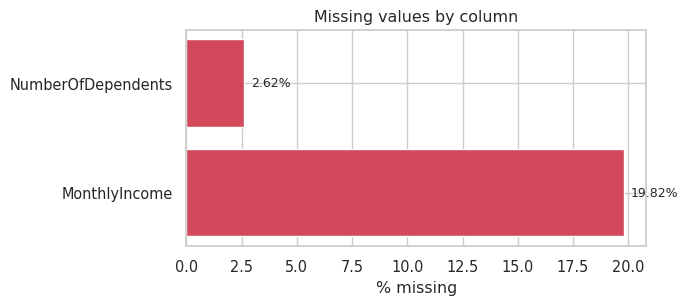

In [17]:
fig, ax = plt.subplots(figsize=(7, 3.2))
if len(na_table):
    ax.barh(na_table.index, na_table["missing_%"], color=PALETTE[1])
    for i, v in enumerate(na_table["missing_%"]):
        ax.text(v + 0.3, i, f"{v}%", va="center", fontsize=9)
    ax.set_xlabel("% missing")
    ax.set_title("Missing values by column")
else:
    ax.text(0.5, 0.5, "No missing values", ha="center")
plt.tight_layout()
plt.show()


**Finding:** two columns have missing data — `MonthlyIncome` (~19.8%) and
`NumberOfDependents` (~2.6%). Both are plausible "not reported" fields rather
than random glitches; we test whether they're missing-at-random in Section 8.

### [GMSC] 2.2 Duplicates

In [18]:
exact_dupes = df.duplicated().sum()
dupes_ignoring_id = df.drop(columns=["ID"]).duplicated().sum()
print(f"Fully identical rows (incl. ID): {exact_dupes}")
print(f"Identical on every column EXCEPT the ID index: {dupes_ignoring_id}")


Fully identical rows (incl. ID): 0
Identical on every column EXCEPT the ID index: 609


**Finding:** there are no duplicate `ID`s (it's just a row index), but
**609 rows are duplicated on every real feature** once `ID` is excluded.
These are worth flagging for modeling (they can leak between train/test splits)
even though we won't drop them in this EDA pass.

### [GMSC] 2.3 Impossible / sentinel values

In [19]:
print("age == 0 rows:", (df["age"] == 0).sum())
print("age range:", df["age"].min(), "-", df["age"].max())
df[df["age"] == 0]


age == 0 rows: 1
age range: 0 - 109


,ID,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
65695,65696,0,1.0000,0,1,0.4369,"6,000.0000",6,0,2,0,2.0000


In [20]:
late_cols = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
]

sentinel_mask = (df[late_cols] >= 96).any(axis=1)
print(f"Rows containing a 96/98 sentinel code in any 'DaysPastDue' column: {sentinel_mask.sum()}")

for c in late_cols:
    vc = df[c].value_counts().sort_index(ascending=False).head(6)
    print(f"\nTop values in {c}:")
    print(vc)


Rows containing a 96/98 sentinel code in any 'DaysPastDue' column: 269

Top values in NumberOfTime30-59DaysPastDueNotWorse:
NumberOfTime30-59DaysPastDueNotWorse
98    264
96      5
13      1
12      2
11      1
10      4
Name: count, dtype: int64

Top values in NumberOfTime60-89DaysPastDueNotWorse:
NumberOfTime60-89DaysPastDueNotWorse
98    264
96      5
11      1
9       1
8       2
7       9
Name: count, dtype: int64

Top values in NumberOfTimes90DaysLate:
NumberOfTimes90DaysLate
98    264
96      5
17      1
15      2
14      2
13      4
Name: count, dtype: int64


In [21]:
print("Default rate for sentinel rows (>=96):", df.loc[sentinel_mask, "SeriousDlqin2yrs"].mean().round(4))
print("Default rate overall                    :", df["SeriousDlqin2yrs"].mean().round(4))
print("MonthlyIncome missing rate in sentinel rows:", df.loc[sentinel_mask, "MonthlyIncome"].isnull().mean().round(4))


Default rate for sentinel rows (>=96): 0.5465
Default rate overall                    : 0.0668
MonthlyIncome missing rate in sentinel rows: 0.4498


**Finding — important data quality issue:** 269 rows (≈0.18%) carry the values
**96 or 98** in all three "days past due" columns simultaneously. These are not
real counts of 96–98 late payments; they look like **coded/sentinel values**
(a common artifact of this specific Kaggle dataset). This small subgroup has a
**default rate of ~55% vs. ~6.7% overall** — an 8x lift — and much higher
missingness in `MonthlyIncome`. This group should be handled explicitly
(flag as a separate category or cap/clip) rather than treated as ordinary
large counts, or it will distort any distance/linear-based model.

In [22]:
print("RevolvingUtilizationOfUnsecuredLines > 1  :", (df["RevolvingUtilizationOfUnsecuredLines"] > 1).sum())
print("RevolvingUtilizationOfUnsecuredLines > 10 :", (df["RevolvingUtilizationOfUnsecuredLines"] > 10).sum())
print("max value                                  :", df["RevolvingUtilizationOfUnsecuredLines"].max())
print()
print("DebtRatio > 1  :", (df["DebtRatio"] > 1).sum())
print("DebtRatio > 10 :", (df["DebtRatio"] > 10).sum())
print("max value      :", df["DebtRatio"].max())


RevolvingUtilizationOfUnsecuredLines > 1  : 3321
RevolvingUtilizationOfUnsecuredLines > 10 : 241
max value                                  : 50708.0

DebtRatio > 1  : 35137
DebtRatio > 10 : 28877
max value      : 329664.0


**Finding:** `RevolvingUtilizationOfUnsecuredLines` is conceptually a ratio
that should sit in **[0, 1]**, yet it reaches **50,708** and 3,321 rows exceed 1.
`DebtRatio` shows the same pattern (max ≈ 329,664; 35,137 rows > 1). These are
almost certainly data-entry errors or unit mismatches, not genuine values, and
they will dominate any mean/std-based scaling unless winsorized, log-transformed,
or capped.

## [GMSC] 3. Target variable — class balance

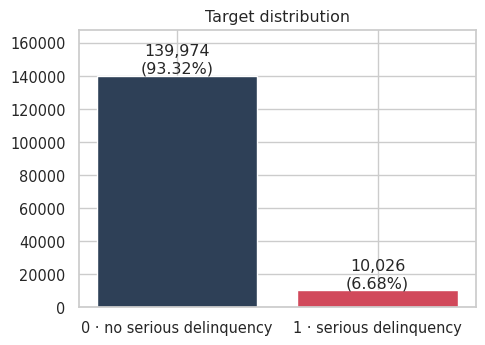

Positive (default) rate: 6.68%
Imbalance ratio: 14.0 : 1


In [23]:
target = "SeriousDlqin2yrs"
vc = df[target].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(5, 3.6))
bars = ax.bar(["0 · no serious delinquency", "1 · serious delinquency"], vc.values,
              color=[PALETTE[0], PALETTE[1]])
for b, v in zip(bars, vc.values):
    ax.text(b.get_x() + b.get_width()/2, v, f"{v:,}\n({v/len(df):.2%})",
            ha="center", va="bottom")
ax.set_ylim(0, vc.max()*1.2)
ax.set_title("Target distribution")
plt.tight_layout()
plt.show()

print(f"Positive (default) rate: {df[target].mean():.2%}")
print(f"Imbalance ratio: {(1-df[target].mean())/df[target].mean():.1f} : 1")


**Finding:** the dataset is **strongly imbalanced** — only **6.68%** of
borrowers defaulted. Accuracy alone will be a misleading metric; ROC-AUC /
PR-AUC, class weighting, or resampling should be used downstream.

## [GMSC] 4. Univariate analysis

Distribution of every feature, using a log-scale where the raw scale is too
skewed to read (utilization, debt ratio, income).

In [24]:
feature_cols = [c for c in df.columns if c not in ["ID", target]]
df[feature_cols].describe().T


,count,mean,std,min,25%,50%,75%,max
RevolvingUtilizationOfUnsecuredLines,"150,000.0000",6.0484,249.7554,0.0000,0.0299,0.1542,0.5590,"50,708.0000"
age,"150,000.0000",52.2952,14.7719,0.0000,41.0000,52.0000,63.0000,109.0000
NumberOfTime30-59DaysPastDueNotWorse,"150,000.0000",0.4210,4.1928,0.0000,0.0000,0.0000,0.0000,98.0000
DebtRatio,"150,000.0000",353.0051,"2,037.8185",0.0000,0.1751,0.3665,0.8683,"329,664.0000"
MonthlyIncome,"120,269.0000","6,670.2212","14,384.6742",0.0000,"3,400.0000","5,400.0000","8,249.0000","3,008,750.0000"
NumberOfOpenCreditLinesAndLoans,"150,000.0000",8.4528,5.1460,0.0000,5.0000,8.0000,11.0000,58.0000
NumberOfTimes90DaysLate,"150,000.0000",0.2660,4.1693,0.0000,0.0000,0.0000,0.0000,98.0000
NumberRealEstateLoansOrLines,"150,000.0000",1.0182,1.1298,0.0000,0.0000,1.0000,2.0000,54.0000
NumberOfTime60-89DaysPastDueNotWorse,"150,000.0000",0.2404,4.1552,0.0000,0.0000,0.0000,0.0000,98.0000
NumberOfDependents,"146,076.0000",0.7572,1.1151,0.0000,0.0000,0.0000,1.0000,20.0000


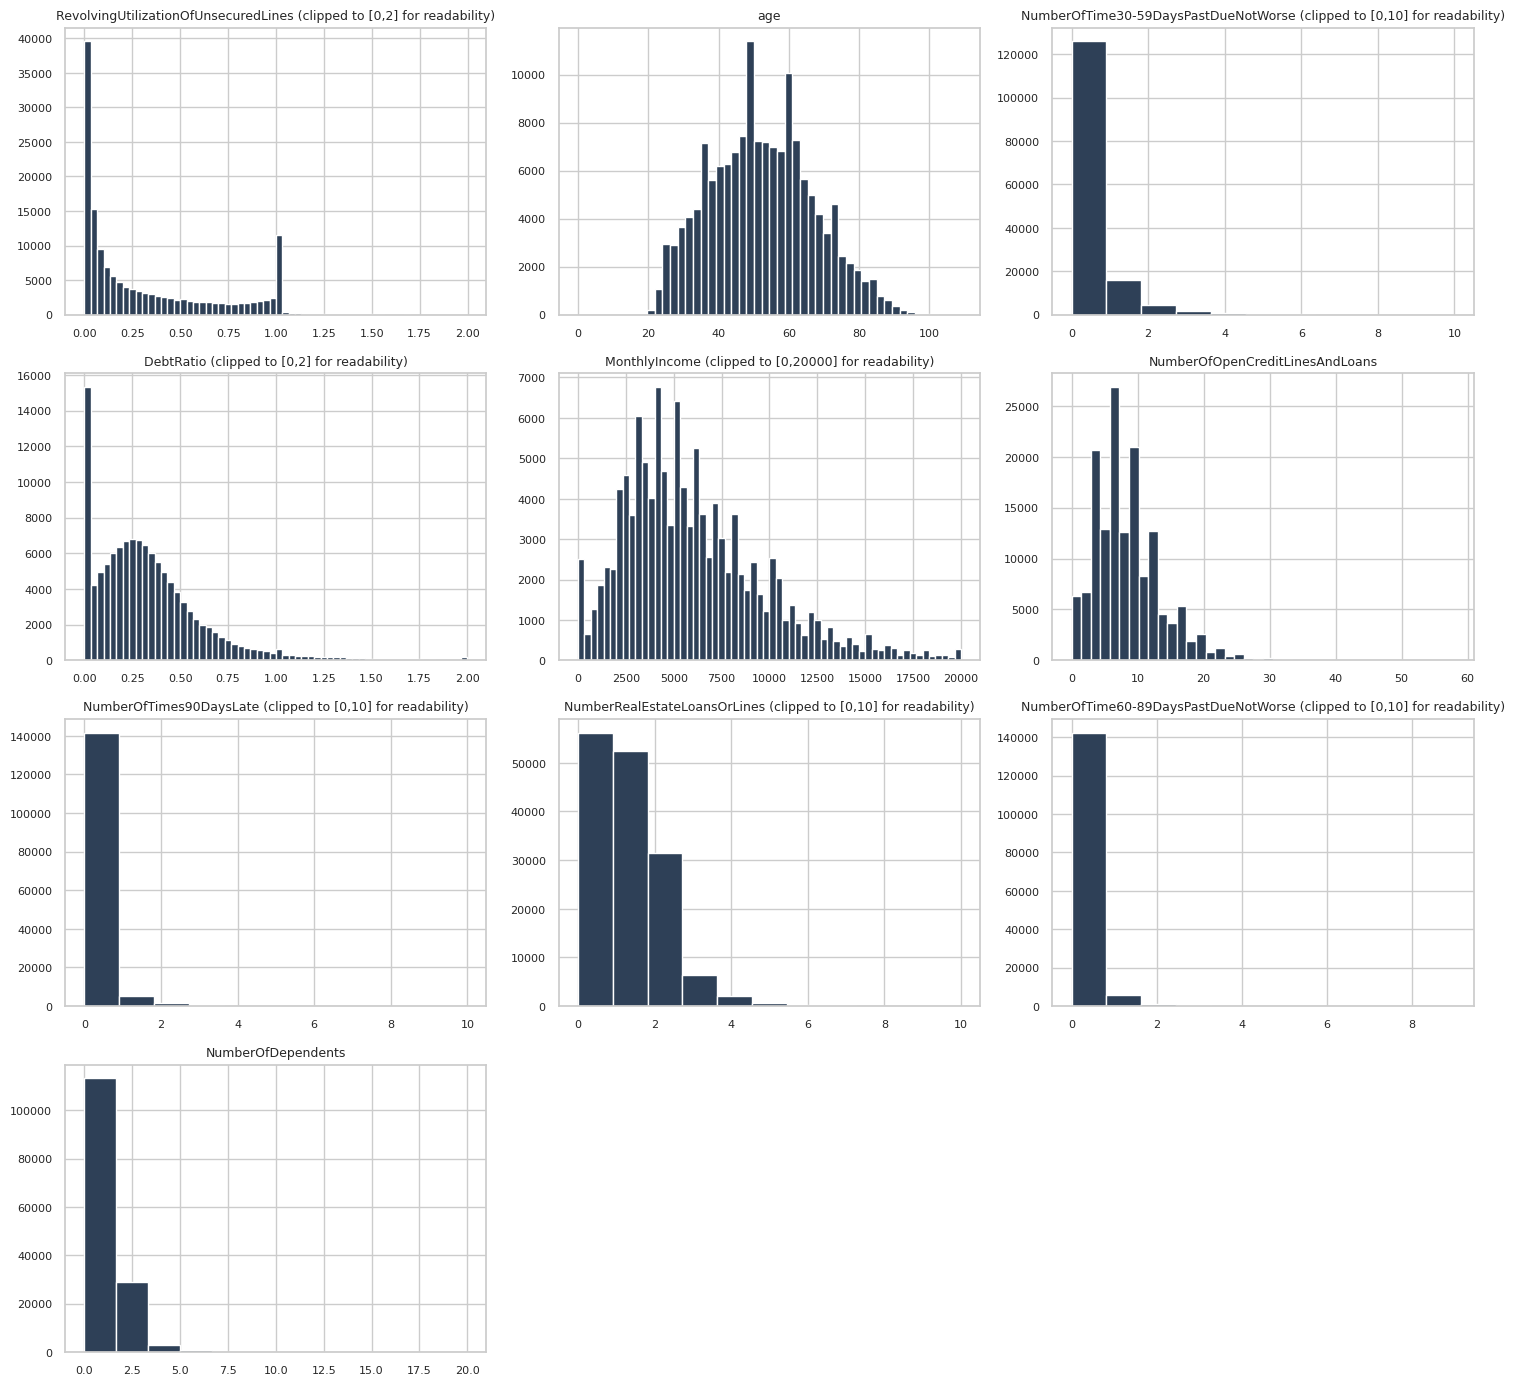

In [25]:
fig, axes = plt.subplots(4, 3, figsize=(15, 14))
axes = axes.ravel()

plot_specs = {
    "RevolvingUtilizationOfUnsecuredLines": dict(clip=(0, 2), bins=60),
    "age": dict(clip=None, bins=50),
    "NumberOfTime30-59DaysPastDueNotWorse": dict(clip=(0, 10), bins=11),
    "DebtRatio": dict(clip=(0, 2), bins=60),
    "MonthlyIncome": dict(clip=(0, 20000), bins=60),
    "NumberOfOpenCreditLinesAndLoans": dict(clip=None, bins=40),
    "NumberOfTimes90DaysLate": dict(clip=(0, 10), bins=11),
    "NumberRealEstateLoansOrLines": dict(clip=(0, 10), bins=11),
    "NumberOfTime60-89DaysPastDueNotWorse": dict(clip=(0, 10), bins=11),
    "NumberOfDependents": dict(clip=None, bins=12),
}

for ax, col in zip(axes, feature_cols):
    spec = plot_specs.get(col, dict(clip=None, bins=40))
    data = df[col].dropna()
    if spec["clip"] is not None:
        lo, hi = spec["clip"]
        data = data[(data >= lo) & (data <= hi)]
        suffix = f" (clipped to [{lo},{hi}] for readability)"
    else:
        suffix = ""
    ax.hist(data, bins=spec["bins"], color=PALETTE[0], edgecolor="white")
    ax.set_title(col + suffix, fontsize=9)
    ax.tick_params(labelsize=8)

for ax in axes[len(feature_cols):]:
    ax.axis("off")

plt.tight_layout()
plt.show()


**Findings:**
- `age` is roughly bell-shaped, centered in the 40s-50s, with one impossible `age=0` row.
- `RevolvingUtilizationOfUnsecuredLines` and `DebtRatio` are extremely right-skewed with a long tail of implausible outliers (see §2.3).
- The three "days past due" counters are heavily zero-inflated (most borrowers have 0 late payments) with a small sentinel spike at 96/98.
- `MonthlyIncome` is right-skewed, typical of income data — a log transform will help most models.
- `NumberOfDependents` and `NumberRealEstateLoansOrLines` are low-count discrete variables, also zero-inflated.

## [GMSC] 5. Outlier detection (boxplots + IQR rule)

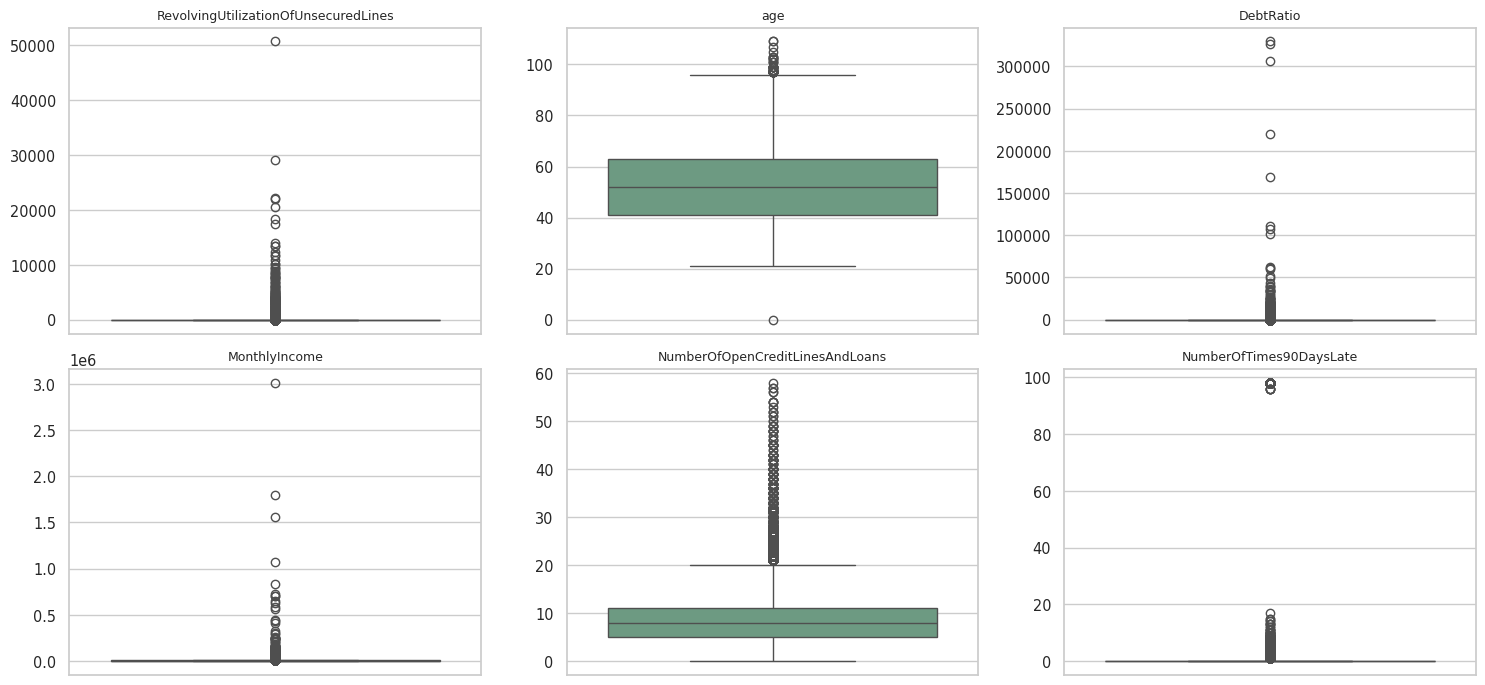

In [26]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
axes = axes.ravel()
box_cols = ["RevolvingUtilizationOfUnsecuredLines", "age", "DebtRatio",
            "MonthlyIncome", "NumberOfOpenCreditLinesAndLoans", "NumberOfTimes90DaysLate"]

for ax, col in zip(axes, box_cols):
    sns.boxplot(y=df[col].dropna(), ax=ax, color=PALETTE[2])
    ax.set_title(col, fontsize=9)
    ax.set_ylabel("")

plt.tight_layout()
plt.show()


In [27]:
def iqr_outlier_report(series, name):
    s = series.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    n_out = ((s < lo) | (s > hi)).sum()
    return {"feature": name, "q1": q1, "q3": q3, "IQR_low": lo, "IQR_high": hi,
            "n_outliers": n_out, "pct_outliers": round(n_out/len(s)*100, 2)}

report = pd.DataFrame([iqr_outlier_report(df[c], c) for c in feature_cols]).set_index("feature")
report.sort_values("pct_outliers", ascending=False)


,q1,q3,IQR_low,IQR_high,n_outliers,pct_outliers
feature,,,,,,
DebtRatio,0.1751,0.8683,-0.8647,1.9080,31311,20.8700
NumberOfTime30-59DaysPastDueNotWorse,0.0000,0.0000,0.0000,0.0000,23982,15.9900
NumberOfDependents,0.0000,1.0000,-1.5000,2.5000,13336,9.1300
NumberOfTimes90DaysLate,0.0000,0.0000,0.0000,0.0000,8338,5.5600
NumberOfTime60-89DaysPastDueNotWorse,0.0000,0.0000,0.0000,0.0000,7604,5.0700
MonthlyIncome,"3,400.0000","8,249.0000","-3,873.5000","15,522.5000",4879,4.0600
NumberOfOpenCreditLinesAndLoans,5.0000,11.0000,-4.0000,20.0000,3980,2.6500
NumberRealEstateLoansOrLines,0.0000,2.0000,-3.0000,5.0000,793,0.5300
RevolvingUtilizationOfUnsecuredLines,0.0299,0.5590,-0.7639,1.3528,763,0.5100


**Finding:** by the standard 1.5×IQR rule, `RevolvingUtilizationOfUnsecuredLines`,
`DebtRatio`, and the past-due counters show the highest outlier rates — consistent
with the sentinel-code and unit-error issues already identified above rather than
genuine extreme-but-valid customers.

## [GMSC] 6. Bivariate analysis — features vs. target

For each feature we compare the distribution/mean between defaulters (1) and
non-defaulters (0), and show the default rate across bins.

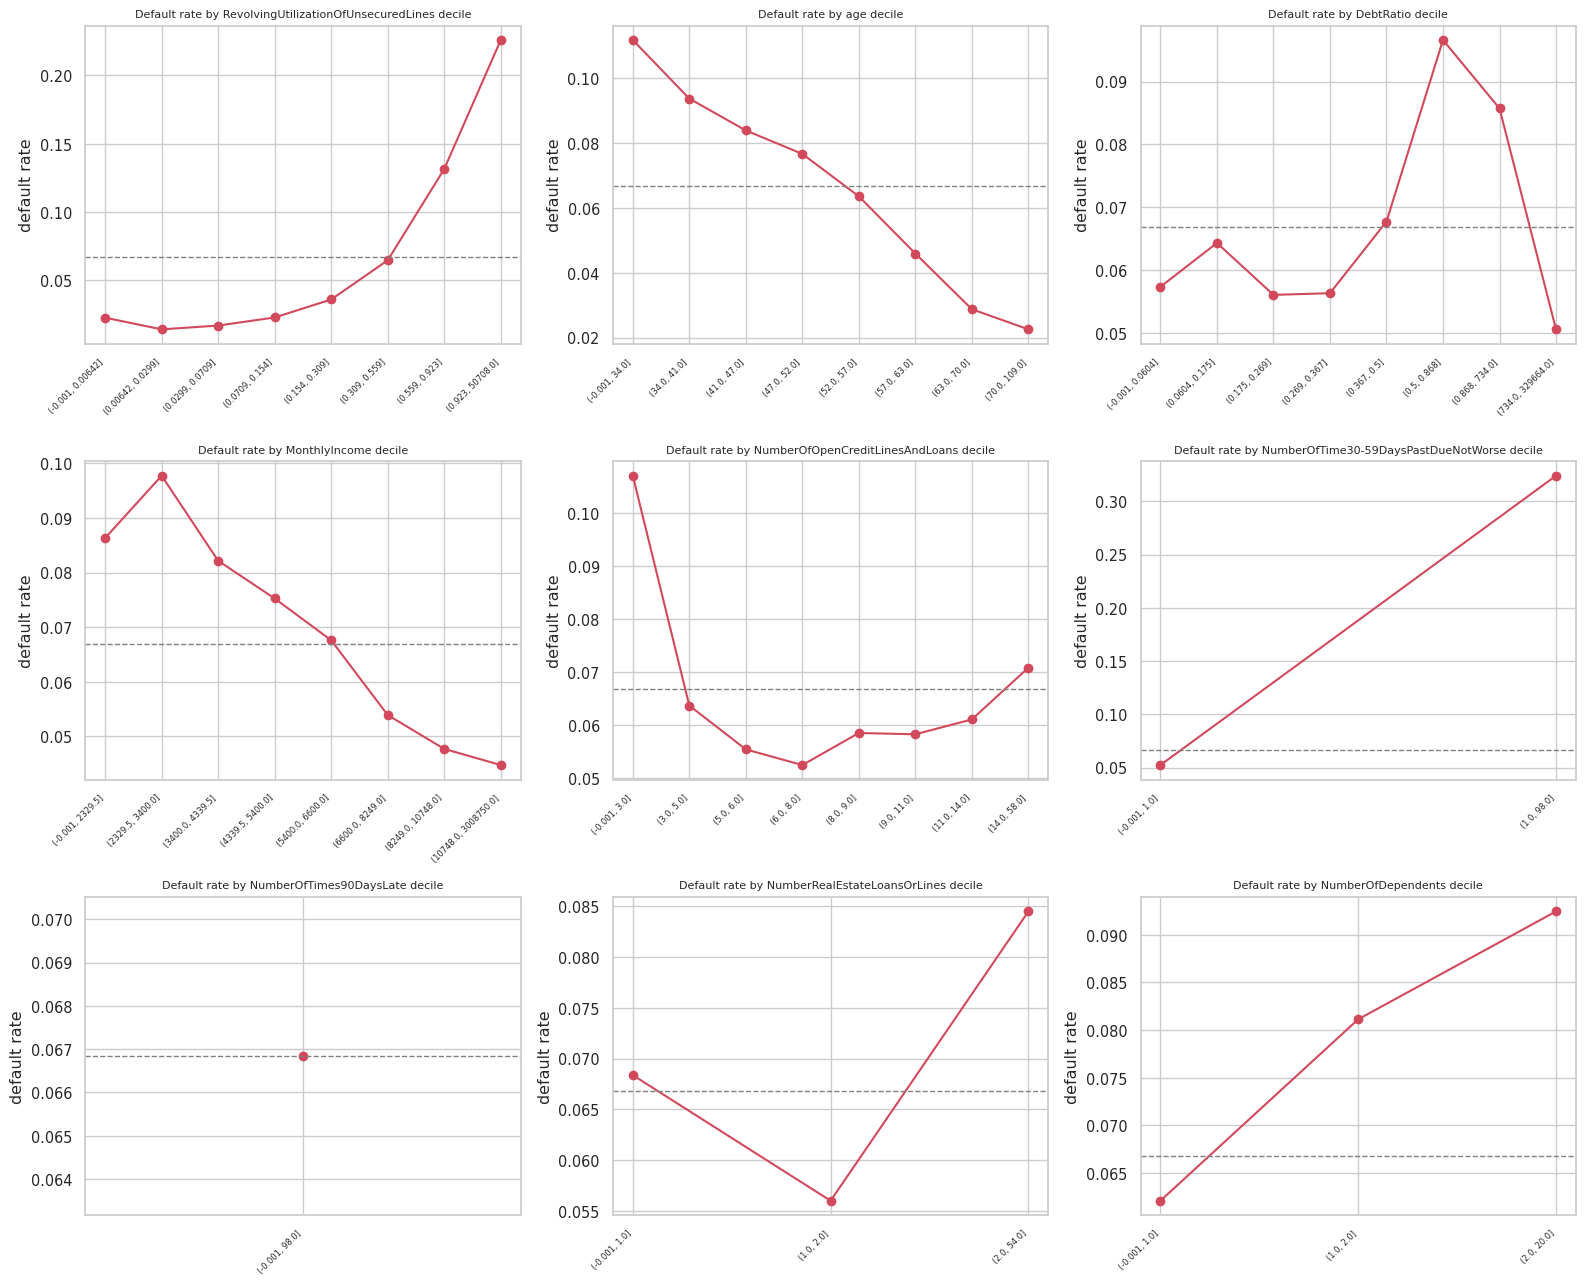

In [28]:
def default_rate_by_bin(data, col, target, bins=10, clip=None):
    d = data[[col, target]].dropna().copy()
    if clip is not None:
        d = d[(d[col] >= clip[0]) & (d[col] <= clip[1])]
    d["bin"] = pd.qcut(d[col], q=bins, duplicates="drop")
    out = d.groupby("bin", observed=True)[target].agg(["mean", "count"])
    out.columns = ["default_rate", "n"]
    return out

fig, axes = plt.subplots(3, 3, figsize=(16, 13))
axes = axes.ravel()

bivar_cols = ["RevolvingUtilizationOfUnsecuredLines", "age", "DebtRatio",
              "MonthlyIncome", "NumberOfOpenCreditLinesAndLoans",
              "NumberOfTime30-59DaysPastDueNotWorse", "NumberOfTimes90DaysLate",
              "NumberRealEstateLoansOrLines", "NumberOfDependents"]

for ax, col in zip(axes, bivar_cols):
    try:
        tab = default_rate_by_bin(df, col, target, bins=8)
        ax.plot(range(len(tab)), tab["default_rate"], marker="o", color=PALETTE[1])
        ax.set_xticks(range(len(tab)))
        ax.set_xticklabels([str(i) for i in tab.index], rotation=45, ha="right", fontsize=6)
    except Exception as e:
        ax.text(0.5, 0.5, f"n/a: {e}", ha="center", fontsize=7)
    ax.axhline(df[target].mean(), color="gray", linestyle="--", linewidth=1)
    ax.set_title(f"Default rate by {col} decile", fontsize=8)
    ax.set_ylabel("default rate")

plt.tight_layout()
plt.show()


**Findings (dashed line = overall base rate of 6.68%):**
- Default rate **rises sharply with age going down** — younger borrowers default noticeably more; it falls steadily into older age brackets.
- Default rate **increases monotonically** with the past-due counters and with `RevolvingUtilizationOfUnsecuredLines` — both behave exactly as expected of strong risk signals.
- `MonthlyIncome` shows a mild inverse relationship — lower income bands skew toward higher default.
- `NumberOfOpenCreditLinesAndLoans` and `NumberRealEstateLoansOrLines` show a much flatter/non-monotonic relationship — weaker standalone signal, may still interact with other features.

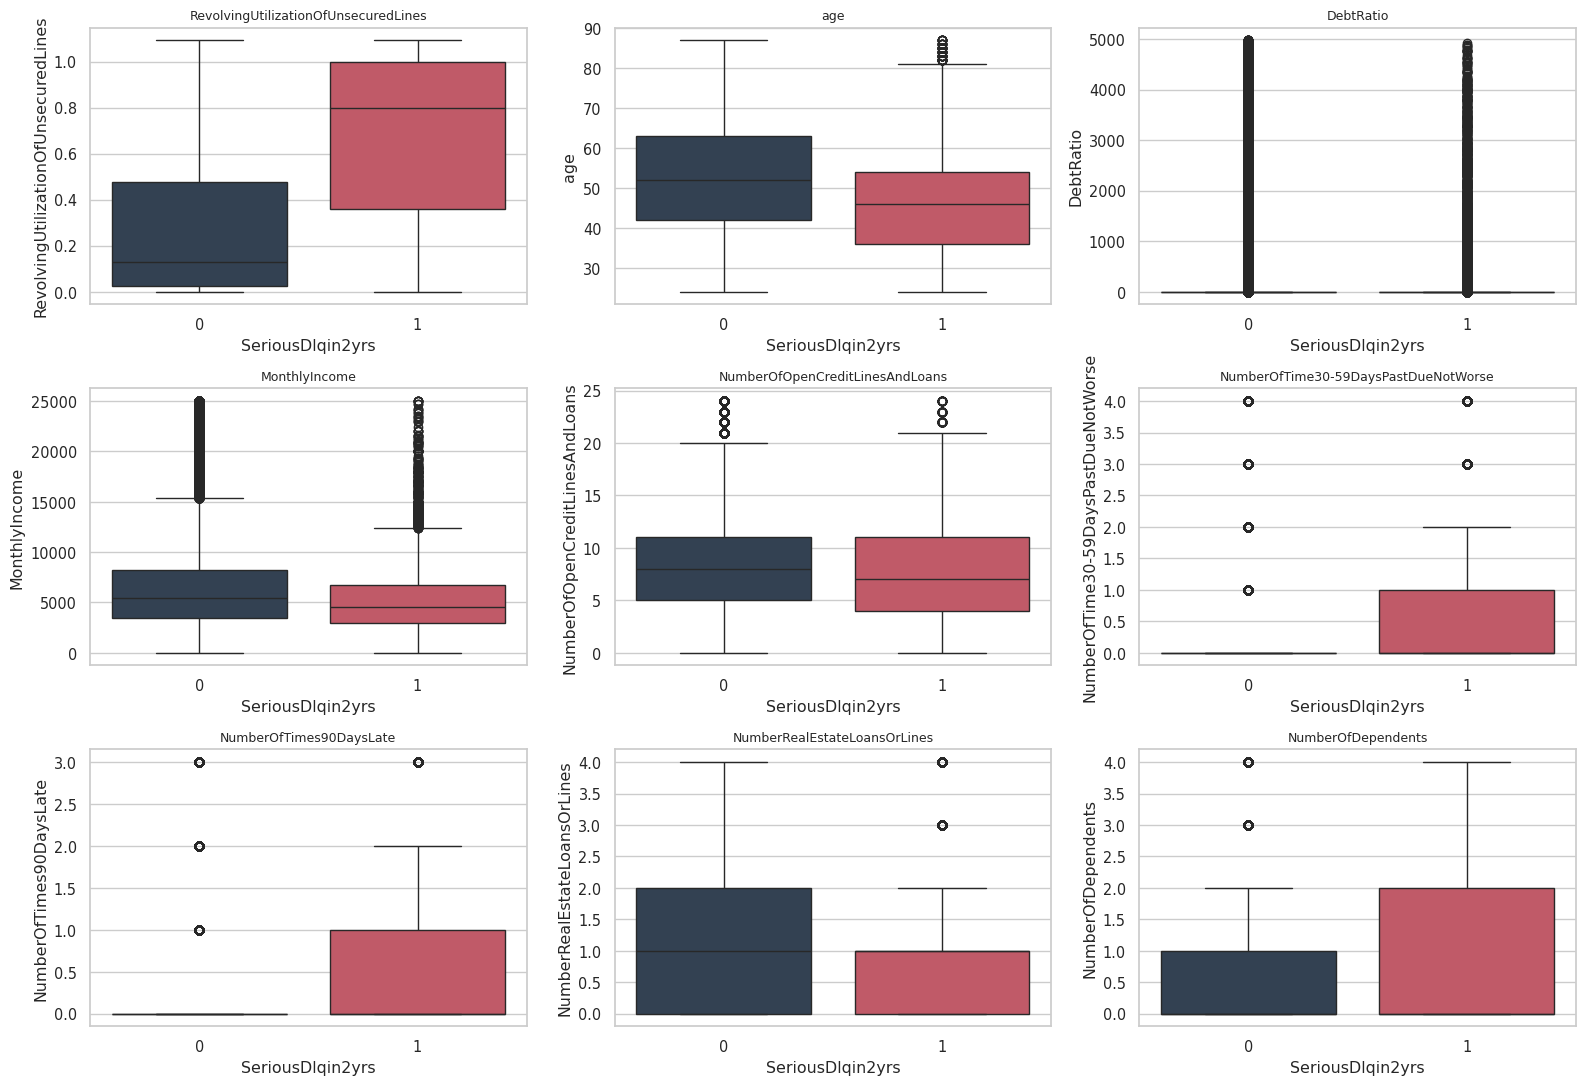

In [29]:
fig, axes = plt.subplots(3, 3, figsize=(16, 11))
axes = axes.ravel()

for ax, col in zip(axes, bivar_cols):
    d = df[[col, target]].dropna()
    lo, hi = d[col].quantile([0.01, 0.99])
    d = d[(d[col] >= lo) & (d[col] <= hi)]
    sns.boxplot(data=d, x=target, y=col, ax=ax, palette=[PALETTE[0], PALETTE[1]])
    ax.set_title(col, fontsize=9)
    ax.set_xlabel("SeriousDlqin2yrs")

plt.tight_layout()
plt.show()


## [GMSC] 7. Correlation & multivariate structure

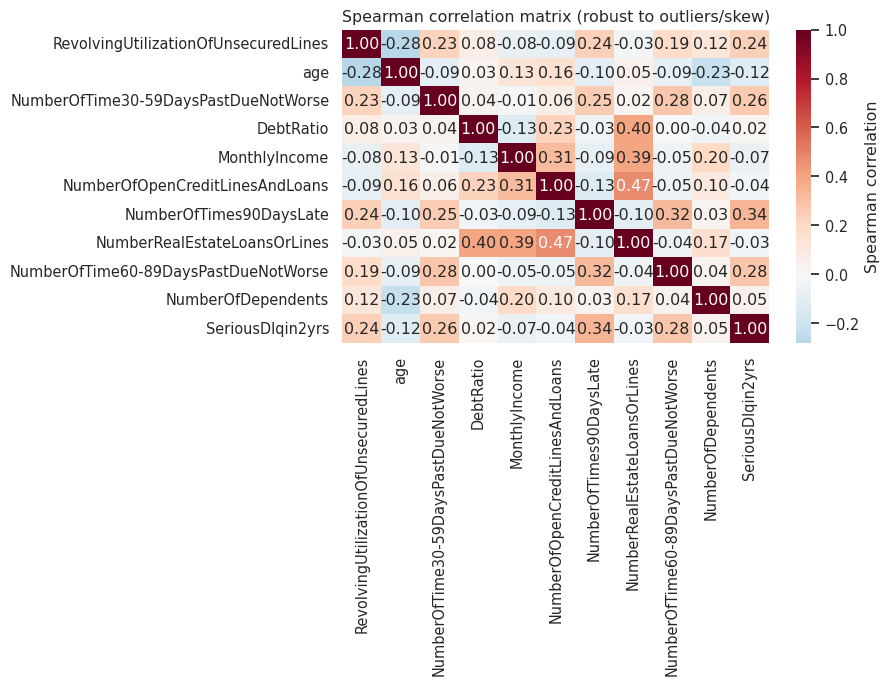

In [30]:
corr = df[feature_cols + [target]].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax,
            cbar_kws={"label": "Spearman correlation"})
ax.set_title("Spearman correlation matrix (robust to outliers/skew)")
plt.tight_layout()
plt.show()


In [31]:
corr_with_target = corr[target].drop(target).sort_values(key=abs, ascending=False)
corr_with_target.to_frame("spearman_corr_with_target")


,spearman_corr_with_target
NumberOfTimes90DaysLate,0.3423
NumberOfTime60-89DaysPastDueNotWorse,0.2771
NumberOfTime30-59DaysPastDueNotWorse,0.2574
RevolvingUtilizationOfUnsecuredLines,0.2404
age,-0.1170
MonthlyIncome,-0.0670
NumberOfDependents,0.0460
NumberOfOpenCreditLinesAndLoans,-0.0386
NumberRealEstateLoansOrLines,-0.0341
DebtRatio,0.0206


**Findings:**
- The three "days past due" counters are **highly correlated with each other**
  (they measure the same underlying behavior at different severities) and are
  the strongest correlates of the target — expected, since they are the most
  direct historical proxies for delinquency.
- `RevolvingUtilizationOfUnsecuredLines` is the single strongest standalone
  correlate with the target.
- `age` correlates negatively with the target (older ⇒ lower risk), and mildly
  negatively with the past-due counters too.
- `DebtRatio`, `MonthlyIncome`, `NumberOfOpenCreditLinesAndLoans`, and
  `NumberRealEstateLoansOrLines` show comparatively weak linear/rank correlation
  with the target on their own — they will likely help mainly through interactions
  or non-linear models rather than as strong solo predictors.

## [GMSC] 8. Missingness patterns — is data missing at random?

We test whether `MonthlyIncome` and `NumberOfDependents` are missing completely
at random, or whether missingness itself correlates with default risk (MNAR/MAR),
which matters for the correct imputation strategy.

In [32]:
df["MonthlyIncome_missing"] = df["MonthlyIncome"].isnull().astype(int)
df["NumberOfDependents_missing"] = df["NumberOfDependents"].isnull().astype(int)

for flag in ["MonthlyIncome_missing", "NumberOfDependents_missing"]:
    rate_missing = df.loc[df[flag] == 1, target].mean()
    rate_present = df.loc[df[flag] == 0, target].mean()
    print(f"{flag}: default rate when MISSING = {rate_missing:.2%}, "
          f"when PRESENT = {rate_present:.2%}")


MonthlyIncome_missing: default rate when MISSING = 5.61%, when PRESENT = 6.95%
NumberOfDependents_missing: default rate when MISSING = 4.56%, when PRESENT = 6.74%


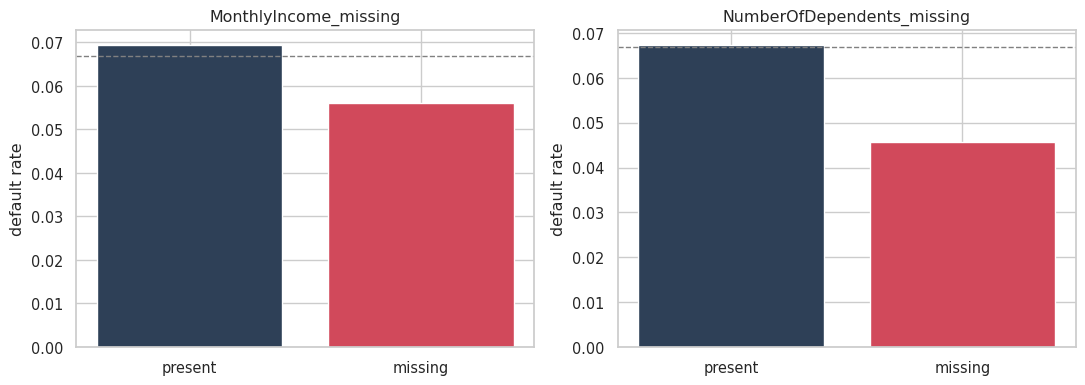

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, flag in zip(axes, ["MonthlyIncome_missing", "NumberOfDependents_missing"]):
    rates = df.groupby(flag)[target].mean()
    ax.bar(["present", "missing"], rates.values, color=[PALETTE[0], PALETTE[1]])
    ax.axhline(df[target].mean(), color="gray", linestyle="--", linewidth=1)
    ax.set_title(flag)
    ax.set_ylabel("default rate")
plt.tight_layout()
plt.show()


**Finding:** default rate is **meaningfully higher when `MonthlyIncome` is
missing** than when it's reported — this points to **MAR/MNAR rather than
MCAR**, i.e. missingness itself carries signal. A missing-value indicator
feature (kept alongside imputed values) is recommended rather than silent
mean/median imputation.

## [GMSC] 9. Summary of key findings & recommendations

**Data quality issues found**
1. One row has `age = 0` (impossible) — should be treated as missing/dropped.
2. 269 rows carry sentinel codes **96/98** across all three "days past due"
   columns — a distinct high-risk subgroup (≈55% default rate) that should be
   flagged rather than treated as literal counts.
3. `RevolvingUtilizationOfUnsecuredLines` and `DebtRatio` contain extreme,
   almost certainly erroneous outliers (max values in the tens of thousands
   for what should be bounded ratios) — cap/winsorize or log-transform.
4. 609 rows are exact duplicates on every real feature (different `ID` only) —
   worth deduplicating before train/test splitting to avoid leakage.
5. `MonthlyIncome` (~19.8%) and `NumberOfDependents` (~2.6%) have missing
   values, and missingness is **not random** — it correlates with higher
   default risk, so an explicit "is-missing" indicator should be kept.

**Target & modeling implications**
- Severe class imbalance (6.68% positive) → use ROC-AUC/PR-AUC, class weights,
  or resampling; avoid plain accuracy.
- Strongest predictors: the past-due counters and revolving utilization;
  age is protective; income, debt ratio, and credit-line counts are weaker
  standalone signals but may add value through interactions or tree-based
  models that handle non-linearities and outliers more gracefully than
  linear models.
- Recommended preprocessing before modeling: cap/winsorize utilization and
  debt ratio, isolate or flag the 96/98 sentinel rows, impute income/dependents
  with a missing-indicator retained, and consider log-transforming income.


## [GMSC] Part 3 -- Feature Engineering

`build_gmsc_features` is self-contained: it reads `GMSC_PATH` and performs its own cleaning steps (income-missing flag, debt-ratio fix, 96/98 placeholder fix, age fix, duplicate flag, dependents fill) that mirror Part 2 but follow the FE spec's exact rules, plus every derived feature required for modeling. This is independent of the manually-cleaned `df` from Part 2 (which stays available above for inspection).

In [34]:
def build_gmsc_features(path: str) -> pd.DataFrame:
    df = pd.read_csv(path)

    # -- duplicate review: flag rows identical except the row-id column ----
    id_like_cols = [c for c in df.columns if c.startswith("Unnamed")]
    dup_check_cols = [c for c in df.columns if c not in id_like_cols]
    duplicate_flag = df.duplicated(subset=dup_check_cols, keep=False).astype(int)
    df = df.drop(columns=id_like_cols)

    out = pd.DataFrame(index=df.index)
    out["duplicate_flag"] = duplicate_flag.values

    # -- income_missing_flag (before any use of income) --------------------
    out["income_missing_flag"] = df["MonthlyIncome"].isna().astype(int)

    # income: REAL
    out["income"] = df["MonthlyIncome"]

    # -- debt_ratio fix: NaN when income missing/0; flag outlier > 5 -------
    valid_income_mask = out["income"].notna() & (out["income"] > 0)
    debt_ratio_clean = df["DebtRatio"].where(valid_income_mask)
    out["derived_debt_ratio_outlier"] = (df["DebtRatio"] > 5).astype(int)

    # -- placeholder code fix: 96/98 in past-due cols -> NaN + flag --------
    past_due_cols = [
        "NumberOfTime30-59DaysPastDueNotWorse",
        "NumberOfTime60-89DaysPastDueNotWorse",
        "NumberOfTimes90DaysLate",
    ]
    placeholder_mask = pd.Series(False, index=df.index)
    past_due_clean = pd.DataFrame(index=df.index)
    for col in past_due_cols:
        is_placeholder = df[col].isin([96, 98])
        placeholder_mask = placeholder_mask | is_placeholder
        past_due_clean[col] = df[col].where(~is_placeholder)
    out["derived_placeholder_code_flag"] = placeholder_mask.astype(int)

    # -- age fix: 0 -> NaN ---------------------------------------------------
    out["age"] = df["age"].replace(0, np.nan)

    # -- dependents_missing_flag + fill(0) ----------------------------------
    out["dependents_missing_flag"] = df["NumberOfDependents"].isna().astype(int)
    out["dependents"] = df["NumberOfDependents"].fillna(0)

    # -- derived_late_count / derived_late_severity (post placeholder-fix) --
    out["derived_late_count"] = past_due_clean.sum(axis=1, skipna=True)
    out["derived_late_severity"] = (
        past_due_clean["NumberOfTime30-59DaysPastDueNotWorse"].fillna(0) * 1
        + past_due_clean["NumberOfTime60-89DaysPastDueNotWorse"].fillna(0) * 2
        + past_due_clean["NumberOfTimes90DaysLate"].fillna(0) * 3
    )
    # late_payments: harmonized column = the cleaned late count
    out["late_payments"] = out["derived_late_count"]

    # -- derived_obligations: debt_ratio * income, only when income>0 AND
    # debt_ratio<=5 (per FE.pdf rule) --------------------------------------
    obligations_mask = valid_income_mask & (df["DebtRatio"] <= 5)
    out["derived_obligations"] = np.where(
        obligations_mask, df["DebtRatio"] * out["income"], np.nan
    )
    # monthly_debt_payment: PROXY = derived_obligations (harmonized name)
    out["monthly_debt_payment"] = out["derived_obligations"]
    out["monthly_debt_payment_is_proxy"] = 1

    # derived_expense_ratio = cleaned debt ratio
    out["derived_expense_ratio"] = debt_ratio_clean

    # derived_monthly_surplus = income - obligations
    out["derived_monthly_surplus"] = out["income"] - out["derived_obligations"]
    out["savings"] = out["derived_monthly_surplus"]
    out["savings_is_proxy"] = 1

    # derived_overspend_flag = debt_ratio > 1 (cleaned)
    out["derived_overspend_flag"] = (debt_ratio_clean > 1).astype(int)

    # derived_utilization_capped = min(utilization, 1) + outlier flag
    util = df["RevolvingUtilizationOfUnsecuredLines"]
    out["derived_utilization_capped"] = util.clip(upper=1)
    out["derived_utilization_outlier_flag"] = (util > 1).astype(int)
    out["revolving_utilization_ref"] = util

    # derived_log_income = log1p(income)
    out["derived_log_income"] = np.log1p(out["income"].clip(lower=0))

    # debt: MISSING (no outstanding-balance dollar figure exists in GMSC)
    out["debt"] = np.nan

    # expenses: MISSING (no separate living-expense figure in GMSC)
    out["expenses"] = np.nan

    # rent: MISSING
    out["rent"] = np.nan

    # income_stability: MISSING (single snapshot, no history)
    out["income_stability"] = np.nan

    # month: MISSING (no time dimension in GMSC)
    out["month"] = np.nan

    out["target"] = df["SeriousDlqin2yrs"]
    out["source_dataset"] = "gmsc"
    return out


In [35]:
gmsc = build_gmsc_features(GMSC_PATH)
print("GMSC feature shape:", gmsc.shape)
gmsc.head()


GMSC feature shape: (150000, 30)


,duplicate_flag,income_missing_flag,income,derived_debt_ratio_outlier,derived_placeholder_code_flag,age,dependents_missing_flag,dependents,derived_late_count,derived_late_severity,late_payments,derived_obligations,monthly_debt_payment,monthly_debt_payment_is_proxy,derived_expense_ratio,derived_monthly_surplus,savings,savings_is_proxy,derived_overspend_flag,derived_utilization_capped,derived_utilization_outlier_flag,revolving_utilization_ref,derived_log_income,debt,expenses,rent,income_stability,month,target,source_dataset
0,0,0,"9,120.0000",0,0,45.0000,0,2.0000,2.0000,2.0000,2.0000,"7,323.1970","7,323.1970",1,0.8030,"1,796.8030","1,796.8030",1,0,0.7661,0,0.7661,9.1183,NaN,NaN,NaN,NaN,NaN,1,gmsc
1,0,0,"2,600.0000",0,0,40.0000,0,1.0000,0.0000,0.0000,0.0000,316.8781,316.8781,1,0.1219,"2,283.1219","2,283.1219",1,0,0.9572,0,0.9572,7.8637,NaN,NaN,NaN,NaN,NaN,0,gmsc
2,0,0,"3,042.0000",0,0,38.0000,0,0.0000,2.0000,4.0000,2.0000,258.9149,258.9149,1,0.0851,"2,783.0851","2,783.0851",1,0,0.6582,0,0.6582,8.0206,NaN,NaN,NaN,NaN,NaN,0,gmsc
3,0,0,"3,300.0000",0,0,30.0000,0,0.0000,0.0000,0.0000,0.0000,118.9640,118.9640,1,0.0360,"3,181.0360","3,181.0360",1,0,0.2338,0,0.2338,8.1020,NaN,NaN,NaN,NaN,NaN,0,gmsc
4,0,0,"63,588.0000",0,0,49.0000,0,0.0000,1.0000,1.0000,1.0000,"1,584.9751","1,584.9751",1,0.0249,"62,003.0249","62,003.0249",1,0,0.9072,0,0.9072,11.0602,NaN,NaN,NaN,NaN,NaN,0,gmsc


## [GMSC] Part 4 -- Train / test split

In [36]:
from sklearn.model_selection import train_test_split

TEST_SIZE = 0.2
RANDOM_STATE = 42

# GMSC: one row per client -> plain stratified split on the target
gmsc_train, gmsc_test = train_test_split(
    gmsc,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=gmsc["target"],
)

print("GMSC train:", gmsc_train.shape, " test:", gmsc_test.shape)
print("GMSC train target rate:", round(gmsc_train["target"].mean(), 4),
      "| test target rate:", round(gmsc_test["target"].mean(), 4))


GMSC train: (120000, 30)  test: (30000, 30)
GMSC train target rate: 0.0668 | test target rate: 0.0668


## [GMSC] Part 5 -- Save + download

In [37]:
gmsc.to_csv("gmsc_target_features.csv", index=False)
gmsc_train.to_csv("gmsc_train.csv", index=False)
gmsc_test.to_csv("gmsc_test.csv", index=False)

_OUT_FILES = ["gmsc_target_features.csv", "gmsc_train.csv", "gmsc_test.csv"]

try:
    from google.colab import files as _files
    for _f in _OUT_FILES:
        _files.download(_f)
except ImportError:
    print("Saved locally:", ", ".join(_OUT_FILES))


## [GMSC] Part 6 -- Preprocessing Pipeline + Baseline (Logistic Regression)  

In [38]:
# 1. Define Target and Feature Groups
TARGET = "target"

CONT_COLS = [
    "age",
    "derived_log_income",
    "derived_obligations",
    "derived_monthly_surplus",
    "derived_expense_ratio",
    "derived_utilization_capped",
]

COUNT_COLS = [
    "dependents",
    "derived_late_count",
    "derived_late_severity",
]

FLAG_COLS = [
    "income_missing_flag",
    "dependents_missing_flag",
    "derived_placeholder_code_flag",
    "derived_debt_ratio_outlier",
    "derived_overspend_flag",
    "derived_utilization_outlier_flag",
]

NUMERIC_COLS = CONT_COLS + COUNT_COLS
FEATURE_COLS = NUMERIC_COLS + FLAG_COLS

# 2. Extract Training Features and Target
X_train = gmsc_train[FEATURE_COLS].copy()
y_train = gmsc_train[TARGET].astype(int).copy()

# 3. Simple Outlier Capping (1st and 99th percentiles)
lower_limits = X_train[NUMERIC_COLS].quantile(0.01)
upper_limits = X_train[NUMERIC_COLS].quantile(0.99)
X_train[NUMERIC_COLS] = X_train[NUMERIC_COLS].clip(lower=lower_limits, upper=upper_limits, axis=1)

print("Features selected and outliers clipped successfully.")

Features selected and outliers clipped successfully.


### [GMSC] 2. Preprocessing & Baseline Pipeline
Construct a `ColumnTransformer` to impute missing values using median statistics and scale numeric features, while passing binary flags unchanged. Combine preprocessing with a class-balanced `LogisticRegression` baseline.

In [39]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Numerical Pipeline: Median Imputation + Standard Scaling
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Combine Preprocessing: Transform numerical features and pass flags unchanged
preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_pipe, NUMERIC_COLS),
        ("flags", "passthrough", FLAG_COLS)
    ]
)

# Full Baseline Pipeline with Class Balancing
baseline_model = Pipeline([
    ("preprocess", preprocessor),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42))
])

### [GMSC] 3. Cross-Validation Evaluation
Evaluate the baseline using 5-fold Stratified Cross-Validation. Given the severe class imbalance, focus primarily on PR-AUC (Average Precision) alongside ROC-AUC.

In [40]:
from sklearn.model_selection import StratifiedKFold, cross_validate
import numpy as np

# 5-Fold Stratified Split to preserve class ratio
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Evaluate Baseline using PR-AUC (Average Precision) and ROC-AUC
cv_results = cross_validate(
    baseline_model,
    X_train,
    y_train,
    cv=cv,
    scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"},
    n_jobs=-1
)

# Display Cross-Validation Performance
print("=== Cross-Validation Results ===")
print("PR-AUC  :", round(cv_results["test_pr_auc"].mean(), 4))
print("ROC-AUC :", round(cv_results["test_roc_auc"].mean(), 4))

=== Cross-Validation Results ===
PR-AUC  : 0.3888
ROC-AUC : 0.8561


### [GMSC] 4. Final Fit and Feature Interpretability
Fit the pipeline on the full training dataset and extract model coefficients to evaluate feature directionality and impact on default probability.

In [41]:
import pandas as pd

# 1. Fit full baseline on the complete training set
baseline_model.fit(X_train, y_train)

# 2. Extract feature names and model coefficients
feature_names = baseline_model.named_steps["preprocess"].get_feature_names_out()
coefficients = baseline_model.named_steps["clf"].coef_[0]

# 3. Format and sort by impact on default risk
coef_summary = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
}).sort_values(by="Coefficient", ascending=False)

display(coef_summary)

,Feature,Coefficient
11,flags__derived_placeholder_code_flag,2.5729
5,num__derived_utilization_capped,0.6398
8,num__derived_late_severity,0.4476
13,flags__derived_overspend_flag,0.3760
14,flags__derived_utilization_outlier_flag,0.3592
7,num__derived_late_count,0.3403
2,num__derived_obligations,0.1867
12,flags__derived_debt_ratio_outlier,0.1588
1,num__derived_log_income,0.0664
6,num__dependents,0.0208


### [GMSC] 5. Export Pipeline Artifacts
Save the fitted preprocessor, full baseline model, and column schema for downstream modeling and production serving.

In [42]:
import joblib

# Fit baseline on all training data
baseline_model.fit(X_train, y_train)

# Save preprocessor and complete baseline model for the team
joblib.dump(baseline_model.named_steps["preprocess"], "gmsc_preprocessor.joblib")
joblib.dump(baseline_model, "gmsc_baseline_model.joblib")

print("Pipeline artifacts saved successfully.")

Pipeline artifacts saved successfully.


## [GMSC] Part 7 -- XGBOOST MODEL + hyperparameter tuning

In [43]:
import numpy as np
import xgboost as xgb

# 1. Transform training features using our fitted preprocessor
X_train_transformed = baseline_model.named_steps["preprocess"].transform(X_train)

# 2. Calculate scale_pos_weight to handle class imbalance (Negatives / Positives)
num_negatives = (y_train == 0).sum()
num_positives = (y_train == 1).sum()
scale_pos_weight = num_negatives / num_positives

print(f"Negative samples: {num_negatives} | Positive samples: {num_positives}")
print(f"Calculated scale_pos_weight: {scale_pos_weight:.2f}")

Negative samples: 111979 | Positive samples: 8021
Calculated scale_pos_weight: 13.96


In [44]:
!pip install optuna

In [45]:
import optuna
from sklearn.metrics import average_precision_score
from sklearn.model_selection import StratifiedKFold
import warnings
warnings.filterwarnings("ignore")

# Make Optuna output cleaner and less verbose
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    # Search space for key XGBoost hyperparameters
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 400, step=50),
        "max_depth": trial.suggest_int("max_depth", 3, 7),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 8),
        "scale_pos_weight": scale_pos_weight,
        "random_state": 42,
        "eval_metric": "logloss",
        "n_jobs": -1
    }

    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    pr_scores = []

    for train_idx, val_idx in cv.split(X_train_transformed, y_train):
        X_tr, X_val = X_train_transformed[train_idx], X_train_transformed[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

        clf = xgb.XGBClassifier(**params)
        clf.fit(X_tr, y_tr, verbose=False)

        preds_prob = clf.predict_proba(X_val)[:, 1]
        score = average_precision_score(y_val, preds_prob)
        pr_scores.append(score)

    return np.mean(pr_scores)

# Run Optuna study (20 trials is fast and effective)
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=8)   # reduced for the sandbox run (original: 20)

print(f"Best Trial PR-AUC: {study.best_value:.4f}")
print("Best Hyperparameters:")
for k, v in study.best_params.items():
    print(f"  {k}: {v}")

Best Trial PR-AUC: 0.3961
Best Hyperparameters:
  n_estimators: 200
  max_depth: 4
  learning_rate: 0.03639607217564262
  subsample: 0.7019744390499102
  colsample_bytree: 0.9374050407656456
  min_child_weight: 3


In [46]:
from sklearn.model_selection import cross_validate

# Build best model using optimal parameters from Optuna
best_params = study.best_params
best_params["scale_pos_weight"] = scale_pos_weight
best_params["random_state"] = 42
best_params["eval_metric"] = "logloss"
best_params["n_jobs"] = -1

best_xgb = xgb.XGBClassifier(**best_params)

# 5-Fold Stratified Cross-Validation on the full training set
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

xgb_cv_results = cross_validate(
    best_xgb,
    X_train_transformed,
    y_train,
    cv=cv,
    scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"},
    n_jobs=-1
)

xgb_pr_mean = xgb_cv_results["test_pr_auc"].mean()
xgb_roc_mean = xgb_cv_results["test_roc_auc"].mean()

print(f"XGBoost PR-AUC  : {xgb_pr_mean:.4f}")
print(f"XGBoost ROC-AUC : {xgb_roc_mean:.4f}")

XGBoost PR-AUC  : 0.3973
XGBoost ROC-AUC : 0.8619


In [47]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score
from sklearn.model_selection import cross_val_predict

# 1. Generate out-of-fold probability predictions for both models
baseline_probs = cross_val_predict(baseline_model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
xgb_probs = cross_val_predict(best_xgb, X_train_transformed, y_train, cv=cv, method="predict_proba")[:, 1]

# 2. Convert probabilities to discrete binary predictions (using standard 0.5 threshold)
baseline_preds = (baseline_probs >= 0.5).astype(int)
xgb_preds = (xgb_probs >= 0.5).astype(int)

# 3. Calculate all evaluation metrics
def get_metrics(y_true, y_pred, y_prob):
    return {
        "PR-AUC (Target Metric)": average_precision_score(y_true, y_prob),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "Recall": recall_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "F1-Score": f1_score(y_true, y_pred),
        "Accuracy": accuracy_score(y_true, y_pred),
    }

# 4. Create comparison DataFrame
comparison_df = pd.DataFrame({
    "Baseline (Logistic Regression)": get_metrics(y_train, baseline_preds, baseline_probs),
    "Tuned XGBoost": get_metrics(y_train, xgb_preds, xgb_probs)
}).round(4)

# 5. Display comparison
display(comparison_df)

,Baseline (Logistic Regression),Tuned XGBoost
PR-AUC (Target Metric),0.3884,0.3963
ROC-AUC,0.8561,0.8617
Recall,0.7358,0.7802
Precision,0.2192,0.2093
F1-Score,0.3377,0.3300
Accuracy,0.8071,0.7882


## [GMSC] Part 8 -- CV + Tuning: Optuna on XGBoost (StratifiedKFold, AUC-PR)

- Optuna tunes **XGBoost only**. The objective is the mean **AUC-PR** over a 5-fold `StratifiedKFold` on the training set.
- `StratifiedGroupKFold` is not needed: the cleaned data has no ID column (the row id is dropped in `build_gmsc_features`), so plain `StratifiedKFold` is the right splitter.
- The imputer is re-fit on each fold's training part only.
- Early stopping runs inside each fold. The mean best iteration becomes the final `n_estimators`.
- XGBoost is then compared with the Logistic Regression baseline on the **same folds**, by AUC-PR.
- The test set is not touched in this part.

In [48]:
import optuna, numpy as np, pandas as pd, xgboost as xgb
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import average_precision_score, roc_auc_score
optuna.logging.set_verbosity(optuna.logging.WARNING)

N_TRIALS = 10   # reduced for the sandbox run (original: 40)
SKF = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SPW = (y_train == 0).sum() / (y_train == 1).sum()

def make_pre():
    return ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), NUMERIC_COLS),
        ("flags", "passthrough", FLAG_COLS)])

def objective(trial):
    p = {"max_depth": trial.suggest_int("max_depth", 3, 7),
         "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
         "subsample": trial.suggest_float("subsample", 0.6, 1.0),
         "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
         "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
         "reg_lambda": trial.suggest_float("reg_lambda", 1e-2, 10, log=True)}
    scores, iters = [], []
    for tr, va in SKF.split(X_train, y_train):
        pre = make_pre()
        Xtr = pre.fit_transform(X_train.iloc[tr]); Xva = pre.transform(X_train.iloc[va])
        m = xgb.XGBClassifier(**p, n_estimators=1000, early_stopping_rounds=50, eval_metric="aucpr",
                              scale_pos_weight=SPW, random_state=RANDOM_STATE, n_jobs=-1)
        m.fit(Xtr, y_train.iloc[tr], eval_set=[(Xva, y_train.iloc[va])], verbose=False)
        scores.append(average_precision_score(y_train.iloc[va], m.predict_proba(Xva)[:, 1]))
        iters.append(m.best_iteration + 1)
    trial.set_user_attr("n_estimators", int(np.mean(iters)))
    return float(np.mean(scores))

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(objective, n_trials=N_TRIALS)

BEST_XGB_PARAMS = {**study.best_params, "n_estimators": study.best_trial.user_attrs["n_estimators"]}
print(f"Best CV AUC-PR = {study.best_value:.4f}")
print("Best params:", BEST_XGB_PARAMS)

Best CV AUC-PR = 0.3984
Best params: {'max_depth': 5, 'learning_rate': 0.017398074711291726, 'subsample': 0.9878338511058234, 'colsample_bytree': 0.9100531293444458, 'min_child_weight': 10, 'reg_lambda': 4.83595277646595, 'n_estimators': 265}


In [49]:
# Out-of-fold probabilities on the same folds: tuned XGBoost vs Logistic Regression baseline
xgb_pipe = Pipeline([("pre", make_pre()),
                     ("clf", xgb.XGBClassifier(**BEST_XGB_PARAMS, eval_metric="logloss", scale_pos_weight=SPW,
                                               random_state=RANDOM_STATE, n_jobs=-1))])
oof_xgb = cross_val_predict(xgb_pipe, X_train, y_train, cv=SKF, method="predict_proba")[:, 1]
oof_lr  = cross_val_predict(clone(baseline_model), X_train, y_train, cv=SKF, method="predict_proba")[:, 1]

cmp = pd.DataFrame({
    "Logistic Regression (baseline)": {"AUC-PR": average_precision_score(y_train, oof_lr),  "ROC-AUC": roc_auc_score(y_train, oof_lr)},
    "Tuned XGBoost":                  {"AUC-PR": average_precision_score(y_train, oof_xgb), "ROC-AUC": roc_auc_score(y_train, oof_xgb)},
}).T.round(4)
display(cmp)
print("Base rate (random-classifier AUC-PR):", round(y_train.mean(), 4))

,AUC-PR,ROC-AUC
Logistic Regression (baseline),0.3884,0.8561
Tuned XGBoost,0.3962,0.8614


Base rate (random-classifier AUC-PR): 0.0668


## [GMSC] Part 9 -- Isotonic Calibration + Threshold (Recall) + Brier / calibration curve

`scale_pos_weight` inflates the raw XGBoost scores, so they are not real default probabilities. The fix:

1. Use the **out-of-fold** XGBoost scores from Part 8. No row is scored by a model that saw it, so they play the role of a validation set.
2. Fit an **Isotonic** calibrator on them. To measure its effect honestly, the calibrated probabilities used for Brier, the curve and the threshold are **cross-fitted**: each part is calibrated by an isotonic fit on the other parts.
3. Choose the **highest threshold that still reaches the target Recall**, which gives the best precision at that recall.

Train data only. The test set is still untouched.

Brier  raw=0.1434   isotonic=0.0493
AUC-PR raw=0.3962   isotonic=0.3911


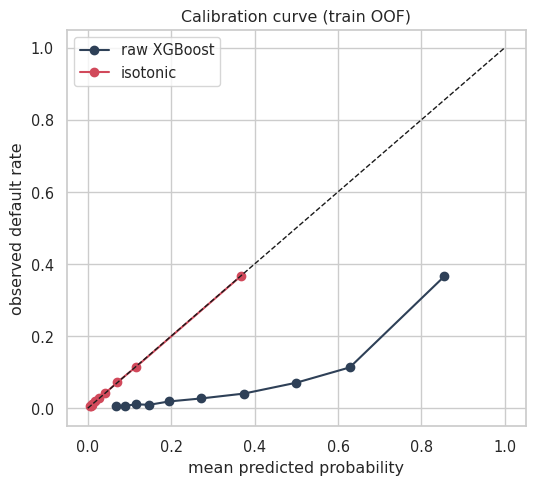

Target recall 80% -> threshold = 0.0597 (train OOF: recall=0.804, precision=0.194)


In [50]:
from sklearn.isotonic import IsotonicRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, precision_recall_curve
import matplotlib.pyplot as plt

TARGET_RECALL = 0.80      # business choice: share of defaulters we must catch

# cross-fitted isotonic calibration of the OOF scores
oof_cal = np.zeros_like(oof_xgb)
for a, b in StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE).split(oof_xgb.reshape(-1, 1), y_train):
    iso = IsotonicRegression(out_of_bounds="clip").fit(oof_xgb[a], y_train.iloc[a])
    oof_cal[b] = iso.predict(oof_xgb[b])

print(f"Brier  raw={brier_score_loss(y_train, oof_xgb):.4f}   isotonic={brier_score_loss(y_train, oof_cal):.4f}")
print(f"AUC-PR raw={average_precision_score(y_train, oof_xgb):.4f}   isotonic={average_precision_score(y_train, oof_cal):.4f}")

fig, ax = plt.subplots(figsize=(5.5, 5))
for lbl, p in [("raw XGBoost", oof_xgb), ("isotonic", oof_cal)]:
    frac, mean = calibration_curve(y_train, p, n_bins=10, strategy="quantile")
    ax.plot(mean, frac, marker="o", label=lbl)
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set(xlabel="mean predicted probability", ylabel="observed default rate", title="Calibration curve (train OOF)")
ax.legend(); plt.tight_layout(); plt.show()

# threshold: highest cut-off with recall >= TARGET_RECALL
prec, rec, thr = precision_recall_curve(y_train, oof_cal)
i = np.where(rec[:-1] >= TARGET_RECALL)[0][-1]
THRESHOLD = float(thr[i])
print(f"Target recall {TARGET_RECALL:.0%} -> threshold = {THRESHOLD:.4f} "
      f"(train OOF: recall={rec[i]:.3f}, precision={prec[i]:.3f})")

## [GMSC] Part 10 -- Final test evaluation (run once)

Final fit:
- XGBoost on the **full training set** with the tuned params.
- Isotonic calibrator fit on the OOF scores (all training rows).

The test set gets the **train** clipping limits. No tuning or threshold change happens after this cell. `final_xgb_pipe` is the plain XGBoost pipeline, kept for SHAP.

In [51]:
from sklearn.metrics import recall_score, precision_score, f1_score, confusion_matrix
import joblib

final_xgb_pipe = clone(xgb_pipe).fit(X_train, y_train)
calibrator = IsotonicRegression(out_of_bounds="clip").fit(oof_xgb, y_train)

X_test = gmsc_test[FEATURE_COLS].copy()
X_test[NUMERIC_COLS] = X_test[NUMERIC_COLS].clip(lower=lower_limits, upper=upper_limits, axis=1)  # train limits
y_test = gmsc_test[TARGET].astype(int)

p_raw  = final_xgb_pipe.predict_proba(X_test)[:, 1]
p_test = calibrator.predict(p_raw)
pred   = (p_test >= THRESHOLD).astype(int)

print("=== FINAL TEST (single evaluation) ===")
print(f"AUC-PR    : {average_precision_score(y_test, p_test):.4f}   (base rate {y_test.mean():.4f})")
print(f"ROC-AUC   : {roc_auc_score(y_test, p_test):.4f}")
print(f"Brier     : {brier_score_loss(y_test, p_test):.4f}   (raw: {brier_score_loss(y_test, p_raw):.4f})")
print(f"Threshold : {THRESHOLD:.4f}")
print(f"Recall    : {recall_score(y_test, pred):.4f}")
print(f"Precision : {precision_score(y_test, pred):.4f}")
print(f"F1        : {f1_score(y_test, pred):.4f}")
cm = confusion_matrix(y_test, pred)
display(pd.DataFrame(cm, index=["actual 0", "actual 1"], columns=["pred 0", "pred 1"]))

joblib.dump({"xgb_pipeline": final_xgb_pipe, "calibrator": calibrator, "threshold": THRESHOLD,
             "features": FEATURE_COLS, "clip_lower": lower_limits, "clip_upper": upper_limits,
             "best_params": BEST_XGB_PARAMS}, "gmsc_final_model.joblib")
print("Saved gmsc_final_model.joblib")

=== FINAL TEST (single evaluation) ===
AUC-PR    : 0.3873   (base rate 0.0668)
ROC-AUC   : 0.8639
Brier     : 0.0491   (raw: 0.1438)
Threshold : 0.0597
Recall    : 0.8224
Precision : 0.1896
F1        : 0.3082


,pred 0,pred 1
actual 0,20947,7048
actual 1,356,1649


Saved gmsc_final_model.joblib


## [GMSC] Part 11 -- SHAP explainability (summary + waterfall)

Uses the **final** XGBoost pipeline from Part 10 (`final_xgb_pipe`), the fitted `calibrator`, `THRESHOLD`,
and the train clipping limits. Run this cell block **after** Part 10.

Notes:
- SHAP values of XGBoost are in **log-odds of the raw model score** (before isotonic calibration).
  They tell us *which features push risk up/down and by how much*; the risk % shown to the user is the
  **calibrated** probability.
- Several features are derived from the same raw inputs (income -> log_income, obligations, surplus), so we
  also show SHAP **grouped by business driver** (additive, so grouping is exact).

In [52]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, shap

pre_fitted = final_xgb_pipe.named_steps["pre"]
xgb_model  = final_xgb_pipe.named_steps["clf"]

# readable feature names (strip the ColumnTransformer prefix "num__" / "flags__")
RAW_NAMES = [n.split("__", 1)[-1] for n in pre_fitted.get_feature_names_out()]
NICE = {
    "age": "Age",
    "derived_log_income": "Income (log)",
    "derived_obligations": "Monthly obligations",
    "derived_monthly_surplus": "Monthly surplus (income - obligations)",
    "derived_expense_ratio": "Debt ratio",
    "derived_utilization_capped": "Credit utilization",
    "dependents": "Dependents",
    "derived_late_count": "Late-payment count",
    "derived_late_severity": "Late-payment severity",
    "income_missing_flag": "Income missing",
    "dependents_missing_flag": "Dependents missing",
    "derived_placeholder_code_flag": "Placeholder (96/98) code",
    "derived_debt_ratio_outlier": "Debt ratio outlier (>5)",
    "derived_overspend_flag": "Overspend (debt ratio > 1)",
    "derived_utilization_outlier_flag": "Utilization > 1",
}
FEATURE_NAMES = [NICE.get(n, n) for n in RAW_NAMES]

# business groups (for the app / report): SHAP is additive, so summing within a group is exact
GROUPS = {
    "Late payments":      ["derived_late_count", "derived_late_severity", "derived_placeholder_code_flag"],
    "Credit utilization": ["derived_utilization_capped", "derived_utilization_outlier_flag"],
    "Income":             ["derived_log_income", "derived_obligations", "derived_monthly_surplus", "income_missing_flag"],
    "Debt ratio":         ["derived_expense_ratio", "derived_debt_ratio_outlier", "derived_overspend_flag"],
    "Age":                ["age"],
    "Dependents":         ["dependents", "dependents_missing_flag"],
}
assert sorted(sum(GROUPS.values(), [])) == sorted(RAW_NAMES), "every model feature must belong to exactly one group"


def to_matrix(X):
    """Prepared features (FEATURE_COLS, clipped) -> imputed matrix the XGBoost model actually sees."""
    return pd.DataFrame(pre_fitted.transform(X), columns=FEATURE_NAMES, index=X.index)


explainer = shap.TreeExplainer(xgb_model)


def shap_explanation(X):
    """shap.Explanation (log-odds of raw model score) for prepared features X."""
    Xm = to_matrix(X)
    return explainer(Xm)


def group_values(sv):
    """Sum SHAP values per business group -> DataFrame (rows = customers, cols = groups)."""
    vals = pd.DataFrame(sv.values, columns=RAW_NAMES)
    return pd.DataFrame({g: vals[cols].sum(axis=1) for g, cols in GROUPS.items()})

### [GMSC] 11.1 Summary plots (global explanation)
SHAP on a random sample of the test set (the final test evaluation in Part 10 is already done).

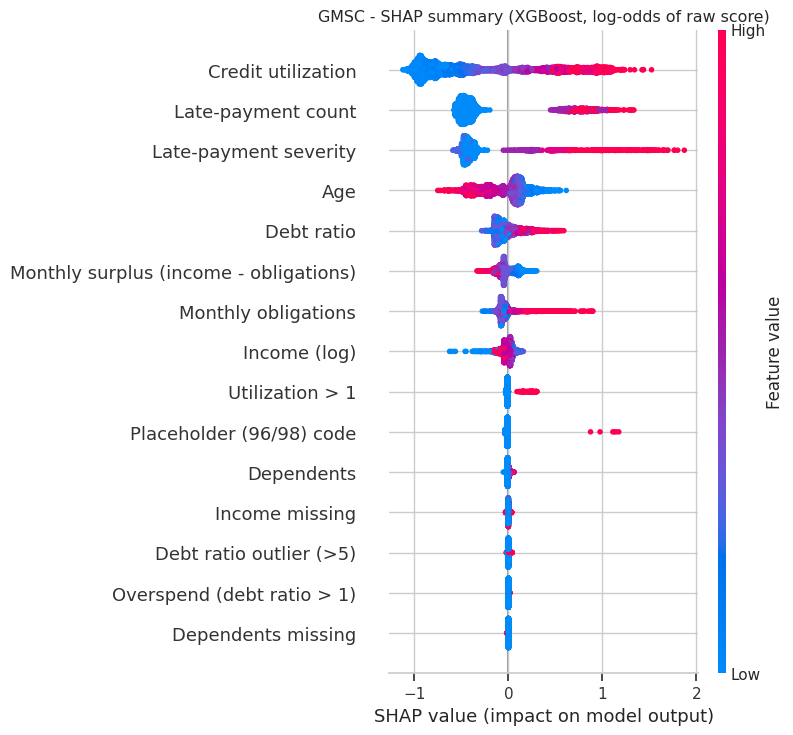

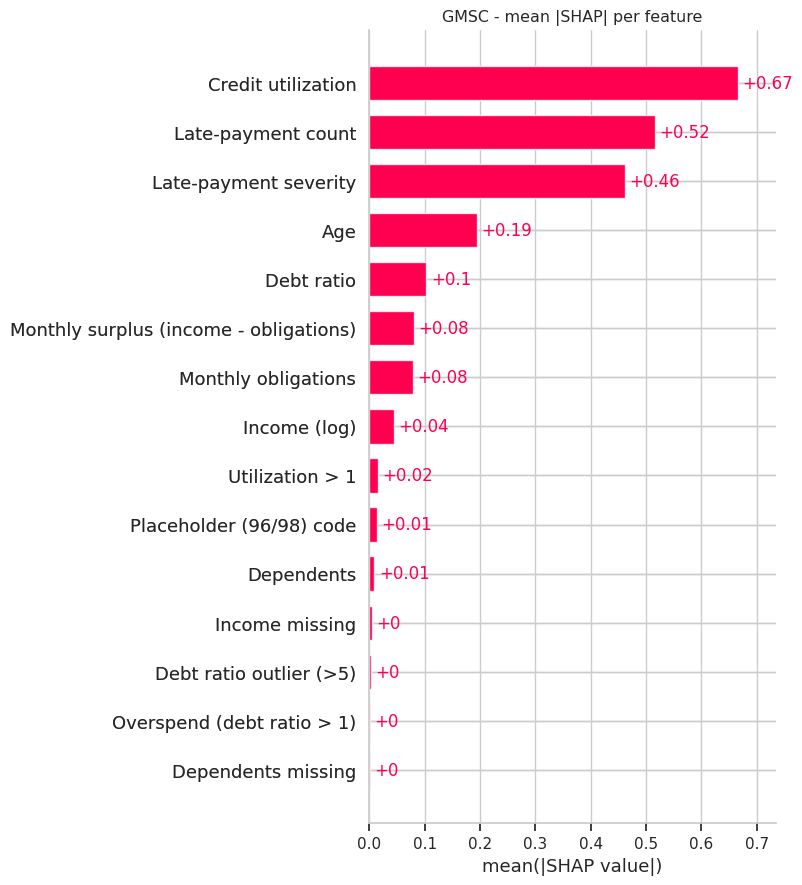

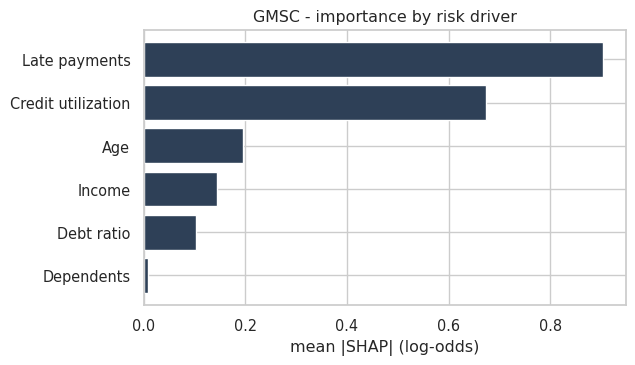

Late payments        0.9031
Credit utilization   0.6728
Age                  0.1946
Income               0.1435
Debt ratio           0.1028
Dependents           0.0093
dtype: float32


In [53]:
N_SHAP = min(5000, len(X_test))
X_shap = X_test.sample(N_SHAP, random_state=RANDOM_STATE)
sv_all = shap_explanation(X_shap)

# (a) beeswarm: direction + magnitude per feature
plt.figure()
shap.plots.beeswarm(sv_all, max_display=15, show=False)
plt.title("GMSC - SHAP summary (XGBoost, log-odds of raw score)")
plt.tight_layout(); plt.savefig("gmsc_shap_summary_beeswarm.png", dpi=200, bbox_inches="tight"); plt.show()

# (b) bar: mean |SHAP| per feature
plt.figure()
shap.plots.bar(sv_all, max_display=15, show=False)
plt.title("GMSC - mean |SHAP| per feature")
plt.tight_layout(); plt.savefig("gmsc_shap_importance_bar.png", dpi=200, bbox_inches="tight"); plt.show()

# (c) bar by business group (what the app can say to the customer)
grp = group_values(sv_all)
imp = grp.abs().mean().sort_values()
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.barh(imp.index, imp.values, color="#2E4057")
ax.set(xlabel="mean |SHAP| (log-odds)", title="GMSC - importance by risk driver")
plt.tight_layout(); plt.savefig("gmsc_shap_importance_by_group.png", dpi=200, bbox_inches="tight"); plt.show()
print(imp.sort_values(ascending=False).round(4))

### [GMSC] 11.2 Waterfall plots (individual customers)
Three representative customers from the test set: highest-risk real defaulter, borderline (closest to the
threshold), and a lowest-risk customer.

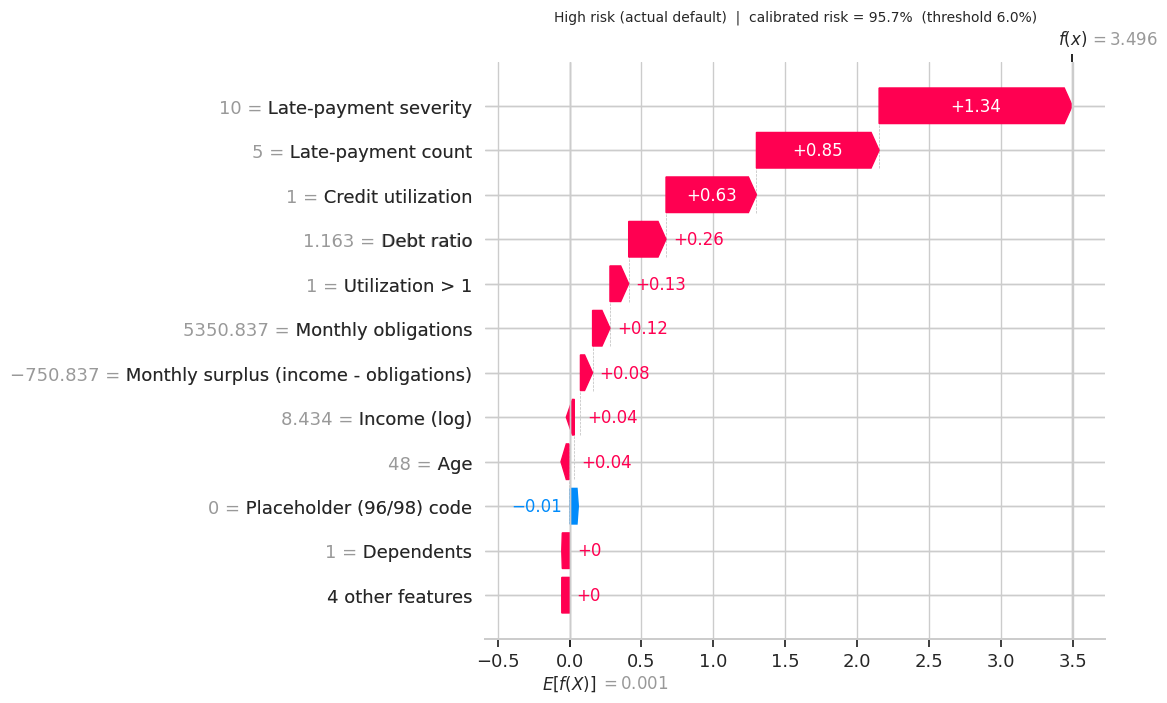

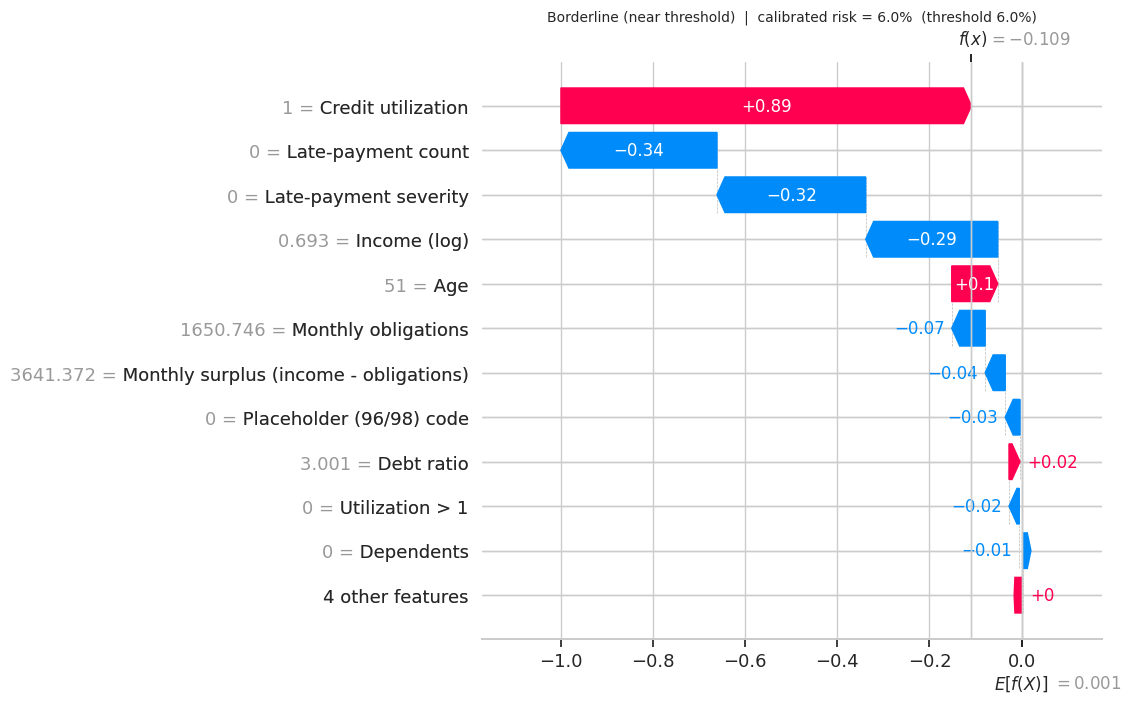

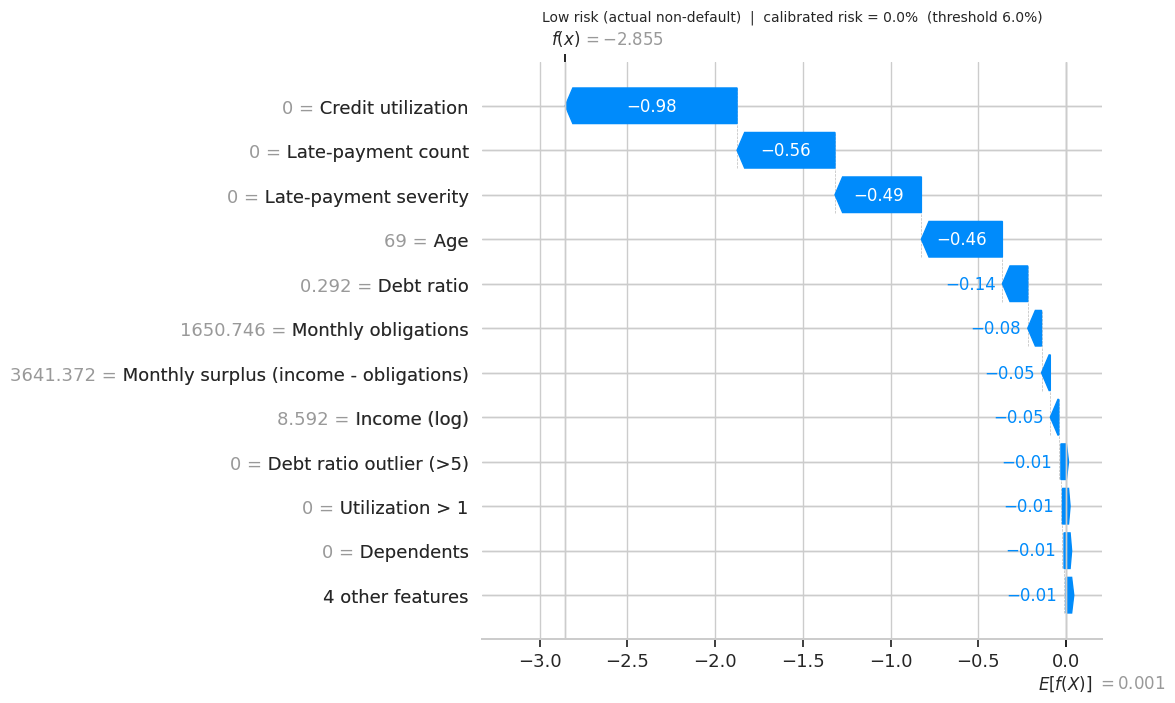

In [54]:
p_raw_test = final_xgb_pipe.predict_proba(X_test)[:, 1]
p_cal_test = calibrator.predict(p_raw_test)
tmp = pd.DataFrame({"p": p_cal_test, "y": y_test.values, "raw": p_raw_test}, index=X_test.index)

picks = {
    "High risk (actual default)": tmp[tmp.y == 1].sort_values(["p", "raw"], ascending=False).index[0],
    "Borderline (near threshold)": (tmp.p - THRESHOLD).abs().sort_values().index[0],
    "Low risk (actual non-default)": tmp[tmp.y == 0].sort_values(["p", "raw"]).index[0],
}

for label, idx in picks.items():
    sv_one = shap_explanation(X_test.loc[[idx]])
    plt.figure()
    shap.plots.waterfall(sv_one[0], max_display=12, show=False)
    plt.title(f"{label}  |  calibrated risk = {tmp.loc[idx, 'p']:.1%}  (threshold {THRESHOLD:.1%})", fontsize=10)
    fname = "gmsc_shap_waterfall_" + label.split(" (")[0].lower().replace(" ", "_") + ".png"
    plt.savefig(fname, dpi=200, bbox_inches="tight"); plt.show()

## [GMSC] Part 12 -- Prediction function (basis for the scenarios)

`predict_risk` takes **raw** customer data (same columns as the original CSV), optionally overrides
`MonthlyIncome`, `DebtRatio`, `NumberOfDependents`, then runs the same path as training:
feature engineering -> train clipping -> XGBoost pipeline -> isotonic calibration -> threshold.

**Important modelling choice (`keep_obligations`)**: in GMSC, `DebtRatio = monthly debt payments / income`.
If someone's income goes up 20% and `DebtRatio` stays the same, the model would silently assume their debt
payments also grew 20%. For a realistic "what if my income rises" scenario we keep the *dollar* obligations
fixed and rescale `DebtRatio` (default). If you pass `DebtRatio` yourself, your value is used as-is.

In [55]:
import os, tempfile

RAW_COLS = [
    "RevolvingUtilizationOfUnsecuredLines", "age", "NumberOfTime30-59DaysPastDueNotWorse", "DebtRatio",
    "MonthlyIncome", "NumberOfOpenCreditLinesAndLoans", "NumberOfTimes90DaysLate",
    "NumberRealEstateLoansOrLines", "NumberOfTime60-89DaysPastDueNotWorse", "NumberOfDependents",
]


def _features_from_raw(raw_df):
    """Raw columns -> engineered features, using the SAME code as training (build_gmsc_features)."""
    if "build_gmsc_features_df" in globals():          # preferred: if you refactored the function to take a DataFrame
        return build_gmsc_features_df(raw_df)
    with tempfile.TemporaryDirectory() as d:           # fallback: no edit to the original function needed
        p = os.path.join(d, "raw.csv")
        raw_df.to_csv(p, index=False)
        return build_gmsc_features(p)


def _prepare(raw_df):
    raw_df = raw_df.copy()
    if "SeriousDlqin2yrs" not in raw_df:                # build_gmsc_features expects the target column
        raw_df["SeriousDlqin2yrs"] = np.nan
    feats = _features_from_raw(raw_df[RAW_COLS + ["SeriousDlqin2yrs"]])
    X = feats[FEATURE_COLS].copy()
    X[NUMERIC_COLS] = X[NUMERIC_COLS].clip(lower=lower_limits, upper=upper_limits, axis=1)   # TRAIN limits
    return X


def _as_frame(customer):
    if isinstance(customer, pd.DataFrame):
        df = customer.copy()
    elif isinstance(customer, pd.Series):
        df = customer.to_frame().T
    else:
        df = pd.DataFrame([customer])
    missing = [c for c in RAW_COLS if c not in df.columns]
    if missing:
        raise ValueError(f"Missing raw columns: {missing}")
    df = df[RAW_COLS].astype(float).reset_index(drop=True)
    return df


def predict_risk_batch(raw_df):
    """Calibrated default probability for every row of a raw DataFrame -> np.ndarray."""
    X = _prepare(_as_frame(raw_df))
    return calibrator.predict(final_xgb_pipe.predict_proba(X)[:, 1])


def predict_risk(customer, MonthlyIncome=None, DebtRatio=None, NumberOfDependents=None, keep_obligations=True):
    """
    customer : dict / Series / 1-row DataFrame with the raw GMSC columns (RAW_COLS).
    MonthlyIncome, DebtRatio, NumberOfDependents : scenario overrides (None = keep the customer's value).
    Returns dict: risk (calibrated probability), flagged (risk >= threshold), threshold, and the inputs used.
    """
    df = _as_frame(customer)
    if len(df) != 1:
        raise ValueError("predict_risk expects ONE customer; use predict_risk_batch for many.")

    old_income, old_dr = df.at[0, "MonthlyIncome"], df.at[0, "DebtRatio"]

    if MonthlyIncome is not None:
        if not MonthlyIncome > 0:
            raise ValueError("MonthlyIncome must be > 0")
        df.at[0, "MonthlyIncome"] = float(MonthlyIncome)
        if keep_obligations and DebtRatio is None and pd.notna(old_income) and old_income > 0 and pd.notna(old_dr):
            df.at[0, "DebtRatio"] = old_dr * old_income / float(MonthlyIncome)   # same $ obligations
    if DebtRatio is not None:
        if DebtRatio < 0:
            raise ValueError("DebtRatio must be >= 0")
        df.at[0, "DebtRatio"] = float(DebtRatio)
    if NumberOfDependents is not None:
        if NumberOfDependents < 0:
            raise ValueError("NumberOfDependents must be >= 0")
        df.at[0, "NumberOfDependents"] = float(NumberOfDependents)

    risk = float(predict_risk_batch(df)[0])
    return {
        "risk": risk,
        "flagged": bool(risk >= THRESHOLD),
        "threshold": float(THRESHOLD),
        "inputs_used": {c: df.at[0, c] for c in ["MonthlyIncome", "DebtRatio", "NumberOfDependents"]},
    }


def compare_scenario(customer, **changes):
    """Before vs after for the same customer, e.g. compare_scenario(c, MonthlyIncome=9000, NumberOfDependents=1)."""
    before = predict_risk(customer)
    after = predict_risk(customer, **changes)
    return {"before": before["risk"], "after": after["risk"], "delta": after["risk"] - before["risk"],
            "flag_before": before["flagged"], "flag_after": after["flagged"], "changes": changes}


def explain_customer(customer, top_k=5, plot=True, **overrides):
    """
    Why is this customer risky? Returns calibrated risk + top drivers (grouped, additive SHAP) and,
    if plot=True, the waterfall. Overrides work like predict_risk (scenario explanation).
    """
    df = _as_frame(customer)
    res = predict_risk(df, **overrides)
    # rebuild the exact row the model saw (after overrides)
    df.loc[0, ["MonthlyIncome", "DebtRatio", "NumberOfDependents"]] = [
        res["inputs_used"]["MonthlyIncome"], res["inputs_used"]["DebtRatio"], res["inputs_used"]["NumberOfDependents"]]
    X = _prepare(df)
    sv = shap_explanation(X)
    g = group_values(sv).iloc[0].sort_values(key=np.abs, ascending=False)
    drivers = [{"driver": k, "effect": ("increases risk" if v > 0 else "decreases risk"), "shap": float(v)}
               for k, v in g.head(top_k).items()]
    if plot:
        plt.figure(); shap.plots.waterfall(sv[0], max_display=12, show=False)
        plt.title(f"calibrated risk = {res['risk']:.1%}  (threshold {THRESHOLD:.1%})", fontsize=10); plt.show()
    return {**res, "drivers": drivers}

### [GMSC] 12.1 Quick checks + scenario demo

max |function - Part10| = 0.0
current risk       : 0.9574
income +30%        : {'before': 0.957446813583374, 'after': 0.957446813583374, 'delta': 0.0, 'flag_before': True, 'flag_after': True, 'changes': {'MonthlyIncome': 5980.0}}
debt ratio -> 0.2  : {'before': 0.957446813583374, 'after': 0.7322834730148315, 'delta': -0.22516334056854248, 'flag_before': True, 'flag_after': True, 'changes': {'DebtRatio': 0.2}}
dependents -> 0    : {'before': 0.957446813583374, 'after': 0.957446813583374, 'delta': 0.0, 'flag_before': True, 'flag_after': True, 'changes': {'NumberOfDependents': 0}}


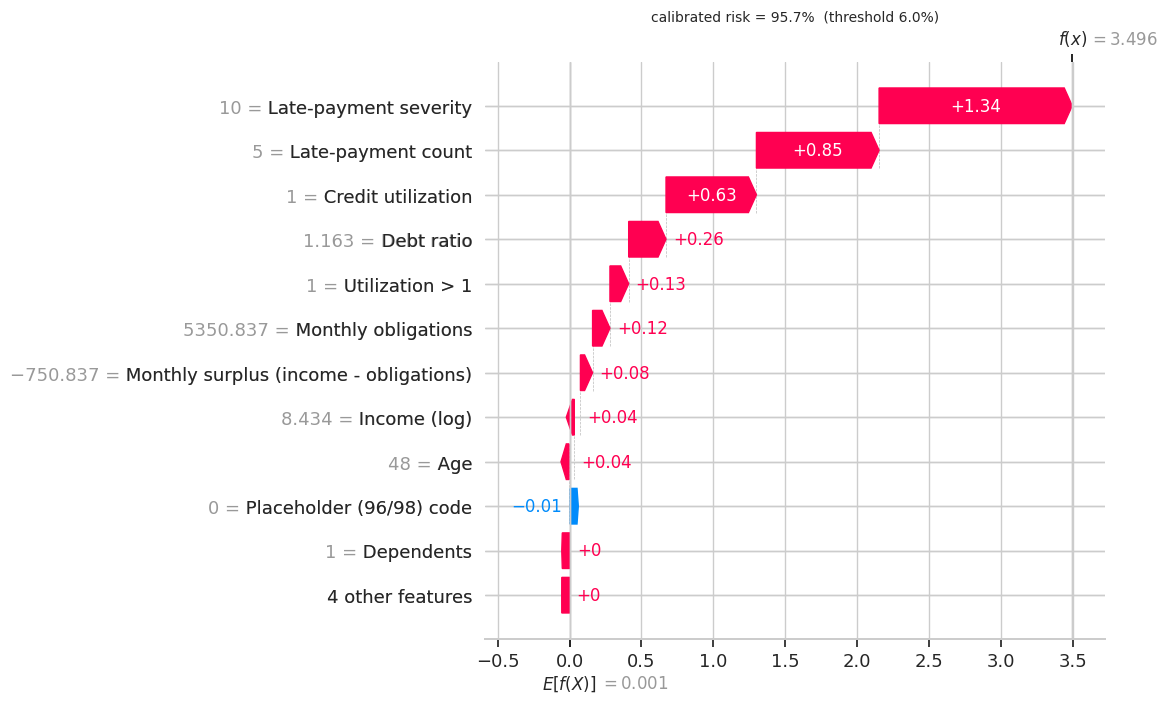

0.957446813583374 [{'driver': 'Late payments', 'effect': 'increases risk', 'shap': 2.1875672340393066}, {'driver': 'Credit utilization', 'effect': 'increases risk', 'shap': 0.7590519785881042}, {'driver': 'Debt ratio', 'effect': 'increases risk', 'shap': 0.26148465275764465}, {'driver': 'Income', 'effect': 'increases risk', 'shap': 0.2463746815919876}]


In [56]:
raw_all = pd.read_csv(GMSC_PATH)                          # raw columns; row index == gmsc index
cust = raw_all.loc[picks["High risk (actual default)"], RAW_COLS]

# 1) consistency: the function on RAW data must reproduce the Part 10 test probabilities exactly
chk_idx = X_test.index[:300]
p_fn = predict_risk_batch(raw_all.loc[chk_idx, RAW_COLS])
print("max |function - Part10| =", float(np.abs(p_fn - p_cal_test[:300]).max()))   # expect ~0

# 2) scenarios
print("current risk       :", round(predict_risk(cust)["risk"], 4))
print("income +30%        :", compare_scenario(cust, MonthlyIncome=float(cust["MonthlyIncome"]) * 1.3 if pd.notna(cust["MonthlyIncome"]) else 8000))
print("debt ratio -> 0.2  :", compare_scenario(cust, DebtRatio=0.2))
print("dependents -> 0    :", compare_scenario(cust, NumberOfDependents=0))

# 3) explanation + top reasons
out = explain_customer(cust, top_k=4)
print(out["risk"], out["drivers"])

## [GMSC] Part 13 -- Scoring, Scenarios & Recommendations Engine (Week 3)

1. **Scoring + what-if scenarios** (Stage 10)
2. **Recommendations Engine** (Stage 11): the smallest change the customer can make to lower their risk.
3. **Savings Coverage** (Stage 12): rule-based runway / shock coverage shown next to every scenario.
4. **Long-Term Risk View, 24 months** (Stage 13): structural GMSC risk with plain-language drivers.

Requires `gmsc_final_model.joblib`, which is written at the end of Part 10 in this same notebook.
Helper names that also exist in Part 12 (`_as_frame`, `_prepare`, `explainer`) are prefixed with `_g` / `_g_` here so the two parts don't overwrite each other.


In [57]:
# pip install joblib shap xgboost scikit-learn pandas numpy
# On Colab, mount Drive and point to the folder that contains gmsc_final_model.joblib:
# from google.colab import drive; drive.mount("/content/drive")
# import os; os.chdir("/content/drive/MyDrive/<your-folder>")
import os
print("Working dir:", os.getcwd())
print("Model found:", os.path.exists("gmsc_final_model.joblib"))


Working dir: /home/claude/run
Model found: True


### [GMSC] 13.1 Scoring + What-if scenarios

In [58]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import shap

# --------------------------------------------------------------------------
# Model loading (path is relative to this file, so it works anywhere)
# --------------------------------------------------------------------------
BASE_DIR = os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else os.getcwd()
MODEL_PATH = os.path.join(BASE_DIR, "gmsc_final_model.joblib")
ART = joblib.load(MODEL_PATH)

PIPE, CAL, THRESHOLD = ART["xgb_pipeline"], ART["calibrator"], ART["threshold"]
FEATURE_COLS = ART["features"]
LOWER, UPPER = ART["clip_lower"], ART["clip_upper"]
NUMERIC_COLS = list(LOWER.index)

RAW_COLS = [
    "RevolvingUtilizationOfUnsecuredLines", "age", "NumberOfTime30-59DaysPastDueNotWorse", "DebtRatio",
    "MonthlyIncome", "NumberOfOpenCreditLinesAndLoans", "NumberOfTimes90DaysLate",
    "NumberRealEstateLoansOrLines", "NumberOfTime60-89DaysPastDueNotWorse", "NumberOfDependents",
]


# --------------------------------------------------------------------------
# Feature engineering
# --------------------------------------------------------------------------
def build_gmsc_features_df(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    # duplicate review
    id_like_cols = [c for c in df.columns if c.startswith("Unnamed")]
    dup_check_cols = [c for c in df.columns if c not in id_like_cols]
    duplicate_flag = df.duplicated(subset=dup_check_cols, keep=False).astype(int)
    df = df.drop(columns=id_like_cols)

    out = pd.DataFrame(index=df.index)
    out["duplicate_flag"] = duplicate_flag.values

    out["income_missing_flag"] = df["MonthlyIncome"].isna().astype(int)
    out["income"] = df["MonthlyIncome"]

    valid_income_mask = out["income"].notna() & (out["income"] > 0)
    debt_ratio_clean = df["DebtRatio"].where(valid_income_mask)
    out["derived_debt_ratio_outlier"] = (df["DebtRatio"] > 5).astype(int)

    past_due_cols = [
        "NumberOfTime30-59DaysPastDueNotWorse",
        "NumberOfTime60-89DaysPastDueNotWorse",
        "NumberOfTimes90DaysLate",
    ]
    placeholder_mask = pd.Series(False, index=df.index)
    past_due_clean = pd.DataFrame(index=df.index)
    for col in past_due_cols:
        is_placeholder = df[col].isin([96, 98])
        placeholder_mask = placeholder_mask | is_placeholder
        past_due_clean[col] = df[col].where(~is_placeholder)
    out["derived_placeholder_code_flag"] = placeholder_mask.astype(int)

    out["age"] = df["age"].replace(0, np.nan)

    out["dependents_missing_flag"] = df["NumberOfDependents"].isna().astype(int)
    out["dependents"] = df["NumberOfDependents"].fillna(0)

    out["derived_late_count"] = past_due_clean.sum(axis=1, skipna=True)
    out["derived_late_severity"] = (
        past_due_clean["NumberOfTime30-59DaysPastDueNotWorse"].fillna(0) * 1
        + past_due_clean["NumberOfTime60-89DaysPastDueNotWorse"].fillna(0) * 2
        + past_due_clean["NumberOfTimes90DaysLate"].fillna(0) * 3
    )
    out["late_payments"] = out["derived_late_count"]

    obligations_mask = valid_income_mask & (df["DebtRatio"] <= 5)
    out["derived_obligations"] = np.where(obligations_mask, df["DebtRatio"] * out["income"], np.nan)
    out["monthly_debt_payment"] = out["derived_obligations"]
    out["monthly_debt_payment_is_proxy"] = 1

    out["derived_expense_ratio"] = debt_ratio_clean
    out["derived_monthly_surplus"] = out["income"] - out["derived_obligations"]
    out["savings"] = out["derived_monthly_surplus"]
    out["savings_is_proxy"] = 1

    out["derived_overspend_flag"] = (debt_ratio_clean > 1).astype(int)

    util = df["RevolvingUtilizationOfUnsecuredLines"]
    out["derived_utilization_capped"] = util.clip(upper=1)
    out["derived_utilization_outlier_flag"] = (util > 1).astype(int)
    out["revolving_utilization_ref"] = util

    out["derived_log_income"] = np.log1p(out["income"].clip(lower=0))

    for c in ["debt", "expenses", "rent", "income_stability", "month"]:
        out[c] = np.nan

    out["target"] = df["SeriousDlqin2yrs"]
    out["source_dataset"] = "gmsc"
    return out


# --------------------------------------------------------------------------
# Scoring + explanations
# --------------------------------------------------------------------------
pre, model = PIPE.named_steps["pre"], PIPE.named_steps["clf"]
RAW_NAMES = [n.split("__", 1)[-1] for n in pre.get_feature_names_out()]
_g_explainer = shap.TreeExplainer(model)

GROUPS = {
    "Late payments":      ["derived_late_count", "derived_late_severity", "derived_placeholder_code_flag"],
    "Credit utilization": ["derived_utilization_capped", "derived_utilization_outlier_flag"],
    "Income":             ["derived_log_income", "derived_obligations", "derived_monthly_surplus", "income_missing_flag"],
    "Debt ratio":         ["derived_expense_ratio", "derived_debt_ratio_outlier", "derived_overspend_flag"],
    "Age":                ["age"],
    "Dependents":         ["dependents", "dependents_missing_flag"],
}
assert sorted(sum(GROUPS.values(), [])) == sorted(RAW_NAMES)

MEDIUM_CUT = THRESHOLD / 2  # design decision: agree on this with the team


def risk_level(p):
    return "High" if p >= THRESHOLD else "Medium" if p >= MEDIUM_CUT else "Low"


def _g_as_frame(customer):
    df = customer.to_frame().T if isinstance(customer, pd.Series) else \
         customer.copy() if isinstance(customer, pd.DataFrame) else pd.DataFrame([customer])
    missing = [c for c in RAW_COLS if c not in df.columns]
    if missing:
        raise ValueError(f"Missing raw columns: {missing}")
    return df[RAW_COLS].astype(float).reset_index(drop=True)


def _g_prepare(raw_df):
    raw_df = raw_df.copy()
    raw_df["SeriousDlqin2yrs"] = np.nan
    X = build_gmsc_features_df(raw_df)[FEATURE_COLS].copy()
    X[NUMERIC_COLS] = X[NUMERIC_COLS].clip(lower=LOWER, upper=UPPER, axis=1)  # training bounds
    return X


def _reasons(X, top_k):
    s = pd.Series(_g_explainer.shap_values(pre.transform(X))[0], index=RAW_NAMES)
    g = pd.Series({k: s[v].sum() for k, v in GROUPS.items()})
    g = g.sort_values(key=np.abs, ascending=False).head(top_k)
    return [{"driver": k, "effect": "increases risk" if v > 0 else "decreases risk",
             "shap": round(float(v), 3)} for k, v in g.items()]


def score_customer(customer, top_k=3):
    X = _g_prepare(_g_as_frame(customer))
    p = float(CAL.predict(PIPE.predict_proba(X)[:, 1])[0])
    return {
        "dataset": "gmsc", "horizon": "24 months",
        "risk": round(p, 4), "level": risk_level(p),
        "flagged": p >= THRESHOLD, "threshold": round(THRESHOLD, 4),
        "top_reasons": _reasons(X, top_k),
    }


# --------------------------------------------------------------------------
# What-if scenarios
# --------------------------------------------------------------------------
def _need_income(c):
    if not (pd.notna(c["MonthlyIncome"]) and c["MonthlyIncome"] > 0 and pd.notna(c["DebtRatio"])):
        raise ValueError("This scenario needs a valid MonthlyIncome and DebtRatio")


def income_drop(c, pct):
    c = c.copy(); _need_income(c)
    obligations = c["DebtRatio"] * c["MonthlyIncome"]       # actual amount stays fixed
    c["MonthlyIncome"] *= (1 - pct)
    c["DebtRatio"] = obligations / c["MonthlyIncome"]       # the ratio is what goes up
    return c


def add_monthly_payment(c, amount):                         # new loan / higher bill
    c = c.copy(); _need_income(c)
    c["DebtRatio"] += amount / c["MonthlyIncome"]
    return c


def late_payment(c, months=1):                              # a late payment
    c = c.copy()
    col = "NumberOfTime30-59DaysPastDueNotWorse"
    c[col] = (0 if pd.isna(c[col]) else c[col]) + months
    return c


GMSC_SCENARIOS = {
    "Income drops 20%":       lambda c: income_drop(c, 0.20),
    "New loan (1,500/mo)":    lambda c: add_monthly_payment(c, 1500),
    "Higher bills (+800/mo)": lambda c: add_monthly_payment(c, 800),
    "One month late":         lambda c: late_payment(c, 1),
}


def run_scenario(customer, name, change_fn=None):
    c = _g_as_frame(customer).iloc[0]
    before = score_customer(c)
    after = score_customer(change_fn(c) if change_fn else GMSC_SCENARIOS[name](c))
    return {"scenario": name, "before": before["risk"], "after": after["risk"],
            "delta": round(after["risk"] - before["risk"], 4),
            "level_before": before["level"], "level_after": after["level"],
            "reasons_after": after["top_reasons"]}


def run_all(customer):
    out = []
    for name in GMSC_SCENARIOS:
        try:
            out.append(run_scenario(customer, name))
        except ValueError as e:
            out.append({"scenario": name, "error": str(e)})
    return pd.DataFrame(out)


# --------------------------------------------------------------------------
# Friendly input -> raw GMSC columns
# --------------------------------------------------------------------------
def build_raw_customer(age, monthly_income, monthly_debt_payments, card_balance, card_limit,
                       late_30_59=0, late_60_89=0, late_90_plus=0, dependents=0,
                       open_credit_lines=0, real_estate_loans=0):
    if not 18 <= age <= 100:               raise ValueError("Age must be between 18 and 100")
    if monthly_income <= 0:                raise ValueError("Monthly income must be greater than 0")
    if monthly_debt_payments < 0:          raise ValueError("Debt payments can't be negative")
    if card_limit < 0 or card_balance < 0: raise ValueError("Card balance/limit can't be negative")
    if min(late_30_59, late_60_89, late_90_plus, dependents) < 0:
        raise ValueError("Counts can't be negative")

    utilization = card_balance / card_limit if card_limit > 0 else 0.0
    return {
        "RevolvingUtilizationOfUnsecuredLines": utilization,
        "age": age,
        "NumberOfTime30-59DaysPastDueNotWorse": late_30_59,
        "DebtRatio": monthly_debt_payments / monthly_income,
        "MonthlyIncome": monthly_income,
        "NumberOfOpenCreditLinesAndLoans": open_credit_lines,
        "NumberOfTimes90DaysLate": late_90_plus,
        "NumberRealEstateLoansOrLines": real_estate_loans,
        "NumberOfTime60-89DaysPastDueNotWorse": late_60_89,
        "NumberOfDependents": dependents,
    }


### [GMSC] 13.2 Recommendations Engine (Stage 11)
Searches for the cheapest change in the levers the customer controls (card utilization, monthly debt, income) that brings the risk below the target. Age, late-payment history and dependents are reported as fixed factors only.

In [59]:
from dataclasses import dataclass
from itertools import combinations, product
from typing import Callable, Sequence

import numpy as np
import pandas as pd


# --------------------------------------------------------------------------
# Generic engine (dataset-agnostic: GMSC and UCI both plug into this)
# --------------------------------------------------------------------------
@dataclass
class Lever:
    """One thing the customer can change."""
    name: str
    apply: Callable[[pd.Series, float], pd.Series]   # (customer, amount) -> new customer
    grid: Callable[[pd.Series], Sequence[float]]     # candidate amounts, small -> large
    describe: Callable[[float], str]                 # English text for an amount
    describe_ar: Callable[[float], str]              # Arabic text for an amount
    weight: float = 1.0                              # effort multiplier (harder lever = bigger)


class RecommendationEngine:
    def __init__(self, risk_fn, levers, threshold, medium_cut=None,
                 explain_fn=None, fixed_drivers=(), level_fn=None, dataset=""):
        """
        risk_fn(list[pd.Series]) -> array of risks (batch, no SHAP, fast)
        explain_fn(customer)     -> list of {"driver", "effect", ...} (optional, for fixed factors)
        fixed_drivers            -> driver names the customer cannot change
        """
        self.risk_fn, self.levers = risk_fn, list(levers)
        self.threshold, self.medium_cut = threshold, medium_cut
        self.explain_fn, self.fixed_drivers = explain_fn, set(fixed_drivers)
        self.level_fn, self.dataset = level_fn, dataset

    # -- helpers ----------------------------------------------------------
    def _level(self, p):
        return self.level_fn(p) if self.level_fn else None

    def _plans(self, c, max_levers):
        grids = {}
        for lv in self.levers:
            try:
                g = [float(x) for x in lv.grid(c)]
            except ValueError:
                g = []
            if g:
                grids[lv.name] = g
        usable = [lv for lv in self.levers if lv.name in grids]
        for k in range(1, max_levers + 1):
            for combo in combinations(usable, k):
                for xs in product(*[grids[lv.name] for lv in combo]):
                    cost = sum(lv.weight * x / max(grids[lv.name]) for lv, x in zip(combo, xs))
                    yield list(zip(combo, xs)), cost

    def _evaluate(self, c, plans):
        """Apply each plan and score them all in one batch."""
        built, customers = [], []
        for steps, cost in plans:
            try:
                new = c.copy()
                for lv, x in steps:
                    new = lv.apply(new, x)
            except ValueError:
                continue
            built.append((steps, cost))
            customers.append(new)
        if not customers:
            return []
        risks = np.asarray(self.risk_fn(customers), dtype=float)
        return [(s, cst, float(r)) for (s, cst), r in zip(built, risks)]

    def _pack(self, steps, cost, risk, base_risk):
        return {
            "changes": [{"lever": lv.name, "amount": round(x, 4),
                         "text": lv.describe(x), "text_ar": lv.describe_ar(x)} for lv, x in steps],
            "risk_after": round(risk, 4),
            "delta": round(risk - base_risk, 4),
            "level_after": self._level(risk),
            "effort": round(cost, 3),
        }

    # -- main -------------------------------------------------------------
    def recommend(self, customer, target_risk=None, max_levers=2):
        """
        target_risk: risk must end up BELOW this value (default = model threshold,
                     i.e. "stop being flagged"; pass medium_cut to aim for Low).
        """
        c = pd.Series(customer) if not isinstance(customer, pd.Series) else customer.copy()
        target = self.threshold if target_risk is None else target_risk
        base = float(self.risk_fn([c])[0])

        out = {"dataset": self.dataset, "risk_now": round(base, 4), "level_now": self._level(base),
               "target_risk": round(target, 4), "fixed_factors": self._fixed_factors(c)}

        if base < target:
            out.update(status="already_below_target", recommendations=[],
                       message="Risk is already below the target; no change needed.",
                       message_ar="الخطر أصلاً أقل من الهدف، مفيش تغيير مطلوب.")
            return out

        for k in range(1, max_levers + 1):                 # fewest levers first
            evald = self._evaluate(c, [p for p in self._plans(c, k) if len(p[0]) == k])
            ok = [e for e in evald if e[2] < target]
            if ok:
                ok.sort(key=lambda e: e[1])                # cheapest first
                best = ok[0]
                # cheapest alternative per distinct lever-set (so the user has options)
                seen, alts = set(), []
                for steps, cost, risk in ok:
                    key = tuple(lv.name for lv, _ in steps)
                    if key not in seen:
                        seen.add(key)
                        alts.append(self._pack(steps, cost, risk, base))
                    if len(alts) == 3:
                        break
                out.update(status="found", best=alts[0], alternatives=alts[1:],
                           recommendations=alts,
                           message=" + ".join(ch["text"] for ch in alts[0]["changes"]),
                           message_ar=" + ".join(ch["text_ar"] for ch in alts[0]["changes"]))
                return out

        # nothing reaches the target: show the strongest achievable improvement
        evald = self._evaluate(c, self._plans(c, max_levers))
        steps, cost, risk = min(evald, key=lambda e: e[2]) if evald else (None, None, base)
        out.update(status="not_reachable", recommendations=[],
                   message="The target can't be reached with the levers the customer controls.",
                   message_ar="الهدف مش بيتحقق بالعوامل اللي العميل يقدر يغيّرها لوحدها.")
        if steps:
            out["best_effort"] = self._pack(steps, cost, risk, base)
        return out

    def _fixed_factors(self, c):
        if not self.explain_fn:
            return []
        return [r for r in self.explain_fn(c)
                if r["driver"] in self.fixed_drivers and r["effect"] == "increases risk"]


# --------------------------------------------------------------------------
# GMSC wiring
# --------------------------------------------------------------------------
def _gmsc_engine():
    import __main__ as g  # same notebook namespace

    def risk_batch(customers):
        df = pd.DataFrame([dict(c) for c in customers])
        X = g._g_prepare(g._g_as_frame(df))
        return g.CAL.predict(g.PIPE.predict_proba(X)[:, 1])

    # ---- levers ----
    def util_apply(c, pct):                       # pay the card down by pct of its balance
        c = c.copy()
        c["RevolvingUtilizationOfUnsecuredLines"] *= (1 - pct)
        return c

    def util_grid(c):
        u = c["RevolvingUtilizationOfUnsecuredLines"]
        if pd.isna(u) or u <= 0:
            return []
        return np.round(np.arange(0.05, 1.0001, 0.05), 2)

    def debt_apply(c, amount):                    # pay `amount`/month less in obligations
        g._need_income(c)
        c = c.copy()
        c["DebtRatio"] = max(0.0, c["DebtRatio"] - amount / c["MonthlyIncome"])
        return c

    def debt_grid(c):
        g._need_income(c)
        obligations = c["DebtRatio"] * c["MonthlyIncome"]
        if obligations <= 0:
            return []
        step = max(50, int(round(obligations / 20 / 50.0)) * 50)
        return list(np.arange(step, obligations + step, step))

    def income_apply(c, pct):                     # income rises by pct, obligations unchanged
        return g.income_drop(c, -pct)

    def income_grid(c):
        g._need_income(c)
        return np.round(np.arange(0.05, 0.5001, 0.05), 2)

    levers = [
        Lever("card_utilization", util_apply, util_grid,
              lambda x: f"Reduce credit-card utilization by {x:.0%}",
              lambda x: f"قلّل استخدام الكارت بنسبة {x:.0%}", weight=1.0),
        Lever("monthly_debt", debt_apply, debt_grid,
              lambda x: f"Pay down about {x:,.0f} of monthly debt obligations",
              lambda x: f"قلّل التزاماتك الشهرية بحوالي {x:,.0f}", weight=1.5),
        Lever("income", income_apply, income_grid,
              lambda x: f"Increase monthly income by {x:.0%}",
              lambda x: f"زوّد دخلك الشهري بنسبة {x:.0%}", weight=2.5),
    ]

    return RecommendationEngine(
        risk_fn=risk_batch, levers=levers, threshold=g.THRESHOLD, medium_cut=g.MEDIUM_CUT,
        explain_fn=lambda c: g.score_customer(c, top_k=6)["top_reasons"],
        fixed_drivers={"Late payments", "Age", "Dependents"},   # can't be changed by the user
        level_fn=g.risk_level, dataset="gmsc",
    )


_GMSC = None


def recommend_gmsc(customer, target_risk=None, max_levers=2):
    """customer: dict / Series with the raw GMSC columns (see build_raw_customer)."""
    global _GMSC
    if _GMSC is None:
        _GMSC = _gmsc_engine()
    import __main__ as g  # same notebook namespace
    c = g._g_as_frame(customer).iloc[0]
    return _GMSC.recommend(c, target_risk=target_risk, max_levers=max_levers)


# --------------------------------------------------------------------------
# UCI wiring (same engine, different levers)
# --------------------------------------------------------------------------
def recommend_uci(customer, target_risk=None, max_levers=2):
    raise NotImplementedError(
        "Needs the UCI scoring module (model, features, threshold). "
        "Once it exists: define risk_batch + levers (e.g. raise PAY_AMT_*, lower BILL_AMT_*, "
        "lower utilization of LIMIT_BAL) and build RecommendationEngine(...) like _gmsc_engine()."
    )


### [GMSC] 13.3 Savings Coverage (Stage 12, GMSC side)
**Rule-based, not model-based.** GMSC has no savings balance, so *liquid savings* is an input from the user (in their own currency, EGP). Nothing in this section touches the model, so it can't change the risk probabilities and it has no currency/training-distribution issue.

| Metric | Formula |
|---|---|
| `runway_months` | liquid_savings / (fixed_expenses + debt_payments) |
| `shock_coverage` | liquid_savings / shock_amount |
| `savings_after_shock` | liquid_savings - shock_amount |
| `months_to_depletion` | savings left / (monthly outflow - income), only when outflow > income |

`debt_payments = DebtRatio * MonthlyIncome` (same proxy used everywhere else in GMSC). Status bands (**critical / thin / safe**) come from `COVERAGE_CUTS` and are configurable. The overall status is the *worst* of the runway, shock and depletion statuses.

**How coverage sits next to the scenarios** (`run_all_with_coverage`):
- *Monthly* scenarios (income drop, new loan, higher bills): coverage is recomputed on the scenario customer (new obligations / new income), no one-off shock.
- *One-off* scenarios (medical emergency): the model sees the amount financed over 12 months (higher `DebtRatio`), while coverage sees the full amount taken out of savings. Coverage uses the **baseline** obligations here so the same shock isn't counted twice.

In [60]:
# --------------------------------------------------------------------------
# Stage 12 - Savings Coverage (GMSC side): rule-based, NOT model-based
# --------------------------------------------------------------------------
COVERAGE_CUTS = {   # configurable; design decision: agree on these with the team
    "runway_months":  {"critical": 1.0, "thin": 3.0},   # < 1 month critical, < 3 thin, else safe
    "shock_coverage": {"critical": 1.0, "thin": 2.0},   # < 1x can't absorb the shock, < 2x thin, else safe
}
_STATUS_RANK = {"critical": 0, "thin": 1, "safe": 2}
_STATUS_AR = {"critical": "حرج", "thin": "ضعيف", "safe": "آمن"}


def _coverage_status(value, cut):
    return "critical" if value < cut["critical"] else "thin" if value < cut["thin"] else "safe"


def _worst(*statuses):
    return min(statuses, key=_STATUS_RANK.get)


def savings_coverage(customer, liquid_savings, fixed_expenses=0.0, shock_amount=0.0, cuts=None):
    """
    customer        : raw GMSC columns (dict / Series), see build_raw_customer
    liquid_savings  : cash the user can use right now (user input, EGP)
    fixed_expenses  : monthly living costs NOT already in DebtRatio (rent, food...). Default 0
    shock_amount    : one-off expense taken out of savings (e.g. medical emergency). Default 0
    """
    cuts = cuts or COVERAGE_CUTS
    if min(liquid_savings, fixed_expenses, shock_amount) < 0:
        raise ValueError("Savings, fixed expenses and shock amount can't be negative")
    c = _g_as_frame(customer).iloc[0]
    _need_income(c)

    income = float(c["MonthlyIncome"])
    debt_payments = float(c["DebtRatio"]) * income
    outflow = float(fixed_expenses) + debt_payments           # what leaves every month

    savings_after = liquid_savings - shock_amount
    usable_after = max(0.0, savings_after)
    gap = max(0.0, outflow - income)                          # monthly shortfall (0 if income covers it)

    runway = liquid_savings / outflow if outflow > 0 else None            # None = nothing to cover
    runway_after = usable_after / outflow if outflow > 0 else None
    shock_cov = liquid_savings / shock_amount if shock_amount > 0 else None
    depletion = usable_after / gap if gap > 0 else None                   # None = income covers outflows

    detail = {
        "runway": _coverage_status(runway_after, cuts["runway_months"]) if runway_after is not None else "safe",
        "shock": _coverage_status(shock_cov, cuts["shock_coverage"]) if shock_cov is not None else "safe",
        "depletion": _coverage_status(depletion, cuts["runway_months"]) if depletion is not None else "safe",
    }
    status = _worst(*detail.values())

    en = [f"Coverage is {status}."]
    ar = [f"التغطية {_STATUS_AR[status]}."]
    if runway_after is not None:
        en.append(f"Savings cover about {runway_after:.1f} months of fixed expenses + debt payments.")
        ar.append(f"مدخراتك بتغطي حوالي {runway_after:.1f} شهر من المصاريف الثابتة + أقساط الديون.")
    if shock_amount > 0:
        en.append(f"A {shock_amount:,.0f} shock leaves {savings_after:,.0f}" + (" (savings can't cover it)." if savings_after < 0 else "."))
        ar.append(f"صدمة بقيمة {shock_amount:,.0f} هتسيب {savings_after:,.0f}" + (" (المدخرات مش كفاية)." if savings_after < 0 else "."))
    if gap > 0:
        en.append(f"Monthly outflows exceed income by {gap:,.0f}; savings would last about {depletion:.1f} months.")
        ar.append(f"المصروفات الشهرية أكتر من الدخل بـ {gap:,.0f}؛ المدخرات هتكفي حوالي {depletion:.1f} شهر.")

    r2 = lambda v: None if v is None else round(float(v), 2)
    return {
        "dataset": "gmsc", "view": "savings_coverage", "method": "rule_based",
        "inputs": {"liquid_savings": liquid_savings, "fixed_expenses": fixed_expenses,
                   "shock_amount": shock_amount, "monthly_income": round(income, 2),
                   "debt_payments": round(debt_payments, 2)},
        "monthly_outflow": round(outflow, 2), "monthly_gap": round(gap, 2),
        "runway_months": r2(runway), "runway_after_shock_months": r2(runway_after),
        "shock_coverage": r2(shock_cov), "savings_after_shock": round(savings_after, 2),
        "months_to_depletion": r2(depletion),
        "status": status, "status_detail": detail,
        "message": " ".join(en), "message_ar": " ".join(ar),
    }


# --------------------------------------------------------------------------
# Coverage next to every scenario result
# --------------------------------------------------------------------------
ONE_OFF_SCENARIOS = {"Medical emergency (20,000 one-off)": 20000}   # name -> amount taken from savings
MEDICAL_FINANCING_MONTHS = 12   # model input mapping: one-off amount -> amount/12 extra monthly debt


def coverage_scenarios():
    """Stage-10 library + one-off shocks (built on call, so new GMSC_SCENARIOS entries are picked up)."""
    lib = dict(GMSC_SCENARIOS)
    for name, amount in ONE_OFF_SCENARIOS.items():
        lib[name] = lambda c, a=amount: add_monthly_payment(c, a / MEDICAL_FINANCING_MONTHS)
    return lib


def run_scenario_with_coverage(customer, name, liquid_savings, fixed_expenses=0.0):
    lib = coverage_scenarios()
    c = _g_as_frame(customer).iloc[0]
    res = run_scenario(c, name, change_fn=lib[name])           # model view (risk before/after)
    one_off = ONE_OFF_SCENARIOS.get(name, 0.0)
    after_customer = c if one_off else lib[name](c)             # one-off: baseline obligations, no double count
    res["coverage_before"] = savings_coverage(c, liquid_savings, fixed_expenses)
    res["coverage_after"] = savings_coverage(after_customer, liquid_savings, fixed_expenses, shock_amount=one_off)
    return res


def run_all_with_coverage(customer, liquid_savings, fixed_expenses=0.0):
    rows = []
    for name in coverage_scenarios():
        try:
            r = run_scenario_with_coverage(customer, name, liquid_savings, fixed_expenses)
            cb, ca = r["coverage_before"], r["coverage_after"]
            rows.append({"scenario": name,
                         "risk_before": r["before"], "risk_after": r["after"], "delta": r["delta"],
                         "level_before": r["level_before"], "level_after": r["level_after"],
                         "coverage_before": cb["status"], "coverage_after": ca["status"],
                         "runway_after_months": ca["runway_after_shock_months"],
                         "savings_left": ca["savings_after_shock"],
                         "months_to_depletion": ca["months_to_depletion"]})
        except ValueError as e:
            rows.append({"scenario": name, "error": str(e)})
    return pd.DataFrame(rows)

### [GMSC] 13.4 Long-Term Risk View, 24 months (Stage 13, GMSC)
GMSC is a **structural** view: the label is "serious delinquency (90+ days late) within 24 months" and the data has no time dimension, so it is **not** shown as 30/90-day risk and it is **never averaged or merged** with the UCI cards.

- Calibrated probability only, banded with the saved threshold (Low / Medium / High).
- All six driver groups (late payments, utilization, income, debt ratio, age, dependents) in plain language, in English and Arabic.
- Wording is "associated with higher/lower risk" (SHAP explains the model; it is not causal).
- Each driver is tagged *changeable* or *fixed*, matching the Recommendations Engine.
- The model predicts payment distress / delinquency (a proxy for a cash-flow crisis), **not** "running out of savings".

In [61]:
# --------------------------------------------------------------------------
# Stage 13 - Long-term (24-month) structural risk view, GMSC
# --------------------------------------------------------------------------
FIXED_GROUPS = {"Late payments", "Age", "Dependents"}   # same split as the Recommendations Engine
_LATE_COLS = ["NumberOfTime30-59DaysPastDueNotWorse", "NumberOfTime60-89DaysPastDueNotWorse", "NumberOfTimes90DaysLate"]
_BAND = {
    "Low":    ("Low long-term structural risk",    "خطر هيكلي منخفض على المدى الطويل"),
    "Medium": ("Medium long-term structural risk", "خطر هيكلي متوسط على المدى الطويل"),
    "High":   ("High long-term structural risk",   "خطر هيكلي مرتفع على المدى الطويل"),
}


def _num(v, fmt):
    return "n/a" if pd.isna(v) else format(v, fmt)


def _driver_facts(c):
    """Plain-language description of the customer's actual value for each business group (EN, AR)."""
    late = int(sum(0 if pd.isna(c[k]) or c[k] in (96, 98) else c[k] for k in _LATE_COLS))
    income, dr, util = c["MonthlyIncome"], c["DebtRatio"], c["RevolvingUtilizationOfUnsecuredLines"]
    deps = 0 if pd.isna(c["NumberOfDependents"]) else int(c["NumberOfDependents"])
    pay = income * dr if pd.notna(income) and pd.notna(dr) else float("nan")
    return {
        "Late payments": (f"{late} late payment(s) of 30+ days on record" if late else "No late payments on record",
                          f"{late} تأخير في السداد (30 يوم أو أكتر) في السجل" if late else "مفيش تأخيرات في السداد في السجل"),
        "Credit utilization": (f"Credit cards are {_num(util, '.0%')} used",
                               f"استخدام الكروت {_num(util, '.0%')} من الحد"),
        "Income": (f"Monthly income {_num(income, ',.0f')}, with about {_num(pay, ',.0f')} going to debt payments",
                   f"الدخل الشهري {_num(income, ',.0f')}، وحوالي {_num(pay, ',.0f')} منه بيروح لأقساط الديون"),
        "Debt ratio": (f"Debt payments are {_num(dr, '.0%')} of income",
                       f"أقساط الديون بتمثل {_num(dr, '.0%')} من الدخل"),
        "Age": (f"Age {_num(c['age'], '.0f')}", f"السن {_num(c['age'], '.0f')}"),
        "Dependents": (f"{deps} dependent(s)", f"عدد المعالين {deps}"),
    }


def long_term_risk_view(customer):
    c = _g_as_frame(customer).iloc[0]
    s = score_customer(c, top_k=len(GROUPS))                 # all groups, ranked by |SHAP|
    facts = _driver_facts(c)
    drivers = []
    for r in s["top_reasons"]:
        higher = r["effect"] == "increases risk"
        en, ar = facts[r["driver"]]
        drivers.append({
            "group": r["driver"], "shap": r["shap"],
            "effect": "associated with higher risk" if higher else "associated with lower risk",
            "text": f"{en}: associated with {'higher' if higher else 'lower'} risk",
            "text_ar": f"{ar}: مرتبط بخطر {'أعلى' if higher else 'أقل'}",
            "changeable": r["driver"] not in FIXED_GROUPS,
        })
    head_en, head_ar = _BAND[s["level"]]
    return {
        "dataset": "gmsc", "view": "long_term_structural_risk", "horizon": "24 months",
        "risk": s["risk"], "level": s["level"], "flagged": s["flagged"],
        "threshold": s["threshold"], "medium_cut": round(MEDIUM_CUT, 4),
        "headline": f"{head_en}: {s['risk']:.1%} estimated chance of serious payment delinquency (90+ days late) within 24 months",
        "headline_ar": f"{head_ar}: احتمال {s['risk']:.1%} لتأخر سداد خطير (90 يوم أو أكتر) خلال 24 شهر",
        "drivers": drivers,
        "note": ("Structural 24-month view of payment distress / delinquency. This dataset has no time dimension, "
                 "so no 30/90-day split is shown. Drivers explain the model; they are associations, not causes. "
                 "It does not measure running out of savings."),
        "note_ar": ("ده عرض هيكلي لخطر التعثر في السداد على 24 شهر. البيانات مفيهاش بُعد زمني فمفيش تقسيم 30/90 يوم. "
                    "العوامل بتشرح النموذج وهي ارتباطات مش أسباب، ومش بتقيس نفاد المدخرات."),
    }


def print_long_term_view(v, lang="en"):
    ar = lang == "ar"
    print(v["headline_ar" if ar else "headline"])
    for d in v["drivers"]:
        print(f"  [{'قابل للتغيير' if ar and d['changeable'] else 'ثابت' if ar else 'changeable' if d['changeable'] else 'fixed'}] "
              f"{d['text_ar' if ar else 'text']}  (SHAP {d['shap']:+.3f})")
    print(v["note_ar" if ar else "note"])


def plot_long_term_view(v):
    import matplotlib.pyplot as plt
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.2), gridspec_kw={"width_ratios": [1, 1.3]})
    top = max(v["threshold"] * 1.6, v["risk"] * 1.15)
    a1.barh([0], [v["risk"]], color="#d62728" if v["flagged"] else "#ff7f0e" if v["level"] == "Medium" else "#2ca02c")
    for x, lbl in [(v["medium_cut"], "Medium"), (v["threshold"], "High")]:
        a1.axvline(x, color="k", ls="--", lw=1); a1.text(x, 0.45, lbl, ha="center", fontsize=8)
    a1.set_xlim(0, top); a1.set_yticks([]); a1.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    a1.set_title(f"24-month structural risk: {v['risk']:.1%} ({v['level']})")
    ds = sorted(v["drivers"], key=lambda d: abs(d["shap"]))
    a2.barh([d["group"] + ("" if d["changeable"] else " (fixed)") for d in ds], [d["shap"] for d in ds],
            color=["#d62728" if d["shap"] > 0 else "#2ca02c" for d in ds])
    a2.axvline(0, color="k", lw=0.8)
    a2.set_title("Drivers: red = associated with higher risk, green = lower")
    plt.tight_layout(); plt.show()

### [GMSC] 13.5 Demo

In [62]:
import json

demo = build_raw_customer(age=35, monthly_income=8000, monthly_debt_payments=5200,
                          card_balance=9000, card_limit=10000, late_30_59=1,
                          dependents=2, open_credit_lines=6)

print("=== Score ===")
print(json.dumps(score_customer(demo), indent=2, ensure_ascii=False))

print("\n=== What-if scenarios (Stage 10) ===")
display(run_all(demo))

print("\n=== Recommendations: get out of High ===")
print(json.dumps(recommend_gmsc(demo), indent=2, ensure_ascii=False))

print("\n=== Recommendations: get down to Low ===")
print(json.dumps(recommend_gmsc(demo, target_risk=MEDIUM_CUT), indent=2, ensure_ascii=False))


=== Score ===
{
  "dataset": "gmsc",
  "horizon": "24 months",
  "risk": 0.1562,
  "level": "High",
  "flagged": true,
  "threshold": 0.0597,
  "top_reasons": [
    {
      "driver": "Credit utilization",
      "effect": "increases risk",
      "shap": 0.615
    },
    {
      "driver": "Age",
      "effect": "increases risk",
      "shap": 0.135
    },
    {
      "driver": "Income",
      "effect": "increases risk",
      "shap": 0.058
    }
  ]
}

=== What-if scenarios (Stage 10) ===


,scenario,before,after,delta,level_before,level_after,reasons_after
0,Income drops 20%,0.1562,0.1933,0.0371,High,High,"[{'driver': 'Credit utilization', 'effect': 'i..."
1,"New loan (1,500/mo)",0.1562,0.2368,0.0806,High,High,"[{'driver': 'Credit utilization', 'effect': 'i..."
2,Higher bills (+800/mo),0.1562,0.1865,0.0303,High,High,"[{'driver': 'Credit utilization', 'effect': 'i..."
3,One month late,0.1562,0.2579,0.1017,High,High,"[{'driver': 'Late payments', 'effect': 'increa..."



=== Recommendations: get out of High ===


{
  "dataset": "gmsc",
  "risk_now": 0.1562,
  "level_now": "High",
  "target_risk": 0.0597,
  "fixed_factors": [
    {
      "driver": "Age",
      "effect": "increases risk",
      "shap": 0.135
    },
    {
      "driver": "Late payments",
      "effect": "increases risk",
      "shap": 0.054
    },
    {
      "driver": "Dependents",
      "effect": "increases risk",
      "shap": 0.008
    }
  ],
  "status": "found",
  "best": {
    "changes": [
      {
        "lever": "card_utilization",
        "amount": 0.9,
        "text": "Reduce credit-card utilization by 90%",
        "text_ar": "قلّل استخدام الكارت بنسبة 90%"
      }
    ],
    "risk_after": 0.0474,
    "delta": -0.1087,
    "level_after": "Medium",
    "effort": 0.9
  },
  "alternatives": [],
  "recommendations": [
    {
      "changes": [
        {
          "lever": "card_utilization",
          "amount": 0.9,
          "text": "Reduce credit-card utilization by 90%",
          "text_ar": "قلّل استخدام الكارت بنسبة 90%

{
  "dataset": "gmsc",
  "risk_now": 0.1562,
  "level_now": "High",
  "target_risk": 0.0298,
  "fixed_factors": [
    {
      "driver": "Age",
      "effect": "increases risk",
      "shap": 0.135
    },
    {
      "driver": "Late payments",
      "effect": "increases risk",
      "shap": 0.054
    },
    {
      "driver": "Dependents",
      "effect": "increases risk",
      "shap": 0.008
    }
  ],
  "status": "not_reachable",
  "recommendations": [],
  "message": "The target can't be reached with the levers the customer controls.",
  "message_ar": "الهدف مش بيتحقق بالعوامل اللي العميل يقدر يغيّرها لوحدها.",
  "best_effort": {
    "changes": [
      {
        "lever": "card_utilization",
        "amount": 0.9,
        "text": "Reduce credit-card utilization by 90%",
        "text_ar": "قلّل استخدام الكارت بنسبة 90%"
      },
      {
        "lever": "monthly_debt",
        "amount": 5250.0,
        "text": "Pay down about 5,250 of monthly debt obligations",
        "text_ar": "قلّل 

=== Savings coverage (baseline) ===
{
  "dataset": "gmsc",
  "view": "savings_coverage",
  "method": "rule_based",
  "inputs": {
    "liquid_savings": 15000,
    "fixed_expenses": 2000,
    "shock_amount": 0.0,
    "monthly_income": 8000.0,
    "debt_payments": 5200.0
  },
  "monthly_outflow": 7200.0,
  "monthly_gap": 0.0,
  "runway_months": 2.08,
  "runway_after_shock_months": 2.08,
  "shock_coverage": null,
  "savings_after_shock": 15000.0,
  "months_to_depletion": null,
  "status": "thin",
  "status_detail": {
    "runway": "thin",
    "shock": "safe",
    "depletion": "safe"
  },
  "message": "Coverage is thin. Savings cover about 2.1 months of fixed expenses + debt payments.",
  "message_ar": "التغطية ضعيف. مدخراتك بتغطي حوالي 2.1 شهر من المصاريف الثابتة + أقساط الديون."
}

=== Scenarios with coverage next to them ===


,scenario,risk_before,risk_after,delta,level_before,level_after,coverage_before,coverage_after,runway_after_months,savings_left,months_to_depletion
0,Income drops 20%,0.1562,0.1933,0.0371,High,High,thin,thin,2.0800,"15,000.0000",18.7500
1,"New loan (1,500/mo)",0.1562,0.2368,0.0806,High,High,thin,thin,1.7200,"15,000.0000",21.4300
2,Higher bills (+800/mo),0.1562,0.1865,0.0303,High,High,thin,thin,1.8800,"15,000.0000",NaN
3,One month late,0.1562,0.2579,0.1017,High,High,thin,thin,2.0800,"15,000.0000",NaN
4,"Medical emergency (20,000 one-off)",0.1562,0.2368,0.0806,High,High,thin,critical,0.0000,"-5,000.0000",NaN



=== Long-term (24-month) risk view ===
{
  "dataset": "gmsc",
  "view": "long_term_structural_risk",
  "horizon": "24 months",
  "risk": 0.1562,
  "level": "High",
  "flagged": true,
  "threshold": 0.0597,
  "medium_cut": 0.0298,
  "headline": "High long-term structural risk: 15.6% estimated chance of serious payment delinquency (90+ days late) within 24 months",
  "headline_ar": "خطر هيكلي مرتفع على المدى الطويل: احتمال 15.6% لتأخر سداد خطير (90 يوم أو أكتر) خلال 24 شهر",
  "drivers": [
    {
      "group": "Credit utilization",
      "shap": 0.615,
      "effect": "associated with higher risk",
      "text": "Credit cards are 90% used: associated with higher risk",
      "text_ar": "استخدام الكروت 90% من الحد: مرتبط بخطر أعلى",
      "changeable": true
    },
    {
      "group": "Age",
      "shap": 0.135,
      "effect": "associated with higher risk",
      "text": "Age 35: associated with higher risk",
      "text_ar": "السن 35: مرتبط بخطر أعلى",
      "changeable": false
    },


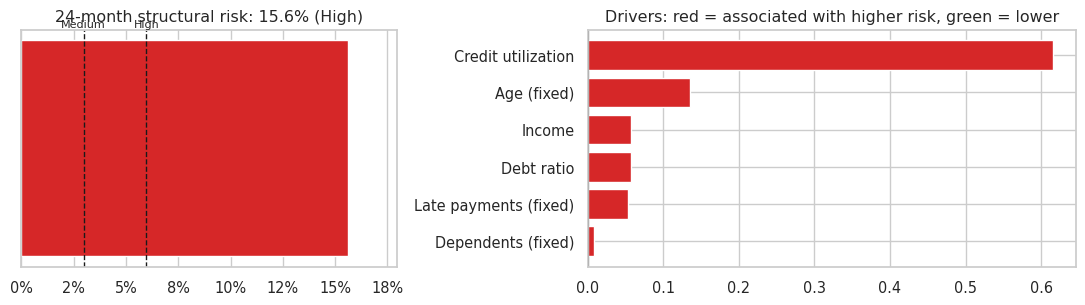


All Stage 12/13 checks passed.


In [63]:
# --------------------------------------------------------------------------
# Stage 12 + 13 demo and sanity checks
# --------------------------------------------------------------------------
SAVINGS = 15000   # EGP, user input

print("=== Savings coverage (baseline) ===")
print(json.dumps(savings_coverage(demo, SAVINGS, fixed_expenses=2000), indent=2, ensure_ascii=False))

print("\n=== Scenarios with coverage next to them ===")
display(run_all_with_coverage(demo, SAVINGS, fixed_expenses=2000))

print("\n=== Long-term (24-month) risk view ===")
view = long_term_risk_view(demo)
print(json.dumps(view, indent=2, ensure_ascii=False))
print_long_term_view(view)
print_long_term_view(view, lang="ar")
plot_long_term_view(view)

# ---- sanity checks (no retraining, no test-set use) ----
# coverage: more savings never makes things worse; bigger shock never makes things better
lo, hi = savings_coverage(demo, 5000, 2000), savings_coverage(demo, 50000, 2000)
assert hi["runway_months"] > lo["runway_months"]
assert _STATUS_RANK[hi["status"]] >= _STATUS_RANK[lo["status"]]
s_small, s_big = savings_coverage(demo, SAVINGS, 2000, 1000), savings_coverage(demo, SAVINGS, 2000, 9000)
assert s_big["savings_after_shock"] < s_small["savings_after_shock"]
assert _STATUS_RANK[s_big["status"]] <= _STATUS_RANK[s_small["status"]]
assert savings_coverage(demo, 0, 2000)["status"] == "critical"
# coverage must not change the model's output
assert view["risk"] == score_customer(demo)["risk"]
# long-term view: 24 months, no 30/90-day framing, associative wording only
assert view["horizon"] == "24 months" and not any(k in view for k in ("risk_30", "risk_90"))
assert all("cause" not in d["text"].lower() for d in view["drivers"])
assert {d["group"] for d in view["drivers"]} == set(GROUPS)
print("\nAll Stage 12/13 checks passed.")

---
# PART B — UCI Taiwan: monthly tracking, 30 / 90-day risk

# [UCI] Taiwan Credit Card Default — Full Pipeline
**Initial cleaning → EDA → Feature engineering → Train/test split** (single notebook, Taiwan dataset only)

This notebook merges three earlier notebooks into one top-to-bottom flow:

| Section | Source notebook |
|---|---|
| 1. Initial cleaning | `default_of_credit_card.ipynb` |
| 2. EDA | `Taiwan_EDA.ipynb` |
| 3. Feature engineering | `target_feature_engineering.ipynb` (Taiwan part) |
| 4. Train / test split | `target_feature_engineering.ipynb` (Taiwan part) |
| 6. Rolling as-of windows + 30/90-day models (plan points 1 & 2) | UCI Monthly Tracking plan — built step by step |

**Run all cells top to bottom.** Only one input is needed: the raw Taiwan CSV (`default_of_credit_card_clients(monthly tracking).csv`).

**How the three notebooks were reconciled**
- Cleaning keeps `SEX / EDUCATION / MARRIAGE` as **numeric codes** (the EDA rules and rate tables need the codes). The undocumented codes (`EDUCATION` 0/5/6, `MARRIAGE` 0) are merged into `"other"` in the feature-engineering step, as in the project plan.
- `PAY_0` is renamed to `PAY_1` once, in cleaning. Feature engineering then maps `PAY_k -> delay_status_k`.
- The client-level feature formulas live in **one function** (`client_level_features`). EDA uses it to test the features (univariate AUC), and feature engineering uses the very same function, so what was validated is exactly what gets built.
- The split is by client `ID` (each client has 6 monthly rows after reshaping), so no client appears in both train and test.

## [UCI] 0) Setup

In [64]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import seaborn as sns
from scipy import stats
from sklearn.metrics import roc_auc_score
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import train_test_split
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 170)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 11,
                     "axes.labelsize": 10, "figure.autolayout": True})
C0, C1 = "#4C78A8", "#E45756"            # blue = no default, red = default
CLASS_COLORS = {0: C0, 1: C1}
RNG = 42

# ------------------------------ EDIT THESE ------------------------------
RAW_PATH = "/content/default_of_credit_card_clients(monthly tracking).csv"   # raw Taiwan file
OUT_DIR = "."                    # where the output CSVs are written
TEST_SIZE = 0.2
RANDOM_STATE = 42
KEEP_DEMOGRAPHICS = False        # True -> also keep LIMIT_BAL, AGE, SEX, EDUCATION, MARRIAGE in the final table
# ------------------------------------------------------------------------

# Colab convenience: if the file is not at RAW_PATH, ask for an upload
if not os.path.exists(RAW_PATH):
    try:
        from google.colab import files as _colab_files
        _up = _colab_files.upload()
        RAW_PATH = next(iter(_up))
    except ImportError:
        raise FileNotFoundError(f"Raw file not found at {RAW_PATH}. Edit RAW_PATH in this cell.")
print("Using raw file:", RAW_PATH)

Using raw file: /mnt/user-data/uploads/default_of_credit_card_clients_monthly_tracking_.csv


In [65]:
# ---------------------------------------------------------------- EDA helpers
def wilson_ci(k, n, z=1.96):
    # Wilson score interval for a proportion (better than the normal approximation for small n / rare events)
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half


def rate_table(df, col, target, bins=None, q=None, cap=None, label_map=None):
    # Positive-class rate by group, with counts, Wilson CI and lift.
    # bins -> fixed cut points | q -> quantile bins | cap -> treat as count, lump values >= cap into 'cap+'
    s = df[col]
    if bins is not None:
        g = pd.cut(s, bins=bins, right=False, include_lowest=True)
    elif q is not None:
        g = pd.qcut(s, q=q, duplicates="drop")
    elif cap is not None:
        g = s.clip(upper=cap)
    else:
        g = s
    t = (pd.DataFrame({"g": g, "y": df[target]}).dropna(subset=["g"])
           .groupby("g", observed=True)["y"].agg(n="size", positives="sum"))
    t["rate"] = t["positives"] / t["n"]
    t["ci_lo"], t["ci_hi"] = wilson_ci(t["positives"], t["n"])
    t["lift"] = t["rate"] / df[target].mean()
    if cap is not None:
        t.index = [f"{int(i)}+" if i == cap else str(int(i)) for i in t.index]
    elif label_map is not None:
        t.index = [label_map.get(i, str(i)) for i in t.index]
    else:
        t.index = t.index.astype(str)
    return t


def _compact(n):
    return f"{n:,.0f}" if n < 1000 else f"{n / 1000:.1f}k" if n < 1e6 else f"{n / 1e6:.1f}M"


def plot_rate(t, ax, title, xlabel="", base=None, rotate=0):
    x = np.arange(len(t))
    ax.bar(x, t["rate"], color=C1, alpha=.85)
    err = np.vstack([t["rate"] - t["ci_lo"], t["ci_hi"] - t["rate"]])
    ax.errorbar(x, t["rate"], yerr=err, fmt="none", ecolor="black", capsize=3, lw=1)
    if base is not None:
        ax.axhline(base, color="black", ls="--", lw=1)
        title = f"{title}\n(dashed line = overall rate {base:.1%}; whiskers = 95% CI)"
    if len(t) <= 10:
        labels = [f"{i}\n(n={_compact(n)})" for i, n in zip(t.index, t["n"])]
    else:
        labels = list(t.index)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=rotate, ha="right" if rotate else "center", fontsize=8)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set_title(title, fontsize=10); ax.set_xlabel(xlabel); ax.set_ylabel("Positive-class rate")


def quantile_profile(df, cols):
    qs = [0, .01, .05, .25, .5, .75, .95, .99, .999, 1]
    t = df[cols].quantile(qs).T
    t.columns = ["min", "p1", "p5", "p25", "median", "p75", "p95", "p99", "p99.9", "max"]
    t["mean"] = df[cols].mean()
    t["std"] = df[cols].std()
    t["skew"] = df[cols].skew()
    t["kurtosis"] = df[cols].kurt()
    t["missing %"] = df[cols].isna().mean() * 100
    return t


def rules_table(df, target, rules):
    # Data-integrity rules: how many rows break each rule and how risky are those rows?
    base = df[target].mean()
    rows = []
    for name, mask in rules.items():
        mask = pd.Series(mask, index=df.index).fillna(False).astype(bool)
        n = int(mask.sum())
        r = df.loc[mask, target].mean() if n else np.nan
        rows.append({"rule": name, "rows": n, "% of data": 100 * n / len(df),
                     "positive rate (flagged rows)": r, "lift vs overall": r / base if n else np.nan})
    return pd.DataFrame(rows).set_index("rule")


def signal_table(df, feats, target, sample=30000):
    # Univariate predictive strength: AUC (rank-based, direction-free), Cliff's delta, mutual information, Mann-Whitney p.
    y = df[target].values
    X = df[feats].astype(float)
    Xf = X.fillna(X.median())
    idx = np.random.RandomState(RNG).choice(len(df), size=min(sample, len(df)), replace=False)
    mi = mutual_info_classif(Xf.iloc[idx], y[idx], random_state=RNG)
    rows = []
    for f, m in zip(feats, mi):
        x = Xf[f]
        if x.nunique() < 2:
            continue
        auc = roc_auc_score(y, x)
        rows.append({"feature": f, "AUC (direction-free)": max(auc, 1 - auc),
                     "direction": "higher = riskier" if auc >= .5 else "higher = safer",
                     "Cliff's delta": 2 * auc - 1, "mutual info": m,
                     "median | y=0": x[y == 0].median(), "median | y=1": x[y == 1].median(),
                     "Mann-Whitney p": stats.mannwhitneyu(x[y == 0], x[y == 1]).pvalue})
    return pd.DataFrame(rows).set_index("feature").sort_values("AUC (direction-free)", ascending=False)


def vif_table(X):
    # Variance-inflation factor computed with plain least squares (no statsmodels needed).
    Z = ((X - X.mean()) / X.std(ddof=0)).dropna()
    out = {}
    for c in Z.columns:
        y = Z[c].values
        A = np.column_stack([np.ones(len(Z)), Z.drop(columns=c).values])
        beta, *_ = np.linalg.lstsq(A, y, rcond=None)
        r2 = 1 - ((y - A @ beta) ** 2).sum() / ((y - y.mean()) ** 2).sum()
        out[c] = 1 / max(1 - r2, 1e-12)
    return pd.Series(out, name="VIF").sort_values(ascending=False).to_frame()


def cramers_v(a, b):
    ct = pd.crosstab(a, b)
    ct = ct.loc[ct.sum(axis=1) > 0, ct.sum(axis=0) > 0]          # drop empty categories
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    v = np.sqrt((chi2 / ct.values.sum()) / (min(ct.shape) - 1))
    return chi2, p, v


# ------------------------------------------------ client-level features (used by EDA *and* feature engineering)
def client_level_features(df, pay_cols):
    # One row per client. pay_cols = payment-status columns ordered k = 1..6 (k = 1 is the LATEST month, k = 6 the oldest).
    # BILL_AMT1..6, PAY_AMT1..6 and LIMIT_BAL follow the same convention.
    # Everything is flipped to oldest -> latest first, so a positive slope means "getting worse as we approach the present".
    # After the flip: columns 0..2 = Apr-Jun (prior), columns 3..5 = Jul-Sep (recent).
    bill_cols = [f"BILL_AMT{k}" for k in range(1, 7)]
    pamt_cols = [f"PAY_AMT{k}" for k in range(1, 7)]
    P = df[pay_cols[::-1]].values.astype(float)
    D = np.clip(P, 0, None)                              # months of delay (>= 0)
    B = df[bill_cols[::-1]].values.astype(float)
    A = df[pamt_cols[::-1]].values.astype(float)
    L = df["LIMIT_BAL"].values.astype(float)

    tt = np.arange(6) - 2.5
    slope = lambda M: ((M - M.mean(1, keepdims=True)) * tt).sum(1) / (tt ** 2).sum()

    run = np.zeros(len(P)); alive = np.ones(len(P), bool)
    for j in range(5, -1, -1):                           # consecutive late months ending at the latest month
        alive &= P[:, j] >= 1
        run += alive

    with np.errstate(divide="ignore", invalid="ignore"):  # never divide by a bill <= 0
        RR = np.clip(np.where(B[:, :-1] > 0, A[:, 1:] / B[:, :-1], np.nan), 0, 1)

    fe = pd.DataFrame(index=df.index)
    # --- payment status (severity, persistence, trend)
    fe["n_late_months"]              = (P >= 1).sum(1)
    fe["max_delay"]                  = D.max(1)
    fe["mean_delay"]                 = D.mean(1)
    fe["delay_trend"]                = slope(D)
    fe["recent_vs_hist_delay"]       = D[:, 3:].mean(1) - D[:, :3].mean(1)
    fe["consecutive_late_to_now"]    = run
    fe["n_revolving_months"]         = (P == 0).sum(1)
    fe["n_no_consumption_months"]    = (P == -2).sum(1)
    # --- bills (level, trend, volatility, utilization)
    fe["avg_bill"]                   = B.mean(1)
    fe["max_bill"]                   = B.max(1)
    fe["bill_trend_over_limit"]      = slope(B) / L
    fe["bill_volatility_over_limit"] = B.std(1) / L
    fe["avg_utilization"]            = B.mean(1) / L
    fe["latest_utilization"]         = B[:, -1] / L
    # --- payments (level, trend, discipline)
    fe["avg_payment"]                = A.mean(1)
    fe["max_payment"]                = A.max(1)
    fe["payment_trend_over_limit"]   = slope(A) / L
    fe["n_zero_payment_months"]      = (A == 0).sum(1)
    fe["avg_pay_ratio"]              = np.nanmean(RR, 1)
    fe["min_pay_ratio"]              = np.nanmin(RR, 1)
    fe["latest_pay_ratio"]           = RR[:, -1]
    fe["n_low_pay_months"]           = (RR < .1).sum(1)          # paid < 10 % of the previous bill
    fe["cash_gap_latest"]            = (B[:, -2] - A[:, -1]) / L  # unpaid part of previous bill, relative to limit
    # --- recent (Jul-Sep) vs prior (Apr-Jun) lateness
    fe["derived_late_recent"]        = (P[:, 3:] >= 1).sum(1)
    fe["derived_late_prior"]         = (P[:, :3] >= 1).sum(1)
    fe["derived_late_trend"]         = fe["derived_late_recent"] - fe["derived_late_prior"]
    return fe


def trajectory_label(fe):
    return np.select(
        [fe["max_delay"] == 0, fe["delay_trend"] > .15, fe["delay_trend"] < -.15],
        ["1 · never late", "4 · deteriorating", "2 · improving"], default="3 · late, flat trend")

---
## 1) Initial cleaning
Source: `default_of_credit_card.ipynb`. Standardize names, fix types, remove duplicates, flag impossible values, drop empty/constant columns, check for leakage.

In [66]:
# 1.1) Load the raw data
df = pd.read_csv(RAW_PATH)
print("Shape before cleaning:", df.shape)
df.info()

Shape before cleaning: (30000, 25)
<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non

In [67]:
# 1.2) Standardize column names
df.columns = (
    df.columns
    .str.strip()                                   # remove extra spaces from the header itself
    .str.upper()                                   # unify case
    .str.replace(" ", "_")                         # spaces -> underscore
    .str.replace(r"[^A-Z0-9_]", "", regex=True)    # remove any weird symbols
)

# Known naming issue in this dataset: PAY_0 is actually PAY_1 (the latest month)
df.rename(columns={"PAY_0": "PAY_1"}, inplace=True)

print("Column names after standardization:")
print(df.columns.tolist())

Column names after standardization:
['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_1', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'DEFAULT_PAYMENT_NEXT_MONTH']


In [68]:
# 1.3) Strip extra whitespace from text values (NaN stays NaN)
obj_cols = df.select_dtypes(include=["object", "string"]).columns
for col in obj_cols:
    df[col] = df[col].str.strip()
print("Text columns:", list(obj_cols))

Text columns: []


In [69]:
# 1.4) Convert "empty-like" values into real NaN
na_like = ["NA", "N/A", "na", "n/a", "", "null", "NULL", "None", "-", "?"]
df.replace(na_like, np.nan, inplace=True)

miss = df.isnull().sum()
print("Missing value counts per column:")
print(miss[miss > 0] if (miss > 0).any() else "  none")

Missing value counts per column:
  none


In [70]:
# 1.5) Fix data types: object columns that are really numeric
for col in df.select_dtypes(include=["object", "string"]).columns:
    converted = pd.to_numeric(df[col], errors="coerce")
    if converted.notna().sum() >= 0.9 * df[col].notna().sum():
        df[col] = converted

print("Dtypes after fixing:")
print(df.dtypes.value_counts())

Dtypes after fixing:
int64    25
Name: count, dtype: int64


In [71]:
# 1.6) Remove true duplicates
before = df.shape[0]
df.drop_duplicates(inplace=True)

if "ID" in df.columns:
    dup_ids = df["ID"].duplicated().sum()
    print(f"Number of duplicated IDs: {dup_ids}")
    df.drop_duplicates(subset="ID", keep="first", inplace=True)

print(f"Removed {before - df.shape[0]} duplicate rows")

Number of duplicated IDs: 0
Removed 0 duplicate rows


In [72]:
# 1.7) Impossible values
if "AGE" in df.columns:
    bad_age = (df["AGE"] < 0) | (df["AGE"] > 100)
    print(f"Number of invalid AGE rows: {int(bad_age.sum())}")
    df.loc[bad_age, "AGE"] = np.nan

# a credit limit must be positive (reported only, same as the original notebook)
if "LIMIT_BAL" in df.columns:
    print(f"Number of invalid LIMIT_BAL values (<= 0): {int((df['LIMIT_BAL'] <= 0).sum())}")

Number of invalid AGE rows: 0
Number of invalid LIMIT_BAL values (<= 0): 0


In [73]:
# 1.8) Categorical codes: SEX / EDUCATION / MARRIAGE stay NUMERIC here.
# The EDA (section 2) works on the codes. Undocumented codes (EDUCATION 0/5/6, MARRIAGE 0) are merged into
# "other" later, in the feature-engineering step (section 3), after the EDA has shown their default rates.
for col in ["SEX", "EDUCATION", "MARRIAGE"]:
    if col in df.columns:
        print(f"\n{col}:")
        print(df[col].value_counts().sort_index())


SEX:
SEX
1    11888
2    18112
Name: count, dtype: int64

EDUCATION:
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

MARRIAGE:
MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64


In [74]:
# 1.9) Drop columns that are fully empty or constant
empty_cols = [c for c in df.columns if df[c].isnull().all()]
constant_cols = [c for c in df.columns if df[c].nunique(dropna=True) <= 1]
cols_to_drop = list(set(empty_cols + constant_cols))
print(f"Fully empty columns: {empty_cols}")
print(f"Constant columns:    {constant_cols}")
df.drop(columns=cols_to_drop, inplace=True)

Fully empty columns: []
Constant columns:    []


In [75]:
# 1.10) Leakage check: ID-like columns and columns suspiciously correlated with the target
target_candidates = [c for c in df.columns if "DEFAULT" in c.upper()]
assert target_candidates, "No target column found (expected a column containing 'DEFAULT')."
TARGET_RAW = target_candidates[0]
print(f"Detected target column: {TARGET_RAW}")

id_like_cols = [c for c in df.columns if c.upper() == "ID" or c.upper().endswith("_ID")]
print(f"ID-like columns (kept for grouping, never used as a model feature): {id_like_cols}")

numeric_df = df.select_dtypes(include=[np.number])
corr = numeric_df.corr()[TARGET_RAW].sort_values(ascending=False)
print("\nCorrelation with target:")
print(corr)
suspicious = corr[(corr.abs() > 0.9) & (corr.index != TARGET_RAW)]
print(f"\nSuspicious potential leakage columns (|corr| > 0.9): {suspicious.index.tolist()}")

Detected target column: DEFAULT_PAYMENT_NEXT_MONTH
ID-like columns (kept for grouping, never used as a model feature): ['ID']



Correlation with target:
DEFAULT_PAYMENT_NEXT_MONTH    1.0000
PAY_1                         0.3248
PAY_2                         0.2636
PAY_3                         0.2353
PAY_4                         0.2166
PAY_5                         0.2041
PAY_6                         0.1869
EDUCATION                     0.0280
AGE                           0.0139
BILL_AMT6                    -0.0054
BILL_AMT5                    -0.0068
BILL_AMT4                    -0.0102
ID                           -0.0140
BILL_AMT3                    -0.0141
BILL_AMT2                    -0.0142
BILL_AMT1                    -0.0196
MARRIAGE                     -0.0243
SEX                          -0.0400
PAY_AMT6                     -0.0532
PAY_AMT5                     -0.0551
PAY_AMT3                     -0.0563
PAY_AMT4                     -0.0568
PAY_AMT2                     -0.0586
PAY_AMT1                     -0.0729
LIMIT_BAL                    -0.1535
Name: DEFAULT_PAYMENT_NEXT_MONTH, dtype: float64


In [76]:
# 1.11) Final look + save the cleaned (wide) file
clean = df.reset_index(drop=True).copy()
print("Shape after cleaning:", clean.shape)
display(clean.describe(include="all").T)

clean.to_csv(os.path.join(OUT_DIR, "default_of_credit_card_clients_cleaned.csv"), index=False)
print("\nSaved: default_of_credit_card_clients_cleaned.csv")

Shape after cleaning: (30000, 25)


,count,mean,std,min,25%,50%,75%,max
ID,"30,000.0000","15,000.5000","8,660.3984",1.0000,"7,500.7500","15,000.5000","22,500.2500","30,000.0000"
LIMIT_BAL,"30,000.0000","167,484.3227","129,747.6616","10,000.0000","50,000.0000","140,000.0000","240,000.0000","1,000,000.0000"
SEX,"30,000.0000",1.6037,0.4891,1.0000,1.0000,2.0000,2.0000,2.0000
EDUCATION,"30,000.0000",1.8531,0.7903,0.0000,1.0000,2.0000,2.0000,6.0000
MARRIAGE,"30,000.0000",1.5519,0.5220,0.0000,1.0000,2.0000,2.0000,3.0000
AGE,"30,000.0000",35.4855,9.2179,21.0000,28.0000,34.0000,41.0000,79.0000
PAY_1,"30,000.0000",-0.0167,1.1238,-2.0000,-1.0000,0.0000,0.0000,8.0000
PAY_2,"30,000.0000",-0.1338,1.1972,-2.0000,-1.0000,0.0000,0.0000,8.0000
PAY_3,"30,000.0000",-0.1662,1.1969,-2.0000,-1.0000,0.0000,0.0000,8.0000
PAY_4,"30,000.0000",-0.2207,1.1691,-2.0000,-1.0000,0.0000,0.0000,8.0000



Saved: default_of_credit_card_clients_cleaned.csv


---
## 2) Exploratory data analysis
Source: `Taiwan_EDA.ipynb`. Works on the cleaned wide table (one row per client). Month convention used everywhere: **k = 1 is the LATEST observed month (t), k = 6 the OLDEST (t-5)**.

In [77]:
tw_raw = clean.copy()
tw = tw_raw.copy()
tw.columns = [c.strip() for c in tw.columns]

TW_T = "default"
tgt_col = [c for c in tw.columns if "default" in c.lower()][0]
tw = tw.rename(columns={tgt_col: TW_T})
if "PAY_0" in tw.columns:                       # already renamed in cleaning; kept as a safety net
    tw = tw.rename(columns={"PAY_0": "PAY_1"})
tw[TW_T] = tw[TW_T].astype(int)

TW_PAY  = [f"PAY_{k}" for k in range(1, 7)]
TW_BILL = [f"BILL_AMT{k}" for k in range(1, 7)]
TW_PAMT = [f"PAY_AMT{k}" for k in range(1, 7)]
TW_DEMO = ["LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE"]
TW_FEATS = TW_DEMO + TW_PAY + TW_BILL + TW_PAMT
TW_BASE = tw[TW_T].mean()
MLBL = {k: ("t" if k == 1 else f"t-{k - 1}") for k in range(1, 7)}

print(f"Rows: {len(tw):,}   Columns: {tw.shape[1]}   (target column '{tgt_col}' renamed to '{TW_T}')")
print(f"Duplicate customer IDs: {tw['ID'].duplicated().sum() if 'ID' in tw else 'n/a'}   |   duplicate rows ignoring ID: {tw.drop(columns=[c for c in ['ID'] if c in tw]).duplicated().sum():,}")
print(f"Missing cells: {int(tw.isna().sum().sum())}")
display(pd.DataFrame({"dtype": tw.dtypes.astype(str), "missing": tw.isna().sum(), "unique values": tw.nunique(),
                      "min": tw.min(numeric_only=True), "max": tw.max(numeric_only=True)}))

Rows: 30,000   Columns: 25   (target column 'DEFAULT_PAYMENT_NEXT_MONTH' renamed to 'default')


Duplicate customer IDs: 0   |   duplicate rows ignoring ID: 35
Missing cells: 0


,dtype,missing,unique values,min,max
ID,int64,0,30000,1.0000,"30,000.0000"
LIMIT_BAL,int64,0,81,"10,000.0000","1,000,000.0000"
SEX,int64,0,2,1.0000,2.0000
EDUCATION,int64,0,7,0.0000,6.0000
MARRIAGE,int64,0,4,0.0000,3.0000
AGE,float64,0,56,21.0000,79.0000
PAY_1,int64,0,11,-2.0000,8.0000
PAY_2,int64,0,11,-2.0000,8.0000
PAY_3,int64,0,11,-2.0000,8.0000
PAY_4,int64,0,11,-2.0000,8.0000


### [UCI] 2.1 Target distribution

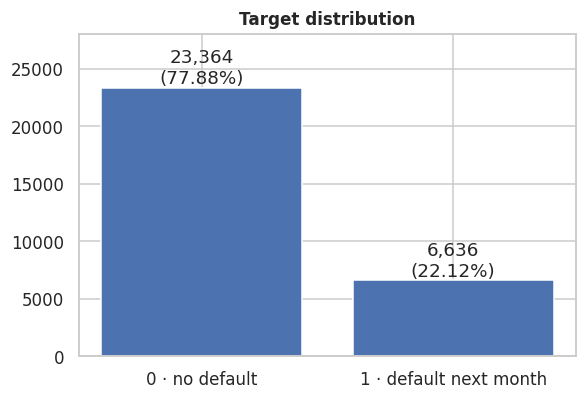

Positive rate: 22.12% (reference document: ~22.12%)  |  imbalance ratio ≈ 3.5 : 1  (moderate)


In [78]:
vc = tw[TW_T].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5.5, 3.8))
ax.bar(["0 · no default", "1 · default next month"], vc.values)
for i, v in enumerate(vc.values):
    ax.text(i, v, f"{v:,}\n({v / len(tw):.2%})", ha="center", va="bottom")
ax.set_ylim(0, vc.max() * 1.2); ax.set_title("Target distribution")
plt.show()
print(f"Positive rate: {TW_BASE:.2%} (reference document: ~22.12%)  |  imbalance ratio ≈ {(1 - TW_BASE) / TW_BASE:.1f} : 1  (moderate)")

The positive class is ≈ 22 %: a **moderate imbalance**. Use stratified splits/CV and imbalance-aware metrics.

### [UCI] 2.2 Category codes and data-integrity rules

In [79]:
edu_map  = {0: "0 · undocumented", 1: "1 · graduate school", 2: "2 · university", 3: "3 · high school", 4: "4 · other", 5: "5 · undocumented", 6: "6 · undocumented"}
mar_map  = {0: "0 · undocumented", 1: "1 · married", 2: "2 · single", 3: "3 · other"}
sex_map  = {1: "1 · male", 2: "2 · female"}

print("Category codes actually present:")
for c, m in [("SEX", sex_map), ("EDUCATION", edu_map), ("MARRIAGE", mar_map)]:
    vc = tw[c].value_counts().sort_index()
    display(pd.DataFrame({"code meaning": [m.get(i, "UNKNOWN CODE") for i in vc.index], "rows": vc.values,
                          "% of data": vc.values / len(tw) * 100,
                          "default rate": tw.groupby(c)[TW_T].mean().reindex(vc.index).values}, index=vc.index).rename_axis(c))

Category codes actually present:


,code meaning,rows,% of data,default rate
SEX,,,,
1,1 · male,11888,39.6267,0.2417
2,2 · female,18112,60.3733,0.2078


,code meaning,rows,% of data,default rate
EDUCATION,,,,
0,0 · undocumented,14,0.0467,0.0000
1,1 · graduate school,10585,35.2833,0.1923
2,2 · university,14030,46.7667,0.2373
3,3 · high school,4917,16.3900,0.2516
4,4 · other,123,0.4100,0.0569
5,5 · undocumented,280,0.9333,0.0643
6,6 · undocumented,51,0.1700,0.1569


,code meaning,rows,% of data,default rate
MARRIAGE,,,,
0,0 · undocumented,54,0.1800,0.0926
1,1 · married,13659,45.5300,0.2347
2,2 · single,15964,53.2133,0.2093
3,3 · other,323,1.0767,0.2601


In [80]:
print("Payment-status codes per month (rows = code, columns = month; -2 no consumption, -1 paid duly, 0 revolving, k>=1 delayed k months):")
pay_counts = pd.DataFrame({f"{c} ({MLBL[int(c[-1])]})": tw[c].value_counts() for c in TW_PAY}).fillna(0).astype(int).sort_index()
display(pay_counts)

Payment-status codes per month (rows = code, columns = month; -2 no consumption, -1 paid duly, 0 revolving, k>=1 delayed k months):


,PAY_1 (t),PAY_2 (t-1),PAY_3 (t-2),PAY_4 (t-3),PAY_5 (t-4),PAY_6 (t-5)
-2,2759,3782,4085,4348,4546,4895
-1,5686,6050,5938,5687,5539,5740
0,14737,15730,15764,16455,16947,16286
1,3688,28,4,2,0,0
2,2667,3927,3819,3159,2626,2766
3,322,326,240,180,178,184
4,76,99,76,69,84,49
5,26,25,21,35,17,13
6,11,12,23,5,4,19
7,9,20,27,58,58,46


In [81]:
rules_tw = {
    "EDUCATION ∈ {0,5,6} (undocumented code)": ~tw["EDUCATION"].isin([1, 2, 3, 4]),
    "MARRIAGE == 0 (undocumented code)": ~tw["MARRIAGE"].isin([1, 2, 3]),
    "Any PAY_k == -2 ('no consumption')": (tw[TW_PAY] == -2).any(axis=1),
    "Any PAY_k == 0 (revolving; not in the original codebook)": (tw[TW_PAY] == 0).any(axis=1),
    "Any PAY_k >= 1 (delayed payment)": (tw[TW_PAY] >= 1).any(axis=1),
    "Any PAY_k >= 4 (long delay)": (tw[TW_PAY] >= 4).any(axis=1),
    "Any BILL_AMT < 0 (credit balance / refund)": (tw[TW_BILL] < 0).any(axis=1),
    "Any BILL_AMT > LIMIT_BAL (over limit)": tw[TW_BILL].gt(tw["LIMIT_BAL"], axis=0).any(axis=1),
    "All six BILL_AMT == 0 (dormant card)": (tw[TW_BILL] == 0).all(axis=1),
    "All six PAY_AMT == 0 (never paid anything)": (tw[TW_PAMT] == 0).all(axis=1),
    "PAY_1 == -1 (paid duly) but PAY_AMT1 == 0 while BILL_AMT2 > 0": (tw["PAY_1"] == -1) & (tw["PAY_AMT1"] == 0) & (tw["BILL_AMT2"] > 0),
    "AGE < 21": tw["AGE"] < 21,
    "AGE > 70": tw["AGE"] > 70,
}
display(rules_table(tw, TW_T, rules_tw))

,rows,% of data,positive rate (flagged rows),lift vs overall
rule,,,,
"EDUCATION ∈ {0,5,6} (undocumented code)",345,1.1500,0.0754,0.3407
MARRIAGE == 0 (undocumented code),54,0.1800,0.0926,0.4186
Any PAY_k == -2 ('no consumption'),6561,21.8700,0.1907,0.8620
Any PAY_k == 0 (revolving; not in the original codebook),21173,70.5767,0.2006,0.9068
Any PAY_k >= 1 (delayed payment),10069,33.5633,0.4273,1.9315
Any PAY_k >= 4 (long delay),404,1.3467,0.6411,2.8982
Any BILL_AMT < 0 (credit balance / refund),1930,6.4333,0.1648,0.7449
Any BILL_AMT > LIMIT_BAL (over limit),3931,13.1033,0.3009,1.3605
All six BILL_AMT == 0 (dormant card),866,2.8867,0.3661,1.6548


In [82]:
display(quantile_profile(tw, ["LIMIT_BAL", "AGE"] + TW_BILL + TW_PAMT))

,min,p1,p5,p25,median,p75,p95,p99,p99.9,max,mean,std,skew,kurtosis,missing %
LIMIT_BAL,"10,000.0000","10,000.0000","20,000.0000","50,000.0000","140,000.0000","240,000.0000","430,000.0000","500,000.0000","700,000.0000","1,000,000.0000","167,484.3227","129,747.6616",0.9929,0.5363,0.0000
AGE,21.0000,22.0000,23.0000,28.0000,34.0000,41.0000,53.0000,60.0000,69.0000,79.0000,35.4855,9.2179,0.7322,0.0443,0.0000
BILL_AMT1,"-165,580.0000",-81.0000,0.0000,"3,558.7500","22,381.5000","67,091.0000","201,203.0500","350,110.6800","519,901.5520","964,511.0000","51,223.3309","73,635.8606",2.6639,9.8063,0.0000
BILL_AMT2,"-69,777.0000",-200.0000,0.0000,"2,984.7500","21,200.0000","64,006.2500","194,792.2000","337,495.2800","509,230.2410","983,931.0000","49,179.0752","71,173.7688",2.7052,10.3029,0.0000
BILL_AMT3,"-157,264.0000",-200.0000,0.0000,"2,666.2500","20,088.5000","60,164.7500","187,821.0500","325,030.3900","491,956.7620","1,664,089.0000","47,013.1548","69,349.3874",3.0878,19.7833,0.0000
BILL_AMT4,"-170,000.0000",-212.0200,0.0000,"2,326.7500","19,052.0000","54,506.0000","174,333.3500","304,997.2700","479,800.1780","891,586.0000","43,262.9490","64,332.8561",2.8220,11.3093,0.0000
BILL_AMT5,"-81,334.0000",-232.0100,0.0000,"1,763.0000","18,104.5000","50,190.5000","165,794.3000","285,868.3300","454,852.7950","927,171.0000","40,311.4010","60,797.1558",2.8764,12.3059,0.0000
BILL_AMT6,"-339,603.0000",-331.0300,0.0000,"1,256.0000","17,071.0000","49,198.2500","161,912.0000","279,505.0600","447,544.4830","961,664.0000","38,871.7604","59,554.1075",2.8466,12.2707,0.0000
PAY_AMT1,0.0000,0.0000,0.0000,"1,000.0000","2,100.0000","5,006.0000","18,428.2000","66,522.1800","231,788.7690","873,552.0000","5,663.5805","16,563.2804",14.6684,415.2547,0.0000
PAY_AMT2,0.0000,0.0000,0.0000,833.0000,"2,009.0000","5,000.0000","19,004.3500","76,651.0200","263,113.1130","1,684,259.0000","5,921.1635","23,040.8704",30.4538,"1,641.6319",0.0000


**ML implication.**
| Finding | Decision |
|---|---|
| `EDUCATION` ∈ {0, 5, 6} and `MARRIAGE` = 0 are undocumented | Merge into the documented "other" bucket **or** keep a separate "unknown" level — decide from the default rates shown above (do not drop rows). *This pipeline merges them into `"other"` in section 3.* |
| `SEX`, `EDUCATION`, `MARRIAGE` are nominal codes | One-hot / target-safe encoding; **never** treat as ordered numbers (except a defensible ordinal `EDUCATION`) |
| `PAY_k` mixes three meanings (−2, −1, 0 = no delay; ≥ 1 = delay) | Keep the raw code for trees; create `delay = max(PAY,0)` and separate flags (`revolving`, `no_consumption`) for linear models |
| Negative bills / bills above limit | Genuine credit balances or over-limit usage — **keep** (they are informative), cap extremes |
| Amounts are heavily right-skewed with a spike at 0 | `log1p` / signed-log, plus "zero" flags |

### [UCI] 2.3 Demographics

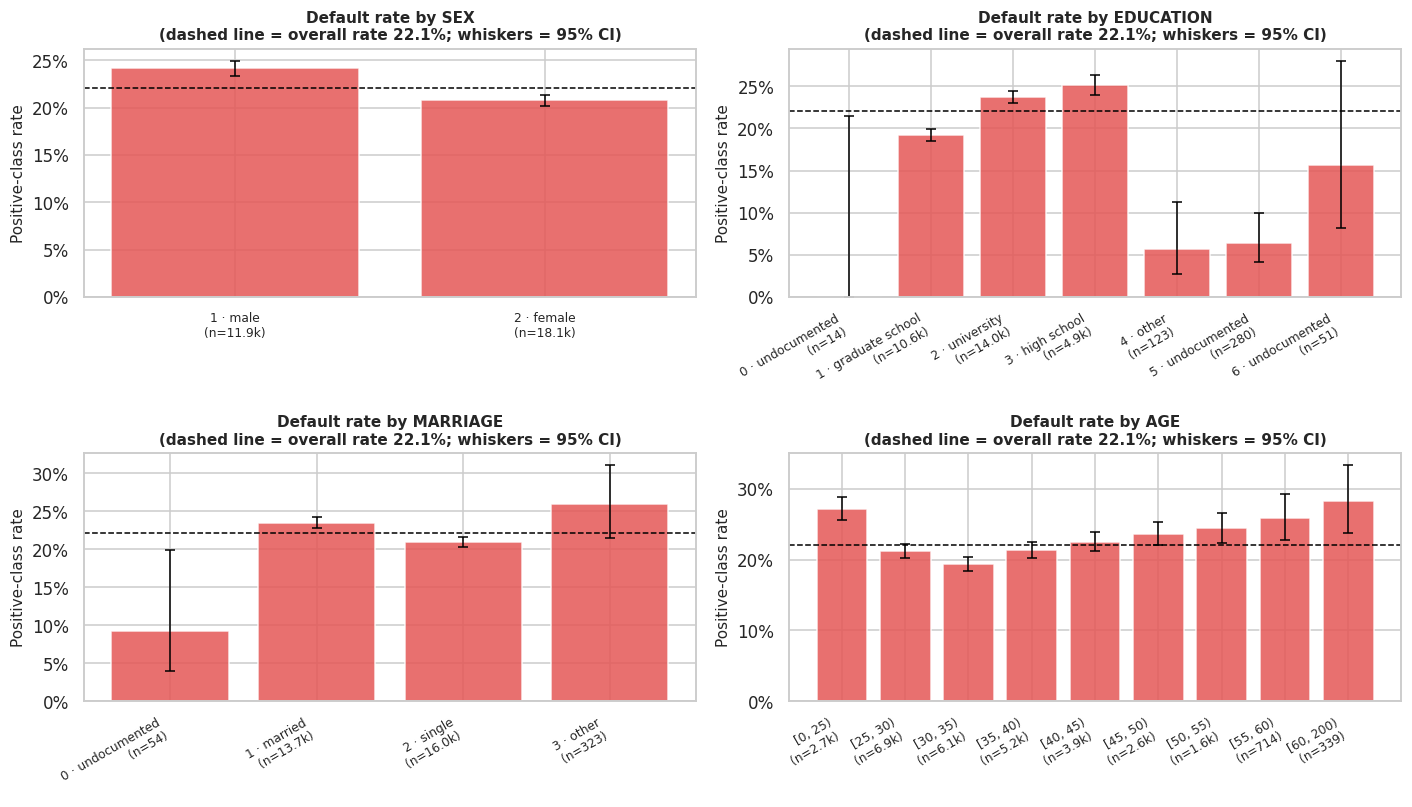

,chi²,p-value,Cramér's V (effect size)
variable,,,
SEX,47.7088,0.0000,0.0399
EDUCATION,163.2166,0.0000,0.0738
MARRIAGE,35.6624,0.0000,0.0345
age_bin,95.5185,0.0000,0.0564


In [83]:
tw["age_bin"] = pd.cut(tw["AGE"], [0, 25, 30, 35, 40, 45, 50, 55, 60, 200], right=False)
fig, axes = plt.subplots(2, 2, figsize=(13, 7.5))
tw_demo_rates = {
    "SEX": rate_table(tw, "SEX", TW_T, label_map=sex_map),
    "EDUCATION": rate_table(tw, "EDUCATION", TW_T, label_map=edu_map),
    "MARRIAGE": rate_table(tw, "MARRIAGE", TW_T, label_map=mar_map),
    "AGE": rate_table(tw, "age_bin", TW_T),
}
for ax, (name, t) in zip(axes.ravel(), tw_demo_rates.items()):
    plot_rate(t, ax, f"Default rate by {name}", base=TW_BASE, rotate=30 if name != "SEX" else 0)
plt.show()

rows = []
for c in ["SEX", "EDUCATION", "MARRIAGE", "age_bin"]:
    chi2, p, v = cramers_v(tw[c], tw[TW_T])
    rows.append({"variable": c, "chi²": chi2, "p-value": p, "Cramér's V (effect size)": v})
display(pd.DataFrame(rows).set_index("variable"))

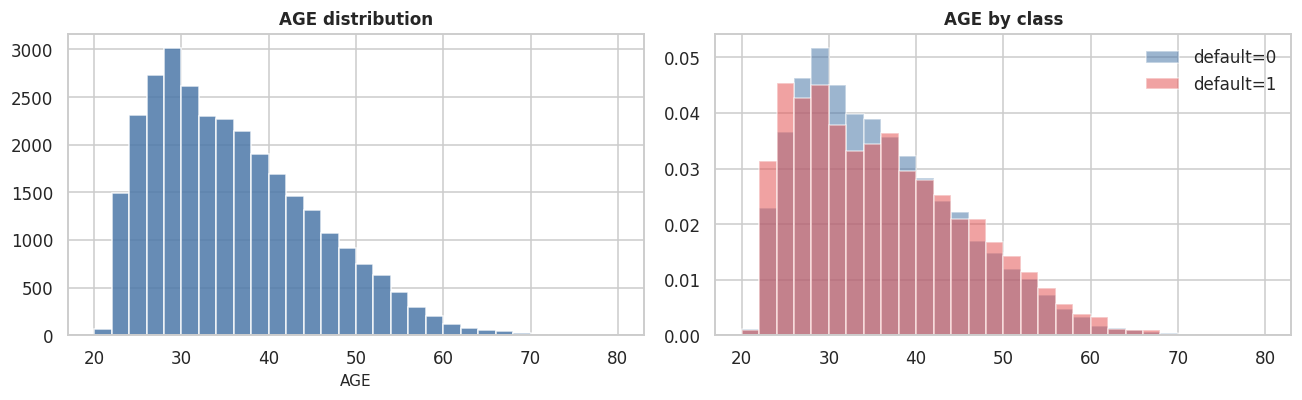

In [84]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(tw["AGE"], bins=range(20, 82, 2), color=C0, alpha=.85); axes[0].set_title("AGE distribution"); axes[0].set_xlabel("AGE")
for k, col in CLASS_COLORS.items():
    axes[1].hist(tw.loc[tw[TW_T] == k, "AGE"], bins=range(20, 82, 2), density=True, alpha=.55, color=col, label=f"default={k}")
axes[1].set_title("AGE by class"); axes[1].legend(frameon=False)
plt.show()

### [UCI] 2.4 Credit limit (`LIMIT_BAL`)

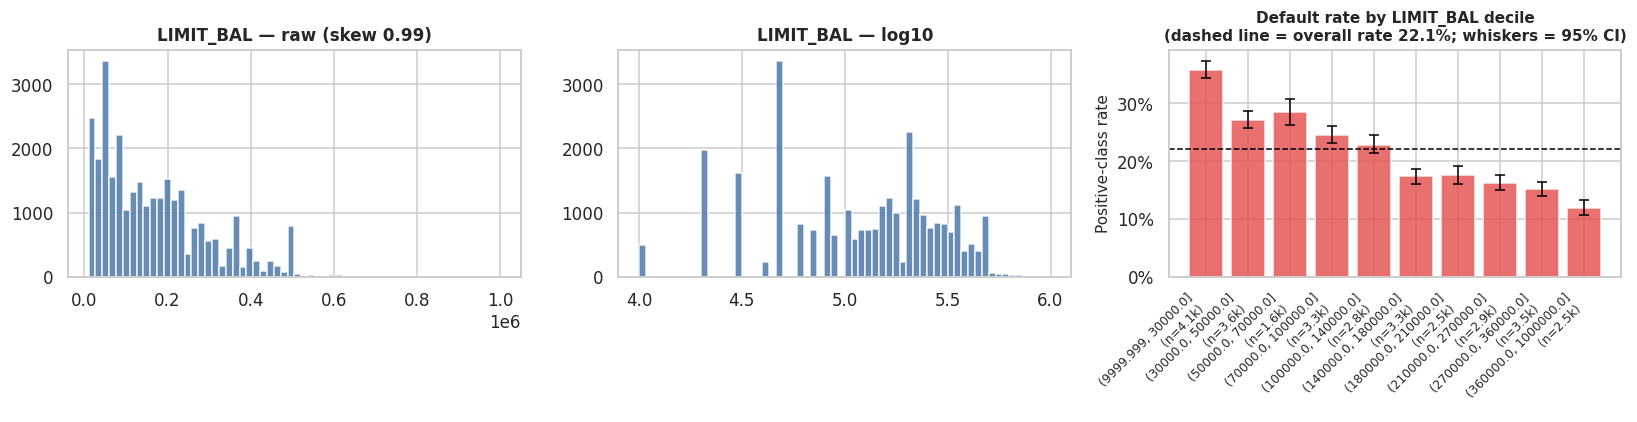

,mean,25%,50%,75%
default,,,,
0,"178,099.7261","70,000.0000","150,000.0000","250,000.0000"
1,"130,109.6564","50,000.0000","90,000.0000","200,000.0000"


Mann-Whitney p = 1.23e-189   |   AUC of LIMIT_BAL alone = 0.618


In [85]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(tw["LIMIT_BAL"], bins=60, color=C0, alpha=.85); axes[0].set_title(f"LIMIT_BAL — raw (skew {tw['LIMIT_BAL'].skew():.2f})")
axes[1].hist(np.log10(tw["LIMIT_BAL"].clip(lower=1)), bins=60, color=C0, alpha=.85); axes[1].set_title("LIMIT_BAL — log10")
plot_rate(rate_table(tw, "LIMIT_BAL", TW_T, q=10), axes[2], "Default rate by LIMIT_BAL decile", base=TW_BASE, rotate=45)
plt.show()

lim = tw.groupby(TW_T)["LIMIT_BAL"].describe()[["mean", "25%", "50%", "75%"]]
display(lim)
u = stats.mannwhitneyu(tw.loc[tw[TW_T] == 0, "LIMIT_BAL"], tw.loc[tw[TW_T] == 1, "LIMIT_BAL"])
print(f"Mann-Whitney p = {u.pvalue:.2e}   |   AUC of LIMIT_BAL alone = {max(roc_auc_score(tw[TW_T], tw['LIMIT_BAL']), 1 - roc_auc_score(tw[TW_T], tw['LIMIT_BAL'])):.3f}")

### [UCI] 2.5 Payment status: how late, and for how many months?

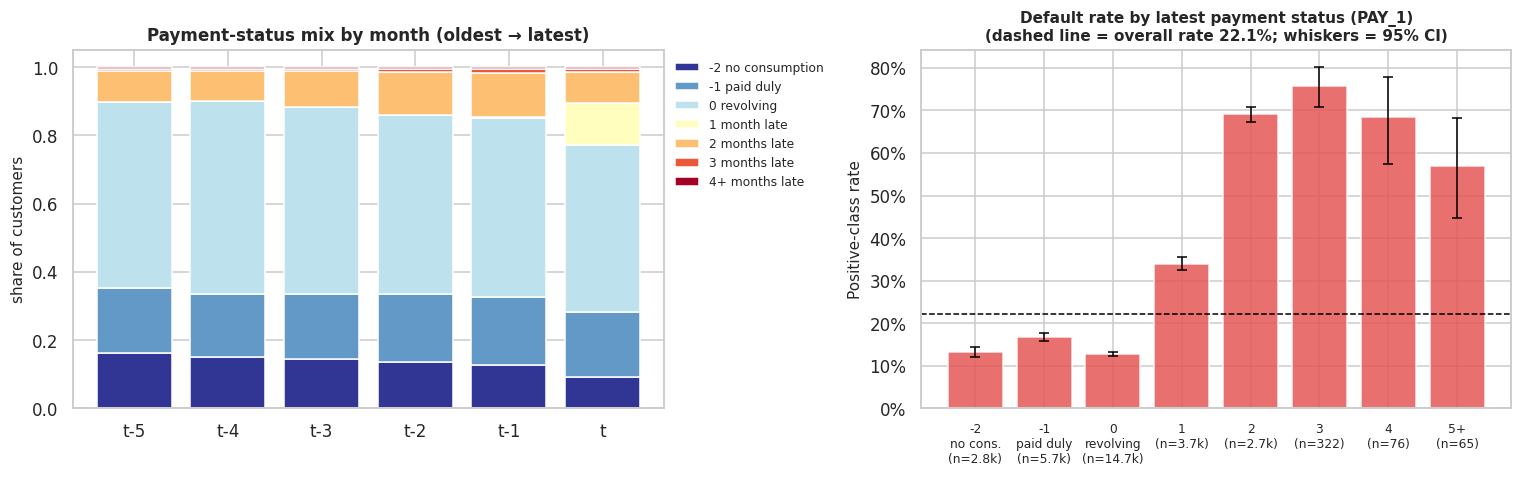

,n,positives,rate,ci_lo,ci_hi,lift
-2\nno cons.,2759,365,0.1323,0.1202,0.1454,0.5981
-1\npaid duly,5686,954,0.1678,0.1583,0.1777,0.7585
0\nrevolving,14737,1888,0.1281,0.1228,0.1336,0.5792
1,3688,1252,0.3395,0.3244,0.3549,1.5347
2,2667,1844,0.6914,0.6736,0.7087,3.1257
3,322,244,0.7578,0.7081,0.8013,3.4257
4,76,52,0.6842,0.5730,0.7777,3.0932
5+,65,37,0.5692,0.4483,0.6824,2.5734


In [86]:
order = [6, 5, 4, 3, 2, 1]                                   # oldest -> latest for time-ordered plots
cats = [-2, -1, 0, 1, 2, 3, 4]
dist = pd.DataFrame({MLBL[k]: tw[f"PAY_{k}"].clip(-2, 4).value_counts(normalize=True).reindex(cats).fillna(0) for k in order})
dist.index = ["-2 no consumption", "-1 paid duly", "0 revolving", "1 month late", "2 months late", "3 months late", "4+ months late"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
dist.T.plot(kind="bar", stacked=True, ax=axes[0], colormap="RdYlBu_r", width=.8)
axes[0].set_title("Payment-status mix by month (oldest → latest)"); axes[0].set_ylabel("share of customers")
axes[0].legend(bbox_to_anchor=(1.0, 1), frameon=False, fontsize=8); axes[0].tick_params(axis="x", rotation=0)

t = rate_table(tw, "PAY_1", TW_T, cap=5)
t.index = [{"-2": "-2\nno cons.", "-1": "-1\npaid duly", "0": "0\nrevolving"}.get(i, i) for i in t.index]
plot_rate(t, axes[1], "Default rate by latest payment status (PAY_1)", base=TW_BASE)
plt.show()
display(t)

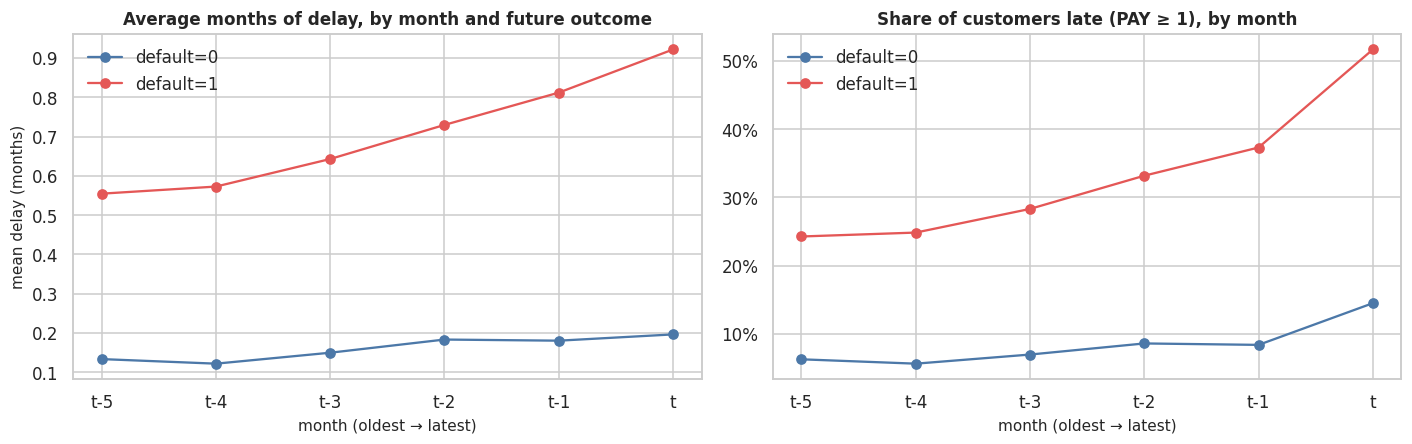

In [87]:
delay = {k: tw[f"PAY_{k}"].clip(lower=0) for k in order}
late  = {k: (tw[f"PAY_{k}"] >= 1).astype(int) for k in order}
traj_delay = pd.DataFrame({MLBL[k]: delay[k].groupby(tw[TW_T]).mean() for k in order})
traj_late  = pd.DataFrame({MLBL[k]: late[k].groupby(tw[TW_T]).mean() for k in order})

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for cls, col in CLASS_COLORS.items():
    axes[0].plot(traj_delay.columns, traj_delay.loc[cls], marker="o", color=col, label=f"default={cls}")
    axes[1].plot(traj_late.columns, traj_late.loc[cls], marker="o", color=col, label=f"default={cls}")
axes[0].set_title("Average months of delay, by month and future outcome"); axes[0].set_ylabel("mean delay (months)")
axes[1].set_title("Share of customers late (PAY ≥ 1), by month"); axes[1].yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
for ax in axes: ax.legend(frameon=False); ax.set_xlabel("month (oldest → latest)")
plt.show()

**Persistence:** how likely is a customer to stay late from one month to the next?

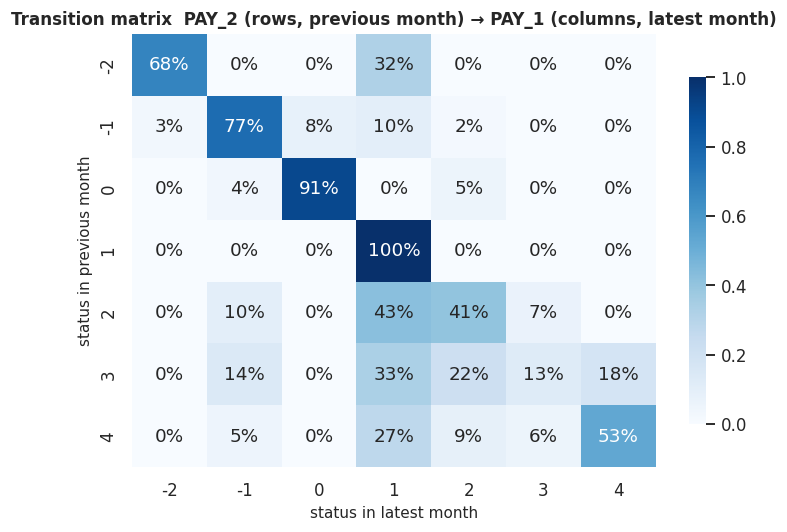

P(late this month | late last month)  = 89.9%
P(late this month | not late last month) = 11.1%


In [88]:
tr = pd.crosstab(tw["PAY_2"].clip(-2, 4), tw["PAY_1"].clip(-2, 4), normalize="index")
fig, ax = plt.subplots(figsize=(6.8, 5))
sns.heatmap(tr, annot=True, fmt=".0%", cmap="Blues", ax=ax, cbar_kws={"shrink": .8})
ax.set_title("Transition matrix  PAY_2 (rows, previous month) → PAY_1 (columns, latest month)")
ax.set_xlabel("status in latest month"); ax.set_ylabel("status in previous month")
plt.show()

stay = ((tw["PAY_2"] >= 1) & (tw["PAY_1"] >= 1)).sum() / (tw["PAY_2"] >= 1).sum()
enter = ((tw["PAY_2"] <= 0) & (tw["PAY_1"] >= 1)).sum() / (tw["PAY_2"] <= 0).sum()
print(f"P(late this month | late last month)  = {stay:.1%}\nP(late this month | not late last month) = {enter:.1%}")

### [UCI] 2.6 Bill amounts

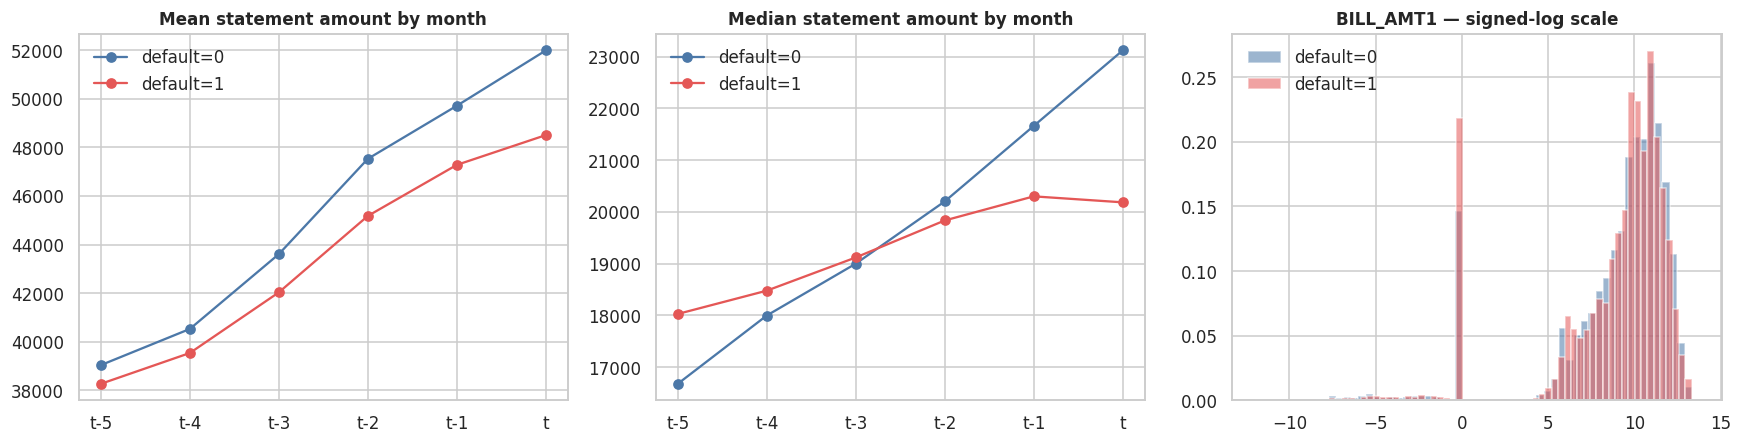

In [89]:
slog = lambda x: np.sign(x) * np.log1p(np.abs(x))
mean_b   = pd.DataFrame({MLBL[k]: tw[f"BILL_AMT{k}"].groupby(tw[TW_T]).mean() for k in order})
median_b = pd.DataFrame({MLBL[k]: tw[f"BILL_AMT{k}"].groupby(tw[TW_T]).median() for k in order})

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for cls, col in CLASS_COLORS.items():
    axes[0].plot(mean_b.columns, mean_b.loc[cls], marker="o", color=col, label=f"default={cls}")
    axes[1].plot(median_b.columns, median_b.loc[cls], marker="o", color=col, label=f"default={cls}")
axes[0].set_title("Mean statement amount by month"); axes[1].set_title("Median statement amount by month")
for ax in axes[:2]: ax.legend(frameon=False)
for cls, col in CLASS_COLORS.items():
    axes[2].hist(slog(tw.loc[tw[TW_T] == cls, "BILL_AMT1"]), bins=60, density=True, alpha=.55, color=col, label=f"default={cls}")
axes[2].set_title("BILL_AMT1 — signed-log scale"); axes[2].legend(frameon=False)
plt.show()

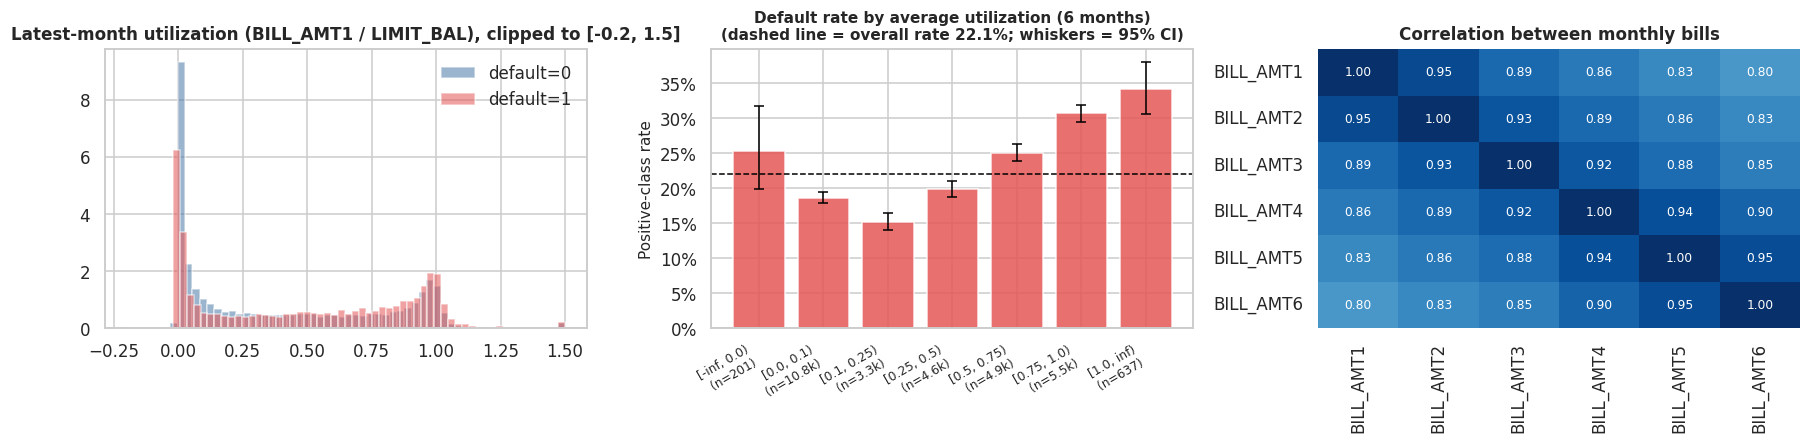

Mean off-diagonal correlation between the six BILL_AMT columns: 0.89


In [90]:
tw["util_now"] = tw["BILL_AMT1"] / tw["LIMIT_BAL"]
tw["util_avg"] = tw[TW_BILL].mean(axis=1) / tw["LIMIT_BAL"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for cls, col in CLASS_COLORS.items():
    axes[0].hist(tw.loc[tw[TW_T] == cls, "util_now"].clip(-.2, 1.5), bins=60, density=True, alpha=.55, color=col, label=f"default={cls}")
axes[0].set_title("Latest-month utilization (BILL_AMT1 / LIMIT_BAL), clipped to [-0.2, 1.5]"); axes[0].legend(frameon=False)
plot_rate(rate_table(tw, "util_avg", TW_T, bins=[-np.inf, 0, .1, .25, .5, .75, 1, np.inf]), axes[1], "Default rate by average utilization (6 months)", base=TW_BASE, rotate=30)
bc = tw[TW_BILL].corr()
sns.heatmap(bc, annot=True, fmt=".2f", cmap="Blues", vmin=.5, vmax=1, ax=axes[2], cbar=False, annot_kws={"size": 8})
axes[2].set_title("Correlation between monthly bills")
plt.show()
print(f"Mean off-diagonal correlation between the six BILL_AMT columns: {bc.values[~np.eye(6, dtype=bool)].mean():.2f}")

**Reading the output.** Statement amounts on their own are weak predictors (defaulters do not have systematically bigger bills), but **relative to the limit** they become informative. The six bills are extremely correlated with each other (a customer's balance persists month to month) → severe multicollinearity if all six are used raw. **ML implication:** replace the six raw bills with `avg_bill`, `bill_trend`, `bill_volatility`, and utilization ratios; cap negative / extreme values.

### [UCI] 2.7 Payment amounts and payment behaviour relative to the bill

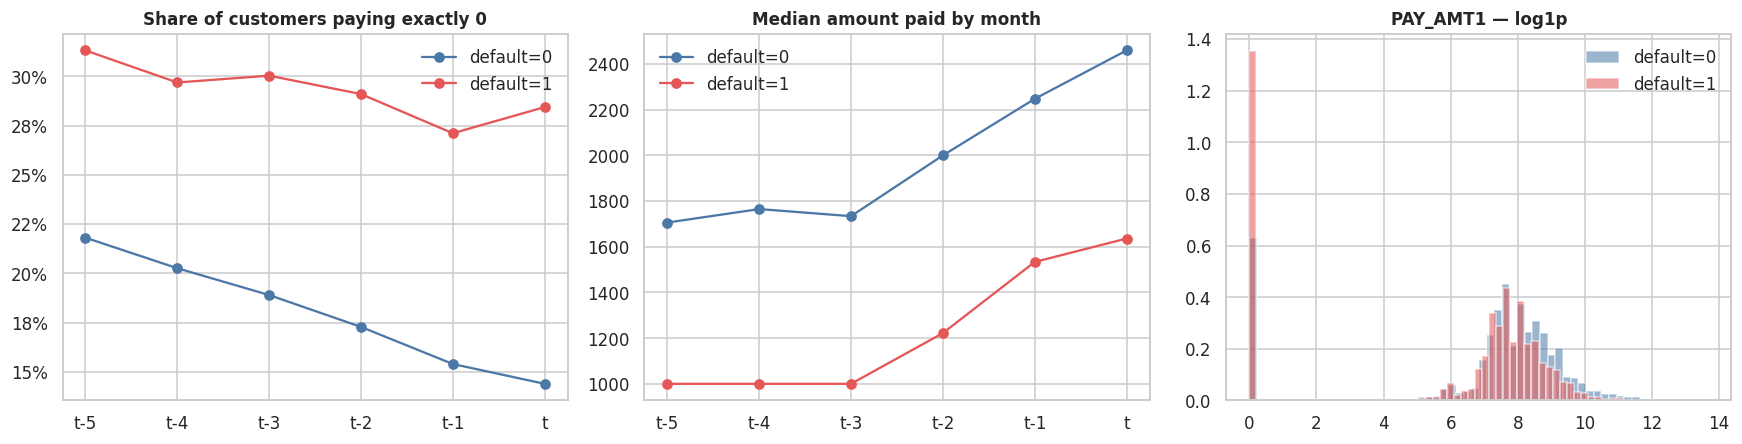

In [91]:
zero_share = pd.DataFrame({MLBL[k]: (tw[f"PAY_AMT{k}"] == 0).groupby(tw[TW_T]).mean() for k in order})
med_pay    = pd.DataFrame({MLBL[k]: tw[f"PAY_AMT{k}"].groupby(tw[TW_T]).median() for k in order})
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for cls, col in CLASS_COLORS.items():
    axes[0].plot(zero_share.columns, zero_share.loc[cls], marker="o", color=col, label=f"default={cls}")
    axes[1].plot(med_pay.columns, med_pay.loc[cls], marker="o", color=col, label=f"default={cls}")
    axes[2].hist(np.log1p(tw.loc[tw[TW_T] == cls, "PAY_AMT1"]), bins=60, density=True, alpha=.55, color=col, label=f"default={cls}")
axes[0].set_title("Share of customers paying exactly 0"); axes[0].yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
axes[1].set_title("Median amount paid by month"); axes[2].set_title("PAY_AMT1 — log1p")
for ax in axes: ax.legend(frameon=False)
plt.show()

**Payment-to-bill ratio:** amount paid in month k / statement of the previous month (`BILL_AMT(k+1)`), clipped to [0, 1].

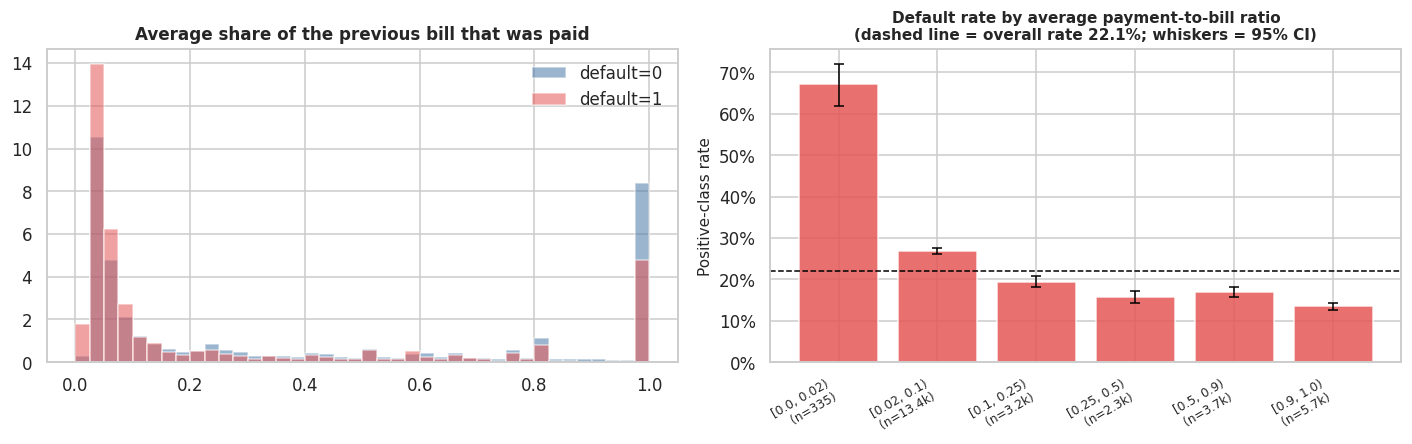

Customers with no valid ratio (never had a positive bill): 4.7%


In [92]:
ratio = {}
for k in range(1, 6):
    b = tw[f"BILL_AMT{k + 1}"]
    ratio[k] = (tw[f"PAY_AMT{k}"] / b.where(b > 0)).clip(0, 1)
R = pd.DataFrame(ratio)
tw["pay_ratio_avg"] = R.mean(axis=1)
tw["pay_ratio_latest"] = R[1]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for cls, col in CLASS_COLORS.items():
    axes[0].hist(tw.loc[tw[TW_T] == cls, "pay_ratio_avg"].dropna(), bins=40, density=True, alpha=.55, color=col, label=f"default={cls}")
axes[0].set_title("Average share of the previous bill that was paid"); axes[0].legend(frameon=False)
plot_rate(rate_table(tw, "pay_ratio_avg", TW_T, bins=[0, .02, .1, .25, .5, .9, 1.0001]), axes[1], "Default rate by average payment-to-bill ratio", base=TW_BASE, rotate=30)
plt.show()
print(f"Customers with no valid ratio (never had a positive bill): {tw['pay_ratio_avg'].isna().mean():.1%}")

**Reading the output.** Paying a **small fraction of the bill** (minimum-payment behaviour) is expected to be much riskier than paying in full, even when the absolute amount looks large. **ML implication:** ratios (`pay_ratio_*`) carry information that raw `PAY_AMT*` and `BILL_AMT*` hide — engineer them; guard against division by zero when the bill is ≤ 0.

### [UCI] 2.8 Candidate engineered features: do they beat the raw columns?
The features are built by `client_level_features(...)` (defined in the setup section). **Section 3 reuses the exact same function**, so the features tested here are the ones that end up in the final table.

In [93]:
fe = client_level_features(tw, TW_PAY)
tw_fe = pd.concat([tw, fe], axis=1)
print("Engineered features:", fe.shape[1])
display(fe.describe().T[["mean", "std", "min", "50%", "max"]])

Engineered features: 26


,mean,std,min,50%,max
n_late_months,0.8342,1.5543,0.0000,0.0000,6.0000
max_delay,0.6822,1.0735,0.0000,0.0000,8.0000
mean_delay,0.2813,0.6016,0.0000,0.0000,6.0000
delay_trend,0.0283,0.1702,-1.5429,0.0000,1.1429
recent_vs_hist_delay,0.0913,0.5744,-5.3333,0.0000,3.3333
consecutive_late_to_now,0.6184,1.4676,0.0000,0.0000,6.0000
n_revolving_months,3.1973,2.5146,0.0000,4.0000,6.0000
n_no_consumption_months,0.8138,1.7936,0.0000,0.0000,6.0000
avg_bill,"44,976.9452","63,260.7219","-56,043.1667","21,051.8333","877,313.8333"
max_bill,"60,572.4369","78,404.8140","-6,029.0000","31,208.5000","1,664,089.0000"


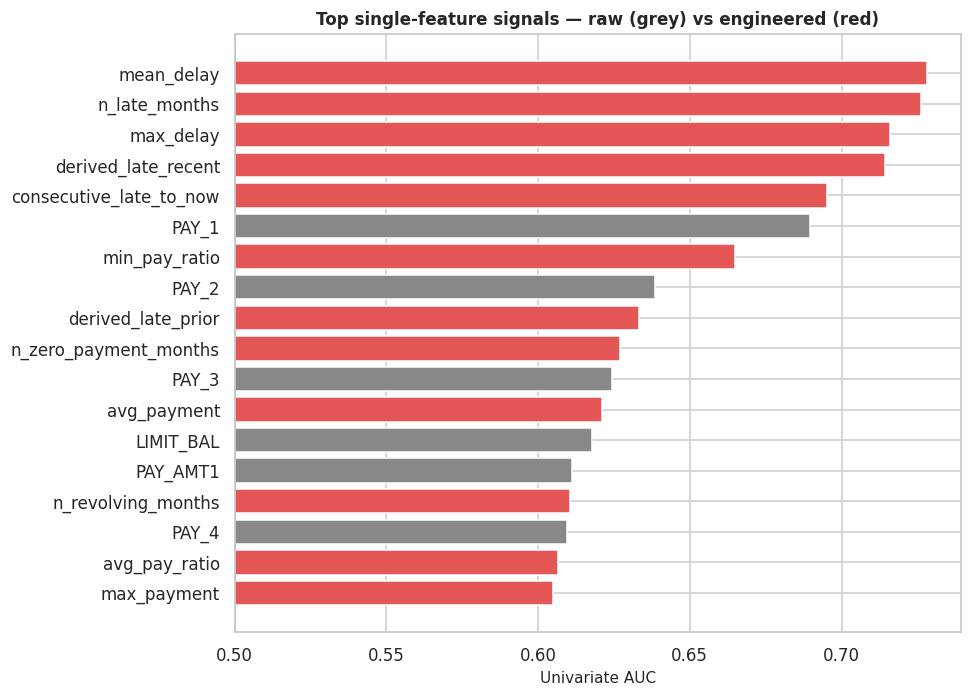

,AUC (direction-free),direction,Cliff's delta,mutual info,median | y=0,median | y=1,Mann-Whitney p,type
feature,,,,,,,,
mean_delay,0.7281,higher = riskier,0.4562,0.0751,0.0000,0.3333,0.0000,engineered
n_late_months,0.7261,higher = riskier,0.4522,0.0766,0.0000,1.0000,0.0000,engineered
max_delay,0.7158,higher = riskier,0.4316,0.0686,0.0000,2.0000,0.0000,engineered
derived_late_recent,0.7145,higher = riskier,0.4289,0.0711,0.0000,1.0000,0.0000,engineered
consecutive_late_to_now,0.6953,higher = riskier,0.3906,0.0671,0.0000,1.0000,0.0000,engineered
PAY_1,0.6897,higher = riskier,0.3794,0.0740,0.0000,1.0000,0.0000,raw
min_pay_ratio,0.6650,higher = safer,-0.3300,0.0431,0.0363,0.0151,0.0000,engineered
PAY_2,0.6386,higher = riskier,0.2771,0.0498,0.0000,0.0000,0.0000,raw
derived_late_prior,0.6333,higher = riskier,0.2667,0.0388,0.0000,0.0000,0.0000,engineered


In [94]:
raw_feats = ["LIMIT_BAL", "AGE"] + TW_PAY + TW_BILL + TW_PAMT
sig_raw = signal_table(tw_fe, raw_feats, TW_T);           sig_raw["type"] = "raw"
sig_eng = signal_table(tw_fe, list(fe.columns), TW_T);    sig_eng["type"] = "engineered"
tw_signal = pd.concat([sig_raw, sig_eng]).sort_values("AUC (direction-free)", ascending=False)

top = tw_signal.head(18).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(top.index, top["AUC (direction-free)"] - .5, left=.5, color=[C1 if t == "engineered" else "#888888" for t in top["type"]])
ax.axvline(.5, color="black", lw=1)
ax.set_xlabel("Univariate AUC"); ax.set_title("Top single-feature signals — raw (grey) vs engineered (red)")
plt.show()
display(tw_signal.head(15).style.format(precision=4).background_gradient(subset=["AUC (direction-free)"], cmap="Reds"))

#### [UCI] Trajectory archetypes — improving, stable or deteriorating?
Turning the payment-status *path* into a simple label operationalises the "risk is improving / stable / deteriorating" idea of monthly monitoring.

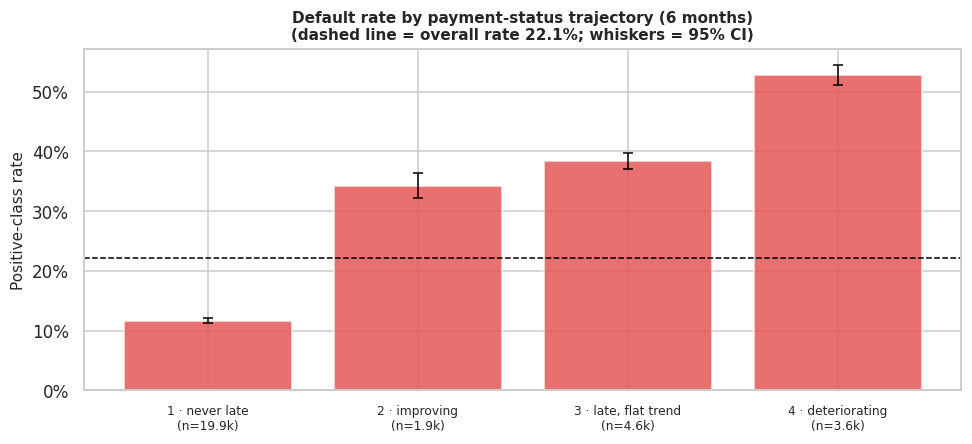

,n,positives,rate,ci_lo,ci_hi,lift
g,,,,,,
1 · never late,19931,2334,0.1171,0.1127,0.1216,0.5294
2 · improving,1894,649,0.3427,0.3216,0.3643,1.5491
"3 · late, flat trend",4605,1769,0.3841,0.3702,0.3983,1.7367
4 · deteriorating,3570,1884,0.5277,0.5113,0.5441,2.3858


In [95]:
tw_fe["trajectory"] = trajectory_label(tw_fe)
tr_rate = rate_table(tw_fe, "trajectory", TW_T)
fig, ax = plt.subplots(figsize=(9, 4.2))
plot_rate(tr_rate, ax, "Default rate by payment-status trajectory (6 months)", base=TW_BASE)
plt.show()
display(tr_rate)

**ML implication.** If engineered sequence features (late-month counts, trend, consecutive lateness, payment ratios) reach or exceed the strongest raw column (`PAY_1`) in the chart above, that is direct evidence for building the monthly-monitoring model on **history-aware features** rather than on the latest snapshot. The trajectory table also gives an interpretable *traffic-light* segmentation (improving / stable / deteriorating) that can be shown to end users.

### [UCI] 2.9 Correlation and redundancy

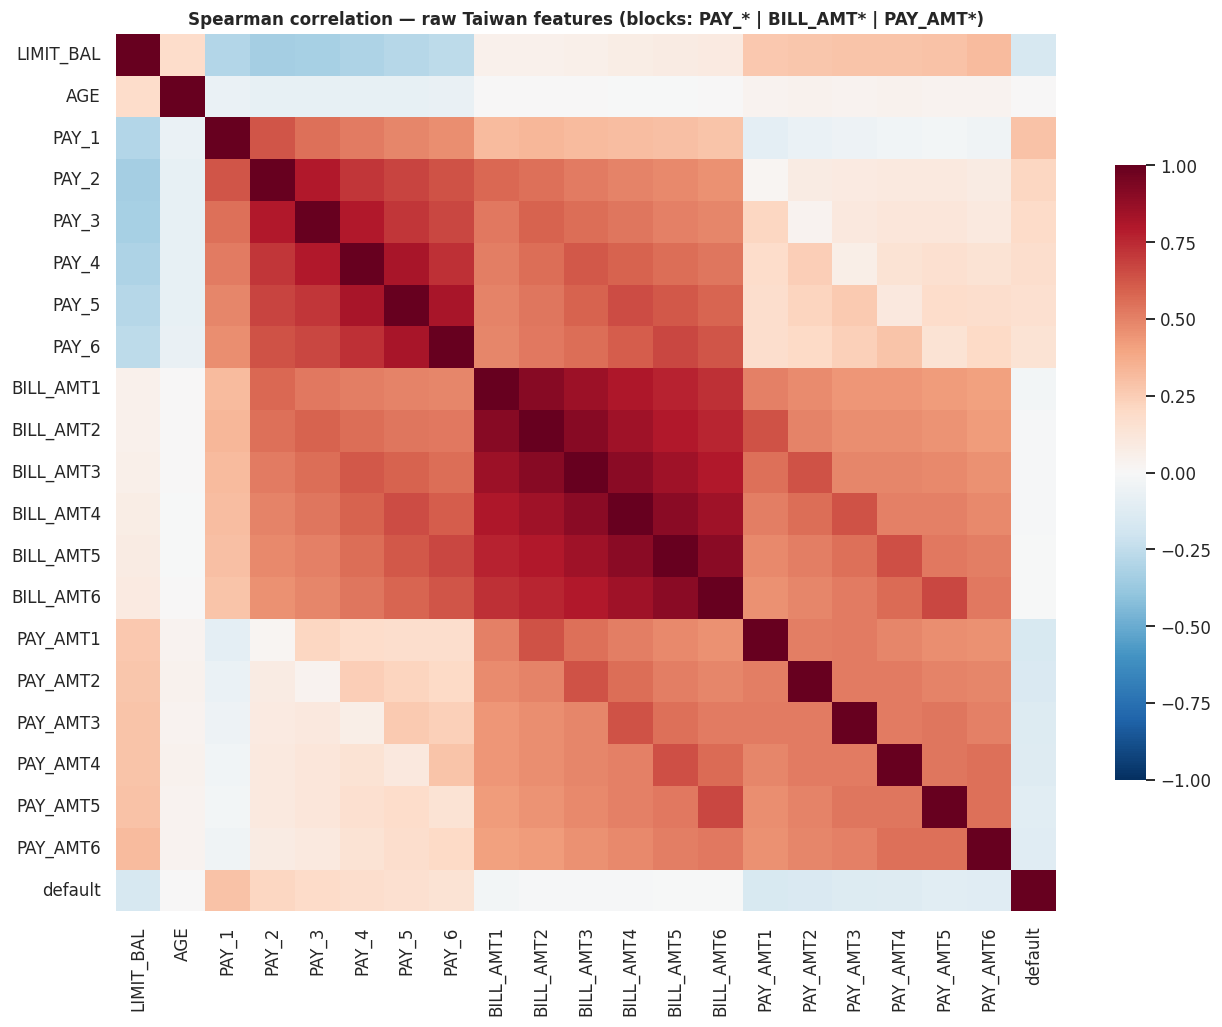

,mean pairwise Spearman inside block
PAY_1..6,0.6686
BILL_AMT1..6,0.8409
PAY_AMT1..6,0.5100


In [96]:
num_cols = ["LIMIT_BAL", "AGE"] + TW_PAY + TW_BILL + TW_PAMT + [TW_T]
cm = tw[num_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(12, 9.5))
sns.heatmap(cm, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"shrink": .7},
            xticklabels=True, yticklabels=True)
ax.set_title("Spearman correlation — raw Taiwan features (blocks: PAY_* | BILL_AMT* | PAY_AMT*)")
plt.show()

def block_mean(cols):
    m = tw[cols].corr(method="spearman").values
    return m[~np.eye(len(cols), dtype=bool)].mean()
display(pd.DataFrame({"mean pairwise Spearman inside block": {"PAY_1..6": block_mean(TW_PAY), "BILL_AMT1..6": block_mean(TW_BILL), "PAY_AMT1..6": block_mean(TW_PAMT)}}))

In [97]:
v_raw = vif_table(tw[TW_BILL + TW_PAMT + ["LIMIT_BAL", "AGE"]].clip(upper=tw[TW_BILL + TW_PAMT + ["LIMIT_BAL", "AGE"]].quantile(.999), axis=1))
eng_small = ["n_late_months", "max_delay", "delay_trend", "avg_utilization", "bill_volatility_over_limit", "avg_pay_ratio", "n_zero_payment_months", "payment_trend_over_limit"]
v_eng = vif_table(tw_fe[["LIMIT_BAL", "AGE"] + eng_small].fillna(tw_fe[["LIMIT_BAL", "AGE"] + eng_small].median()))
print("VIF — raw amount columns (expect BILL_AMT* to dominate):"); display(v_raw.head(8))
print("VIF — compact engineered set:"); display(v_eng)

VIF — raw amount columns (expect BILL_AMT* to dominate):


,VIF
BILL_AMT2,26.9742
BILL_AMT5,26.0736
BILL_AMT3,23.7201
BILL_AMT4,21.9422
BILL_AMT6,15.2631
BILL_AMT1,14.0828
PAY_AMT2,1.9204
PAY_AMT5,1.7186


VIF — compact engineered set:


,VIF
n_late_months,3.2736
max_delay,3.2589
avg_utilization,2.6121
avg_pay_ratio,1.8596
n_zero_payment_months,1.4070
LIMIT_BAL,1.3076
bill_volatility_over_limit,1.2890
delay_trend,1.0427
payment_trend_over_limit,1.0374
AGE,1.0247


**ML implication.** The `BILL_AMT*` block is close to collinear (very high VIF); `PAY_*` columns are also strongly inter-correlated (persistence). For **logistic regression** use the compact engineered set (low VIF) or regularisation (L1/L2); for **tree ensembles** collinearity does not hurt prediction, but it dilutes feature-importance rankings — inspect with permutation importance / SHAP grouped by feature family.

### [UCI] 2.10 Scorecard

In [98]:
best_raw = tw_signal[tw_signal["type"] == "raw"].iloc[0]
best_eng = tw_signal[tw_signal["type"] == "engineered"].iloc[0]
tw_scorecard = pd.Series({
    "Rows": f"{len(tw):,}",
    "Positive rate": f"{TW_BASE:.2%}",
    "Missing cells": f"{int(tw_raw.isna().sum().sum())}",
    "Undocumented EDUCATION codes (0/5/6)": f"{(~tw['EDUCATION'].isin([1, 2, 3, 4])).mean():.2%}",
    "Undocumented MARRIAGE code (0)": f"{(~tw['MARRIAGE'].isin([1, 2, 3])).mean():.2%}",
    "Customers with any negative bill": f"{(tw[TW_BILL] < 0).any(axis=1).mean():.1%}",
    "Customers late (PAY ≥ 1) in at least one month": f"{(tw[TW_PAY] >= 1).any(axis=1).mean():.1%}",
    "Best raw feature (AUC)": f"{best_raw.name} ({best_raw['AUC (direction-free)']:.3f})",
    "Best engineered feature (AUC)": f"{best_eng.name} ({best_eng['AUC (direction-free)']:.3f})",
    "Mean corr. inside BILL_AMT block": f"{block_mean(TW_BILL):.2f}",
}, name="Taiwan scorecard")
display(tw_scorecard.to_frame())

,Taiwan scorecard
Rows,"30,000"
Positive rate,22.12%
Missing cells,0
Undocumented EDUCATION codes (0/5/6),1.15%
Undocumented MARRIAGE code (0),0.18%
Customers with any negative bill,6.4%
Customers late (PAY ≥ 1) in at least one month,33.6%
Best raw feature (AUC),PAY_1 (0.690)
Best engineered feature (AUC),mean_delay (0.728)
Mean corr. inside BILL_AMT block,0.84


### [UCI] Taiwan — Finding → Decision (summary)
*Expected patterns based on the documented characteristics of this dataset — confirm each one against the numbers and the scorecard above.*

| # | EDA finding | Modelling decision |
|---|---|---|
| 1 | Positive class ≈ 22 % | Stratified CV · PR-AUC / KS / recall-at-precision · class weights |
| 2 | No missing values, but **undocumented codes** (`EDUCATION` 0/5/6, `MARRIAGE` 0, `PAY` 0/−2) | Map to "other/unknown" (decide from default rates), keep as a category — do not drop |
| 3 | `PAY_*` = status, `PAY_AMT*` = amount (different semantics) | Never mix; treat −2/−1/0 vs ≥ 1 explicitly |
| 4 | `PAY_1` and recent lateness dominate the signal; delay curves diverge before default | Monitoring model on recent + trend features |
| 5 | Late customers stay late (strong persistence) | Sequence features: `n_late_months`, `max_delay`, `consecutive_late_to_now`, `delay_trend` |
| 6 | `BILL_AMT1–6` almost collinear; amounts heavily skewed | Replace by average / trend / volatility / utilization; `log1p`, cap |
| 7 | Payment *ratio* (paid ÷ previous bill) is informative beyond raw amounts | Engineer `avg_pay_ratio`, `n_low_pay_months`, `n_zero_payment_months` |
| 8 | Demographics carry small effect sizes | Consider excluding `SEX`, `MARRIAGE`, `AGE` (regulatory / fairness); audit if kept |
| 9 | Single label defined at horizon *t+1* | Use all six months for that label; use proxy targets (or new labelled data) to backtest earlier prediction points; enforce `as_of_columns` |

---
## 3) Feature engineering
Source: `target_feature_engineering.ipynb` (Taiwan part). Starts from the **cleaned wide table** (`clean`), not from the EDA working copy, so the EDA-only helper columns (`age_bin`, `util_now`, ...) never reach the final table.

The wide table (one row per client) is reshaped to **long format: one row per client-month** (6 rows per client), with harmonized project columns. Each column is marked as:
- **REAL**: taken as-is from the dataset
- **PROXY**: estimated, flagged with an `_is_proxy` column
- **MISSING**: not available in this dataset, left as NaN

Client-level features come from `client_level_features(...)`, the same function whose features were tested with univariate AUC in section 2.8.

In [99]:
def _merge_codes(s, undocumented):
    # undocumented codes -> "other"; documented codes -> their number as text (so the column is uniformly str)
    return s.map(lambda v: np.nan if pd.isna(v) else ("other" if v in undocumented else str(int(v))))


def build_taiwan_features(df_clean, target_col, keep_demographics=False):
    df = df_clean.copy()

    # -- PAY_1..PAY_6 -> delay_status_1..delay_status_6 (k = 1 is the latest month) --
    df = df.rename(columns={f"PAY_{k}": f"delay_status_{k}" for k in range(1, 7)})
    delay_cols = [f"delay_status_{k}" for k in range(1, 7)]

    # -- undocumented category codes -> "other" ----------------------------------------
    df["EDUCATION"] = _merge_codes(df["EDUCATION"], {0, 5, 6})
    df["MARRIAGE"] = _merge_codes(df["MARRIAGE"], {0})

    id_vars = ["ID", "LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE"]

    # -- monthly (long) table: real, per-month values ------------------------------------
    rows = []
    for suffix in range(1, 7):
        chunk = df[id_vars].copy()
        chunk["month"] = 7 - suffix            # REAL: 1 = Apr (oldest) ... 6 = Sep (latest)
        chunk["_suffix"] = suffix
        chunk["_delay_raw"] = df[f"delay_status_{suffix}"]
        chunk["_bill_amt"] = df[f"BILL_AMT{suffix}"]
        chunk["_pay_amt"] = df[f"PAY_AMT{suffix}"]
        chunk["target"] = df[target_col]
        rows.append(chunk)
    long_df = pd.concat(rows, ignore_index=True)
    long_df = long_df.sort_values(["ID", "_suffix"]).reset_index(drop=True)

    # prior cycle's bill (suffix k+1), needed for the spend calculation
    long_df["_prior_bill"] = long_df.groupby("ID")["_bill_amt"].shift(-1)

    out = pd.DataFrame(index=long_df.index)
    out["ID"] = long_df["ID"]
    out["month"] = long_df["month"]

    # income: PROXY = credit limit (banks size LIMIT_BAL off reported income; it is NOT a reported income figure)
    out["income"] = long_df["LIMIT_BAL"]
    out["income_is_proxy"] = 1

    # debt: REAL = outstanding statement balance for that month
    out["debt"] = long_df["_bill_amt"]

    # monthly_debt_payment: REAL = amount actually paid that month
    out["monthly_debt_payment"] = long_df["_pay_amt"]

    # expenses: PROXY = estimated card spend = bill_this_month - bill_prior_month + payment_made
    # (undefined for the oldest month, month = 1: there is no earlier bill to compare to)
    out["expenses"] = long_df["_bill_amt"] - long_df["_prior_bill"] + long_df["_pay_amt"]
    out["expenses_is_proxy"] = 1

    # savings: PROXY = net cash flow that month (paid in minus estimated spend)
    out["savings"] = out["monthly_debt_payment"] - out["expenses"]
    out["savings_is_proxy"] = 1

    out["rent"] = np.nan          # MISSING: not present in Taiwan
    out["dependents"] = np.nan    # MISSING: not present in Taiwan

    # late_payments: REAL = 1 if that month's repayment status shows a delay (<= 0 not delayed, >= 1 delayed)
    out["late_payments"] = (long_df["_delay_raw"] >= 1).astype(int)

    # -- client-level features (same function as the EDA), repeated on each of the client's 6 rows --------
    assert df["ID"].is_unique, "ID must be unique (one wide row per client)"
    client_fe = client_level_features(df, delay_cols)
    client_fe["trajectory"] = trajectory_label(client_fe)
    # income_stability: PROXY = 1 / (1 + bill_volatility_over_limit)  (spending-behaviour stability, not verified income stability)
    client_fe["income_stability"] = 1 / (1 + client_fe["bill_volatility_over_limit"])
    client_fe["ID"] = df["ID"].values

    out = out.merge(client_fe, on="ID", how="left")
    out["income_stability_is_proxy"] = 1

    if keep_demographics:
        demo = long_df[["LIMIT_BAL", "AGE", "SEX", "EDUCATION", "MARRIAGE"]].reset_index(drop=True)
        out = pd.concat([out, demo], axis=1)

    out["target"] = long_df["target"].values
    out["source_dataset"] = "taiwan_monthly"
    return out.reset_index(drop=True)

In [100]:
taiwan = build_taiwan_features(clean, TARGET_RAW, keep_demographics=KEEP_DEMOGRAPHICS)

print("Taiwan long table shape:", taiwan.shape)
display(taiwan.head(8))

Taiwan long table shape: (180000, 44)


,ID,month,income,income_is_proxy,debt,monthly_debt_payment,expenses,expenses_is_proxy,savings,savings_is_proxy,rent,dependents,late_payments,n_late_months,max_delay,mean_delay,delay_trend,recent_vs_hist_delay,consecutive_late_to_now,n_revolving_months,n_no_consumption_months,avg_bill,max_bill,bill_trend_over_limit,bill_volatility_over_limit,avg_utilization,latest_utilization,avg_payment,max_payment,payment_trend_over_limit,n_zero_payment_months,avg_pay_ratio,min_pay_ratio,latest_pay_ratio,n_low_pay_months,cash_gap_latest,derived_late_recent,derived_late_prior,derived_late_trend,trajectory,income_stability,income_stability_is_proxy,target,source_dataset
0,1,6,20000,1,3913,0,811.0000,1,-811.0000,1,NaN,NaN,1,2,2.0000,0.6667,0.4571,1.3333,2.0000,0,2,"1,284.0000","3,913.0000",0.0422,0.0804,0.0642,0.1956,114.8333,689.0000,0.0030,5,0.5000,0.0000,0.0000,1,0.1551,2,0,2,4 · deteriorating,0.9256,1,1,taiwan_monthly
1,1,5,20000,1,3102,689,"3,102.0000",1,"-2,413.0000",1,NaN,NaN,1,2,2.0000,0.6667,0.4571,1.3333,2.0000,0,2,"1,284.0000","3,913.0000",0.0422,0.0804,0.0642,0.1956,114.8333,689.0000,0.0030,5,0.5000,0.0000,0.0000,1,0.1551,2,0,2,4 · deteriorating,0.9256,1,1,taiwan_monthly
2,1,4,20000,1,689,0,689.0000,1,-689.0000,1,NaN,NaN,0,2,2.0000,0.6667,0.4571,1.3333,2.0000,0,2,"1,284.0000","3,913.0000",0.0422,0.0804,0.0642,0.1956,114.8333,689.0000,0.0030,5,0.5000,0.0000,0.0000,1,0.1551,2,0,2,4 · deteriorating,0.9256,1,1,taiwan_monthly
3,1,3,20000,1,0,0,0.0000,1,0.0000,1,NaN,NaN,0,2,2.0000,0.6667,0.4571,1.3333,2.0000,0,2,"1,284.0000","3,913.0000",0.0422,0.0804,0.0642,0.1956,114.8333,689.0000,0.0030,5,0.5000,0.0000,0.0000,1,0.1551,2,0,2,4 · deteriorating,0.9256,1,1,taiwan_monthly
4,1,2,20000,1,0,0,0.0000,1,0.0000,1,NaN,NaN,0,2,2.0000,0.6667,0.4571,1.3333,2.0000,0,2,"1,284.0000","3,913.0000",0.0422,0.0804,0.0642,0.1956,114.8333,689.0000,0.0030,5,0.5000,0.0000,0.0000,1,0.1551,2,0,2,4 · deteriorating,0.9256,1,1,taiwan_monthly
5,1,1,20000,1,0,0,NaN,1,NaN,1,NaN,NaN,0,2,2.0000,0.6667,0.4571,1.3333,2.0000,0,2,"1,284.0000","3,913.0000",0.0422,0.0804,0.0642,0.1956,114.8333,689.0000,0.0030,5,0.5000,0.0000,0.0000,1,0.1551,2,0,2,4 · deteriorating,0.9256,1,1,taiwan_monthly
6,2,6,120000,1,2682,0,957.0000,1,-957.0000,1,NaN,NaN,0,2,2.0000,0.6667,-0.1143,0.0000,0.0000,3,0,"2,846.1667","3,455.0000",-0.0021,0.0049,0.0237,0.0223,833.3333,"2,000.0000",-0.0017,2,0.1936,0.0000,0.0000,2,0.0144,1,1,0,"3 · late, flat trend",0.9952,1,1,taiwan_monthly
7,2,5,120000,1,1725,1000,43.0000,1,957.0000,1,NaN,NaN,1,2,2.0000,0.6667,-0.1143,0.0000,0.0000,3,0,"2,846.1667","3,455.0000",-0.0021,0.0049,0.0237,0.0223,833.3333,"2,000.0000",-0.0017,2,0.1936,0.0000,0.0000,2,0.0144,1,1,0,"3 · late, flat trend",0.9952,1,1,taiwan_monthly


### [UCI] 3.1 Sanity checks on the engineered table

In [101]:
n_clients = clean["ID"].nunique()
assert len(taiwan) == 6 * n_clients,                        "expected exactly 6 rows per client"
assert (taiwan.groupby("ID").size() == 6).all(),            "every client must have 6 monthly rows"
assert (taiwan.groupby("ID")["target"].nunique() == 1).all(), "target must be constant within a client"
assert set(taiwan["month"].unique()) == {1, 2, 3, 4, 5, 6}, "month must be 1..6"
assert taiwan.loc[taiwan["month"] != 1, ["expenses", "savings"]].notna().all().all(), "expenses/savings may be NaN only for month 1"
assert taiwan["target"].isin([0, 1]).all()

print(f"OK — {n_clients:,} clients x 6 months = {len(taiwan):,} rows")
print(f"Positive rate: {taiwan.groupby('ID')['target'].first().mean():.2%} (client level)")

na = taiwan.isna().sum()
print("\nColumns with missing values (expected: rent, dependents = MISSING by design; expenses/savings = month 1 only):")
display(na[na > 0].to_frame("missing"))

OK — 30,000 clients x 6 months = 180,000 rows
Positive rate: 22.12% (client level)

Columns with missing values (expected: rent, dependents = MISSING by design; expenses/savings = month 1 only):


,missing
expenses,30000
savings,30000
rent,180000
dependents,180000
avg_pay_ratio,8436
min_pay_ratio,8436
latest_pay_ratio,19050


### [UCI] 3.2 Column-by-column mapping report (Taiwan)

In [102]:
def _section(name, real, proxy, missing):
    lines = [f"-- {name} --"]
    lines.append(f"  REAL    : {', '.join(real) if real else '(none)'}")
    lines.append(f"  PROXY   : {', '.join(proxy) if proxy else '(none)'}")
    lines.append(f"  MISSING : {', '.join(missing) if missing else '(none)'}")
    return "\n".join(lines)

print(_section(
    "Taiwan monthly",
    real=["month", "debt", "monthly_debt_payment", "late_payments"],
    proxy=["income", "expenses", "savings", "income_stability"],
    missing=["rent", "dependents"],
))

-- Taiwan monthly --
  REAL    : month, debt, monthly_debt_payment, late_payments
  PROXY   : income, expenses, savings, income_stability
  MISSING : rent, dependents


---
## 4) Train / test split
After reshaping, each client has **6 rows that share the same target**. Splitting by row would put some of a client's months in train and others in test (leakage), so the split is done **by client `ID` first** (stratified on the client's target), then applied to all of that client's rows.

All engineered features are computed row-wise from each client's own data (no statistics are fitted on the whole dataset), so building them before the split does not leak test information. Any step that *does* learn from data (scaling, imputing with a median, target encoding, SMOTE) should be fitted on `taiwan_train` only.

In [103]:
taiwan_id_target = taiwan.groupby("ID")["target"].first()
train_ids, test_ids = train_test_split(
    taiwan_id_target.index,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=taiwan_id_target.values,
)
taiwan_train = taiwan[taiwan["ID"].isin(train_ids)].reset_index(drop=True)
taiwan_test = taiwan[taiwan["ID"].isin(test_ids)].reset_index(drop=True)

# --- checks
assert set(train_ids).isdisjoint(set(test_ids)), "a client appears in both train and test"
assert len(taiwan_train) + len(taiwan_test) == len(taiwan)
assert (taiwan_train.groupby("ID").size() == 6).all() and (taiwan_test.groupby("ID").size() == 6).all()

print("Taiwan  train:", taiwan_train.shape, " test:", taiwan_test.shape)
print("Taiwan  train clients:", taiwan_train["ID"].nunique(), "| test clients:", taiwan_test["ID"].nunique())
print("Taiwan  train target rate:", round(taiwan_train["target"].mean(), 4),
      "| test target rate:", round(taiwan_test["target"].mean(), 4))

Taiwan  train: (144000, 44)  test: (36000, 44)
Taiwan  train clients: 24000 | test clients: 6000
Taiwan  train target rate: 0.2212 | test target rate: 0.2212


---
## 5) Save the results

In [104]:
_OUT_FILES = {
    "taiwan_target_features.csv": taiwan,
    "taiwan_train.csv": taiwan_train,
    "taiwan_test.csv": taiwan_test,
}
for _name, _frame in _OUT_FILES.items():
    _frame.to_csv(os.path.join(OUT_DIR, _name), index=False)
print("Saved:", ", ".join(["default_of_credit_card_clients_cleaned.csv"] + list(_OUT_FILES)))

try:
    from google.colab import files as _files
    for _f in ["default_of_credit_card_clients_cleaned.csv"] + list(_OUT_FILES):
        _files.download(os.path.join(OUT_DIR, _f))
except ImportError:
    pass

Saved: default_of_credit_card_clients_cleaned.csv, taiwan_target_features.csv, taiwan_train.csv, taiwan_test.csv


---
## 6) UCI Monthly Tracking — 30-day and 90-day models (plan points 1 & 2)
Built **step by step**. This block is **Step 1: preprocessing -> rolling as-of panel**.

**Why a new table?** Section 3 computes its client-level features from all 6 months and repeats them on every monthly row, so a row for April "sees" September. A 30/90-day model needs one row = *one client as of one month*, using **only months <= that month**.

Month index: 1 = Apr (oldest) ... 6 = Sep (latest)  (`PAY_6` = Apr, `PAY_1` = Sep). Rolling window **W = 3 months** (from the plan).

| As-of month | Features use | 30-day label looks at | 90-day label would look at |
|---|---|---|---|
| Jun (3) | Apr–Jun | Jul | Jul–Sep ✔ |
| Jul (4) | May–Jul | Aug | Aug–Oct ✔ (Oct = the real `default` label) |
| Aug (5) | Jun–Aug | Sep | Sep–Nov ✗ |
| Sep (6) | Jul–Sep | Oct (the real `default` label) | Oct–Dec ✗ |

So with 6 months of history and a 3-month window: the 30-day model gets **4 windows per client**, the 90-day model gets **2 windows (Jun, Jul)**. For Jul the third future month is Oct, where the real `default` label stands in for the payment status (the same convention already used for the 30-day Sep window). Aug and Sep cannot be used for 90 days (Nov/Dec are not observed). Step 2 builds the targets.

In [105]:
W = 3                                                          # rolling window length in months (from the plan)
MONTH_NAME = {1: "Apr", 2: "May", 3: "Jun", 4: "Jul", 5: "Aug", 6: "Sep"}
STATIC_COLS = ["LIMIT_BAL", "AGE", "SEX", "EDUCATION", "MARRIAGE"]   # EDA finding 8: you may drop SEX / MARRIAGE / AGE here


def _slope(M):
    # least-squares slope per row over equally spaced months (positive = rising toward the as-of month)
    t = np.arange(M.shape[1]) - (M.shape[1] - 1) / 2
    return ((M - M.mean(1, keepdims=True)) * t).sum(1) / (t ** 2).sum()


def _prep(df_clean):
    d = df_clean.copy()
    d["EDUCATION"] = _merge_codes(d["EDUCATION"], {0, 5, 6})     # undocumented codes -> "other"
    d["MARRIAGE"] = _merge_codes(d["MARRIAGE"], {0})
    return d


def asof_features(d, a, w=W):
    # Features for every client AS OF month a (1 = Apr ... 6 = Sep), using ONLY the w months a-w+1 .. a.
    assert w <= a <= 6
    P = d[[f"PAY_{k}" for k in range(6, 0, -1)]].values.astype(float)        # column j = month j+1 (oldest -> latest)
    B = d[[f"BILL_AMT{k}" for k in range(6, 0, -1)]].values.astype(float)
    A = d[[f"PAY_AMT{k}" for k in range(6, 0, -1)]].values.astype(float)
    L = d["LIMIT_BAL"].values.astype(float)
    Pw, Bw, Aw = P[:, a - w:a], B[:, a - w:a], A[:, a - w:a]                  # the window
    Dw = np.clip(Pw, 0, None)                                                 # months of delay (>= 0)

    run = np.zeros(len(d)); alive = np.ones(len(d), bool)
    for j in range(w - 1, -1, -1):                                            # consecutive late months ending at a
        alive &= Pw[:, j] >= 1
        run += alive

    with np.errstate(divide="ignore", invalid="ignore"):                      # payment in month j / bill of month j-1 (never divide by a bill <= 0)
        RR = np.clip(np.where(Bw[:, :-1] > 0, Aw[:, 1:] / Bw[:, :-1], np.nan), 0, 1)

    f = pd.DataFrame({"ID": d["ID"].values, "asof_month": a, "asof_name": MONTH_NAME[a]})
    for c in STATIC_COLS:
        f[c] = d[c].values
    # --- payment status
    f["pay_status_now"]              = Pw[:, -1]                    # raw code as of month a: -2, -1, 0, 1..8
    f["n_late_months"]               = (Pw >= 1).sum(1)
    f["max_delay"]                   = Dw.max(1)
    f["delay_trend"]                 = _slope(Dw)
    f["consecutive_late_to_now"]     = run
    # --- bills (utilization, trend)
    f["latest_utilization"]          = Bw[:, -1] / L
    f["avg_utilization"]             = Bw.mean(1) / L
    f["bill_trend_over_limit"]       = _slope(Bw) / L
    f["bill_volatility_over_limit"]  = Bw.std(1) / L
    # --- repayment behaviour
    f["avg_pay_ratio"]               = np.nanmean(RR, 1)
    f["min_pay_ratio"]               = np.nanmin(RR, 1)
    f["latest_pay_ratio"]            = RR[:, -1]
    f["n_low_pay_months"]            = (RR < .1).sum(1)             # paid < 10 % of the previous bill
    f["n_zero_payment_months"]       = (Aw == 0).sum(1)
    f["cash_gap_latest"]             = (Bw[:, -2] - Aw[:, -1]) / L
    return f


def build_panel(df_clean, w=W):
    d = _prep(df_clean)
    return pd.concat([asof_features(d, a, w) for a in range(w, 7)], ignore_index=True)


def check_no_future_leak(df_clean, w=W, n=2000, seed=0):
    # Scramble every column that belongs to a month AFTER the as-of month; the as-of features must not move.
    rng = np.random.RandomState(seed)
    s = _prep(df_clean).sample(min(n, len(df_clean)), random_state=seed).reset_index(drop=True)
    for a in range(w, 7):
        base = asof_features(s, a, w)
        s2 = s.copy()
        for m in range(a + 1, 7):                                  # months after a
            k = 7 - m
            for col in (f"PAY_{k}", f"BILL_AMT{k}", f"PAY_AMT{k}"):
                s2[col] = rng.permutation(s2[col].values) * 3 + 7
        new = asof_features(s2, a, w)
        num = base.select_dtypes("number").columns
        assert np.allclose(base[num], new[num], equal_nan=True), f"FUTURE LEAK at as-of month {a}"
    print(f"No future leakage: features at as-of month a are unchanged when months > a are scrambled (checked a = {w}..6).")

In [106]:
panel = build_panel(clean)
check_no_future_leak(clean)

# reuse the client-level split from section 4 (same IDs in train/test as before)
panel["split"] = np.where(panel["ID"].isin(train_ids), "train", "test")

assert len(panel) == (7 - W) * clean["ID"].nunique()
assert (panel.groupby("ID").size() == 7 - W).all()
assert panel.groupby("ID")["split"].nunique().max() == 1, "a client must not be in both train and test"

print("Panel shape:", panel.shape, f"= {clean['ID'].nunique():,} clients x {7 - W} as-of months")
display(panel.groupby(["asof_month", "asof_name", "split"]).size().unstack("split"))
display(panel.head(6))
feat_cols = [c for c in panel.columns if c not in ["ID", "asof_month", "asof_name", "split"] + STATIC_COLS]
display(panel[feat_cols].describe().T[["mean", "std", "min", "50%", "max"]])

No future leakage: features at as-of month a are unchanged when months > a are scrambled (checked a = 3..6).
Panel shape: (120000, 24) = 30,000 clients x 4 as-of months


,split,test,train
asof_month,asof_name,,
3,Jun,6000,24000
4,Jul,6000,24000
5,Aug,6000,24000
6,Sep,6000,24000


,ID,asof_month,asof_name,LIMIT_BAL,AGE,SEX,EDUCATION,MARRIAGE,pay_status_now,n_late_months,max_delay,delay_trend,consecutive_late_to_now,latest_utilization,avg_utilization,bill_trend_over_limit,bill_volatility_over_limit,avg_pay_ratio,min_pay_ratio,latest_pay_ratio,n_low_pay_months,n_zero_payment_months,cash_gap_latest,split
0,1,3,Jun,20000,24.0000,2,2,1,-1.0000,0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,NaN,NaN,0,3,0.0000,train
1,2,3,Jun,120000,26.0000,2,2,2,0.0000,1,2.0000,-1.0000,0.0000,0.0273,0.0277,0.0000,0.0007,0.1447,0.0000,0.2894,1,1,0.0205,test
2,3,3,Jun,90000,34.0000,2,2,2,0.0000,0,0.0000,0.0000,0.0000,0.1592,0.1660,-0.0068,0.0055,0.0656,0.0643,0.0669,2,0,0.1550,train
3,4,3,Jun,50000,37.0000,2,2,1,0.0000,0,0.0000,0.0000,0.0000,0.5663,0.5788,-0.0123,0.0101,0.0371,0.0362,0.0380,2,0,0.5572,train
4,5,3,Jun,50000,57.0000,1,2,1,0.0000,0,0.0000,0.0000,0.0000,0.4188,0.3948,0.0181,0.0170,0.2530,0.0360,0.4701,1,0,0.2029,train
5,6,3,Jun,50000,37.0000,1,1,2,0.0000,0,0.0000,0.0000,0.0000,0.3879,0.3936,-0.0063,0.0052,0.0505,0.0499,0.0510,2,0,0.3724,train


,mean,std,min,50%,max
pay_status_now,-0.1343,1.1745,-2.0000,0.0000,8.0000
n_late_months,0.3990,0.8639,0.0000,0.0000,3.0000
max_delay,0.4624,0.9478,0.0000,0.0000,8.0000
delay_trend,0.0286,0.3647,-3.5000,0.0000,1.5000
consecutive_late_to_now,0.3275,0.8375,0.0000,0.0000,3.0000
latest_utilization,0.3966,0.3964,-1.3955,0.2796,10.6886
avg_utilization,0.3738,0.3670,-0.7500,0.2691,6.0757
bill_trend_over_limit,0.0229,0.1074,-5.0458,0.0000,5.3403
bill_volatility_over_limit,0.0509,0.0943,0.0000,0.0157,5.0374
avg_pay_ratio,0.3411,0.4009,0.0000,0.0784,1.0000


### [UCI] Step 2 — Targets (30-day and 90-day)
Decision: the **90-day model uses two as-of windows (Jun and Jul)**; the 30-day model uses all four (Jun–Sep). In the Jul window the third month (Oct) is represented by the real `default` label.

| Target | Definition | Windows |
|---|---|---|
| `target_30` | late next month: `PAY >= 1` in month a+1. For as-of Sep there is no Oct status, so the **real `default` label** is used | Jun, Jul, Aug, Sep |
| `target_90` | late in **any** of the next 3 months: `PAY >= 1` in month a+1, a+2 or a+3 (for Jul: Aug status, Sep status, or `default` in Oct) | Jun, Jul |

`target_90 >= target_30` must hold row by row (the 90-day event contains the 30-day event). `label_source_30` and `label_source_90` record where each label came from, because "late next month" (a payment-status proxy) is not exactly the same event as the dataset's `default` label.

In [107]:
def add_targets(panel, df_clean, target_raw):
    s = df_clean.set_index("ID")
    status = {m: s[f"PAY_{7 - m}"] for m in range(1, 7)}          # repayment status by month index (1 = Apr ... 6 = Sep), indexed by ID
    real = s[target_raw].astype(int)                              # the dataset's own label (= default in Oct)

    p = panel.copy()
    p["target_30"] = np.nan
    p["target_90"] = np.nan
    p["label_source_30"] = ""
    p["label_source_90"] = ""
    for a in sorted(p["asof_month"].unique()):
        m = (p["asof_month"] == a).values
        ids = p.loc[m, "ID"]
        if a <= 5:
            p.loc[m, "target_30"] = (status[a + 1].reindex(ids).values >= 1).astype(float)
            p.loc[m, "label_source_30"] = f"PAY status of {MONTH_NAME[a + 1]}"
        else:
            p.loc[m, "target_30"] = real.reindex(ids).values.astype(float)
            p.loc[m, "label_source_30"] = "real default label (Oct)"
        if a + 3 <= 6:                                            # all three future months must be observed
            fut = np.column_stack([status[a + j].reindex(ids).values for j in (1, 2, 3)])
            p.loc[m, "target_90"] = (fut >= 1).any(axis=1).astype(float)
            p.loc[m, "label_source_90"] = f"PAY status of {MONTH_NAME[a + 1]}-{MONTH_NAME[a + 3]}"
        elif a + 3 == 7:                                          # third month is Oct: use the real default label
            third = real.reindex(ids).values == 1
            fut = np.column_stack([status[a + 1].reindex(ids).values >= 1, status[a + 2].reindex(ids).values >= 1, third])
            p.loc[m, "target_90"] = fut.any(axis=1).astype(float)
            p.loc[m, "label_source_90"] = f"PAY status of {MONTH_NAME[a + 1]}, {MONTH_NAME[a + 2]} + real default label (Oct)"
    return p


panel = add_targets(panel, clean, TARGET_RAW)

# --- checks
both = panel[["target_30", "target_90"]].dropna()
assert (both["target_90"] >= both["target_30"]).all(), "90-day event must contain the 30-day event"
assert panel["target_30"].notna().all()
assert panel["target_90"].notna().sum() == 2 * clean["ID"].nunique(), "target_90 should exist only for the Jun and Jul windows"
assert panel.loc[panel["target_90"].notna(), "asof_name"].isin(["Jun", "Jul"]).all()
TARGET_COLS = ["target_30", "target_90", "label_source_30", "label_source_90"]

# --- what we got
summary = (panel.groupby(["asof_month", "asof_name"])
           .agg(rows=("ID", "size"), pos_rate_30=("target_30", "mean"), pos_rate_90=("target_90", "mean"),
                source_30=("label_source_30", "first"), source_90=("label_source_90", "first")))
display(summary)

by_split = (panel.groupby("split")
            .agg(rows=("ID", "size"), pos_rate_30=("target_30", "mean"), rows_90=("target_90", "count"), pos_rate_90=("target_90", "mean")))
display(by_split)

,,rows,pos_rate_30,pos_rate_90,source_30,source_90
asof_month,asof_name,,,,,
3,Jun,30000,0.1404,0.2813,PAY status of Jul,PAY status of Jul-Sep
4,Jul,30000,0.1479,0.3434,PAY status of Aug,"PAY status of Aug, Sep + real default label (Oct)"
5,Aug,30000,0.2273,NaN,PAY status of Sep,
6,Sep,30000,0.2212,NaN,real default label (Oct),


,rows,pos_rate_30,rows_90,pos_rate_90
split,,,,
test,24000,0.1829,12000,0.3061
train,96000,0.1845,48000,0.3139


In [108]:
# Sanity: does the current payment status already separate the labels? (univariate AUC, train only)
tr = panel[panel["split"] == "train"]
rows = []
for a, g in tr.groupby("asof_name", sort=False):
    rows.append({"window": a, "AUC target_30": roc_auc_score(g["target_30"], g["pay_status_now"]),
                 "AUC target_90": roc_auc_score(g["target_90"], g["pay_status_now"]) if g["target_90"].notna().all() else np.nan})
display(pd.DataFrame(rows).set_index("window"))

panel_30 = panel[panel["target_30"].notna()].reset_index(drop=True)      # 4 windows
panel_90 = panel[panel["target_90"].notna()].reset_index(drop=True)      # Jun and Jul windows
print("panel_30:", panel_30.shape, "| panel_90:", panel_90.shape)

,AUC target_30,AUC target_90
window,,
Jun,0.8192,0.6287
Jul,0.8309,0.6048
Aug,0.6930,NaN
Sep,0.6931,NaN


panel_30: (120000, 28) | panel_90: (60000, 28)


### [UCI] Step 3 — Logistic Regression baseline (30-day)
**What & why**
- **Preprocessing inside a `Pipeline`**: median imputation (+ missing flags), clipping at the 0.5 / 99.5 percentiles, scaling, one-hot for `SEX / EDUCATION / MARRIAGE`. Everything is *fitted on the training folds only*, so nothing leaks from validation.
- **`class_weight="balanced"`**: the positive class is a minority. Predicted probabilities will be inflated; calibration (plan point 4) fixes that later.
- **Validation = `StratifiedGroupKFold` grouped by `ID`**: the same client appears in up to 4 windows, so a plain stratified CV would put one window in train and another in validation (leakage). Test stays untouched until the final evaluation (plan point 5).
- `asof_month` is **not** a feature (the model should not learn calendar effects).

In [109]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import average_precision_score, roc_curve

CAT_COLS = ["SEX", "EDUCATION", "MARRIAGE"]
NUM_COLS = [c for c in STATIC_COLS if c not in CAT_COLS] + feat_cols
assert not any("target" in c or c in ("asof_month", "asof_name", "split", "ID") for c in NUM_COLS + CAT_COLS)


class Winsorizer(BaseEstimator, TransformerMixin):
    def __init__(self, lo=0.005, hi=0.995):
        self.lo, self.hi = lo, hi
    def fit(self, X, y=None):
        self.lo_, self.hi_ = np.quantile(X, self.lo, axis=0), np.quantile(X, self.hi, axis=0)
        return self
    def transform(self, X):
        return np.clip(X, self.lo_, self.hi_)
    def get_feature_names_out(self, input_features=None):
        # needed so ColumnTransformer.get_feature_names_out() works downstream (used by SHAP, section 8+)
        return np.asarray(input_features if input_features is not None else self.feature_names_in_)


def lr_model():
    num = Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                    ("clip", Winsorizer()), ("scale", StandardScaler())])
    pre = ColumnTransformer([("num", num, NUM_COLS), ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS)])
    return Pipeline([("pre", pre), ("lr", LogisticRegression(class_weight="balanced", max_iter=2000))])


def get_xy(p, target):
    X = p[NUM_COLS + CAT_COLS].copy()
    X[CAT_COLS] = X[CAT_COLS].astype(str)
    return X, p[target].astype(int).values, p["ID"].values


def oof_eval(p, target, model_fn, n_splits=5):
    # Out-of-fold predictions on the TRAIN split only, folds grouped by client ID.
    tr = p[p["split"] == "train"].reset_index(drop=True)
    X, y, g = get_xy(tr, target)
    folds = list(StratifiedGroupKFold(n_splits, shuffle=True, random_state=RANDOM_STATE).split(X, y, g))
    for a, b in folds:
        assert set(g[a]).isdisjoint(g[b]), "a client appears in both train and validation folds"
    oof = cross_val_predict(model_fn(), X, y, cv=folds, method="predict_proba")[:, 1]
    fpr, tpr, _ = roc_curve(y, oof)
    metrics = {"ROC-AUC": roc_auc_score(y, oof), "PR-AUC": average_precision_score(y, oof),
               "KS": (tpr - fpr).max(), "positive rate": y.mean(), "rows": len(y)}
    return metrics, oof, tr

In [110]:
m30, oof30, tr30 = oof_eval(panel_30, "target_30", lr_model)
display(pd.Series(m30, name="LogReg | 30-day | 5-fold grouped CV (train only)").to_frame())

per_window = pd.DataFrame({"ROC-AUC": {w: roc_auc_score(g["target_30"], oof30[g.index]) for w, g in tr30.groupby("asof_name", sort=False)}})
display(per_window)

,LogReg | 30-day | 5-fold grouped CV (train only)
ROC-AUC,0.8267
PR-AUC,0.6201
KS,0.5273
positive rate,0.1845
rows,"96,000.0000"


,ROC-AUC
Jun,0.8417
Jul,0.8512
Aug,0.8656
Sep,0.7575


### [UCI] Step 4 — Logistic Regression baseline (90-day)
Same pipeline, same validation, different target. `panel_90` has **two rows per client** (the Jun and Jul windows), so the grouped CV by `ID` matters here too: both rows of a client always stay on the same side of every split.

In [111]:
m90, oof90, tr90 = oof_eval(panel_90, "target_90", lr_model)

cmp_lr = pd.DataFrame({"LogReg 30-day": m30, "LogReg 90-day": m90})
display(cmp_lr)
print("Reading guide: compare PR-AUC against each model's own positive rate (a random model scores ≈ positive rate).")

,LogReg 30-day,LogReg 90-day
ROC-AUC,0.8267,0.7587
PR-AUC,0.6201,0.6510
KS,0.5273,0.3879
positive rate,0.1845,0.3139
rows,"96,000.0000","48,000.0000"


Reading guide: compare PR-AUC against each model's own positive rate (a random model scores ≈ positive rate).


#### [UCI] Step 4b — Diagnostic: why do the windows behave differently?
Two checks, train rows only:
1. **Persistence**: how often a customer who is late now is late next month, per window. If Jun/Jul differ from Aug/Sep, the 30-day label does not mean the same thing in every window.
2. **Single-feature signal per window**: if one feature is strong in only one window, that feature (or that label) needs a closer look.

In [112]:
tr = panel_30[panel_30["split"] == "train"]

rows = {}
for w, g in tr.groupby("asof_name", sort=False):
    late_now = g["pay_status_now"] >= 1
    rows[w] = {"rows": len(g),
               "positive rate": g["target_30"].mean(),
               "P(late next | late now)": g.loc[late_now, "target_30"].mean(),
               "P(late next | not late now)": g.loc[~late_now, "target_30"].mean(),
               "label source": g["label_source_30"].iloc[0]}
display(pd.DataFrame(rows).T)

auc = {}
for w, g in tr.groupby("asof_name", sort=False):
    s = {}
    for c in NUM_COLS:
        x = g[c].fillna(g[c].median())
        if x.nunique() > 1:
            a_ = roc_auc_score(g["target_30"], x)
            s[c] = max(a_, 1 - a_)
    auc[w] = pd.Series(s)
auc_by_window = pd.DataFrame(auc)
auc_by_window["max - min"] = auc_by_window.max(axis=1) - auc_by_window.min(axis=1)
print("Univariate AUC per feature and window (direction-free), top 10 by Aug:")
display(auc_by_window.sort_values("Aug", ascending=False).head(10))
print("Features whose signal differs the most between windows:")
display(auc_by_window.sort_values("max - min", ascending=False).head(6))

,rows,positive rate,P(late next | late now),P(late next | not late now),label source
Jun,24000,0.1400,0.7326,0.0614,PAY status of Jul
Jul,24000,0.1480,0.6932,0.0592,PAY status of Aug
Aug,24000,0.2289,0.8975,0.1128,PAY status of Sep
Sep,24000,0.2212,0.5040,0.1373,real default label (Oct)


Univariate AUC per feature and window (direction-free), top 10 by Aug:


,Jun,Jul,Aug,Sep,max - min
consecutive_late_to_now,0.7925,0.8096,0.7824,0.6968,0.1128
n_late_months,0.8061,0.8195,0.7758,0.7165,0.1030
max_delay,0.7953,0.8069,0.7636,0.7147,0.0922
pay_status_now,0.8192,0.8309,0.6930,0.6931,0.1379
n_zero_payment_months,0.6035,0.6033,0.6706,0.6167,0.0674
min_pay_ratio,0.7026,0.7117,0.6514,0.6401,0.0717
delay_trend,0.6041,0.6173,0.6403,0.5527,0.0876
LIMIT_BAL,0.6851,0.6842,0.6181,0.6234,0.0670
avg_pay_ratio,0.6695,0.6803,0.6177,0.6014,0.0789
latest_pay_ratio,0.6472,0.6591,0.6147,0.5965,0.0626


Features whose signal differs the most between windows:


,Jun,Jul,Aug,Sep,max - min
latest_utilization,0.6653,0.6572,0.5241,0.5547,0.1412
pay_status_now,0.8192,0.8309,0.6930,0.6931,0.1379
avg_utilization,0.6743,0.6727,0.5368,0.5600,0.1374
cash_gap_latest,0.6857,0.6840,0.5708,0.5851,0.1149
consecutive_late_to_now,0.7925,0.8096,0.7824,0.6968,0.1128
n_low_pay_months,0.6559,0.6616,0.5561,0.5648,0.1056


#### [UCI] Step 4c — Does training on all windows help the Sep window?
Step 4b showed that Sep (real `default` label) behaves differently from Jun–Aug (next-month payment status): lower persistence, harder label. So: which training recipe gives the best score **on Sep**, the window that matches real use?

Same clients and same folds for the three recipes (grouped by `ID`, train split only); only the training rows change.

In [113]:
trn = panel_30[panel_30["split"] == "train"].reset_index(drop=True)
Xall, yall, gall = get_xy(trn, "target_30")
is_sep = (trn["asof_name"] == "Sep").values
sep_ids, sep_y = trn.loc[is_sep, "ID"].values, yall[is_sep]
folds = list(StratifiedGroupKFold(5, shuffle=True, random_state=RANDOM_STATE).split(sep_ids, sep_y, sep_ids))

recipes = {"all 4 windows": np.ones(len(trn), bool), "Sep only": is_sep, "Jun-Aug only": ~is_sep}
preds = {k: np.zeros(is_sep.sum()) for k in recipes}
for a, b in folds:
    in_val = trn["ID"].isin(set(sep_ids[b])).values            # clients held out in this fold (all their windows)
    sep_val = is_sep & in_val
    pos = np.where(in_val[is_sep])[0]
    for name, mask in recipes.items():
        use = mask & ~in_val
        preds[name][pos] = lr_model().fit(Xall[use], yall[use]).predict_proba(Xall[sep_val])[:, 1]

rows = {}
for name, p_ in preds.items():
    fpr, tpr, _ = roc_curve(sep_y, p_)
    rows[name] = {"ROC-AUC (Sep)": roc_auc_score(sep_y, p_), "PR-AUC (Sep)": average_precision_score(sep_y, p_),
                  "KS (Sep)": (tpr - fpr).max(), "training rows (approx.)": int(recipes[name].sum() * 0.8)}
display(pd.DataFrame(rows).T)
print("Positive rate in the Sep window:", round(sep_y.mean(), 4))

,ROC-AUC (Sep),PR-AUC (Sep),KS (Sep),training rows (approx.)
all 4 windows,0.7574,0.4885,0.4019,"76,800.0000"
Sep only,0.7621,0.5012,0.4089,"19,200.0000"
Jun-Aug only,0.7491,0.4806,0.3994,"57,600.0000"


Positive rate in the Sep window: 0.2212


### [UCI] Step 5 — XGBoost (30-day)
**What & why**
- **Trees capture what Logistic Regression cannot**: non-linear effects (e.g. `pay_status_now` is not monotone: -1, 0, 1, 2 do not rank by risk) and interactions between features.
- **`scale_pos_weight` = negatives / positives** (computed on each training fold): same role as `class_weight="balanced"`. Probabilities are inflated on purpose; calibration comes later (plan point 4).
- **Early stopping**: trees are added until the score on a held-out slice stops improving for 50 rounds. That slice is carved out of the *training* part of each fold (grouped by `ID`), so the validation fold used for the final score never influences when training stops.
- Same grouped 5-fold split and same metrics as the Logistic baseline, so the two are directly comparable. Test is still untouched.
- Hyper-parameters here are sensible defaults. Tuning with Optuna is plan point 3.

In [114]:
from xgboost import XGBClassifier
from sklearn.base import clone


def xgb_params(pos_weight):
    return dict(n_estimators=2000, learning_rate=0.05, max_depth=4, min_child_weight=5,
                subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0, scale_pos_weight=pos_weight,
                eval_metric="auc", early_stopping_rounds=50, tree_method="hist",
                random_state=RANDOM_STATE, n_jobs=-1)


def metrics_from(y, p):
    fpr, tpr, _ = roc_curve(y, p)
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p),
            "KS": (tpr - fpr).max(), "positive rate": y.mean(), "rows": len(y)}


def oof_eval_xgb(p, target, n_splits=5):
    tr = p[p["split"] == "train"].reset_index(drop=True)
    X, y, g = get_xy(tr, target)
    outer = list(StratifiedGroupKFold(n_splits, shuffle=True, random_state=RANDOM_STATE).split(X, y, g))
    pre_template = lr_model().named_steps["pre"]
    oof, best_iters = np.zeros(len(y)), []
    for a, b in outer:
        assert set(g[a]).isdisjoint(g[b])
        pre = clone(pre_template).fit(X.iloc[a])                      # preprocessing fitted on the training part only
        Xa, Xb = pre.transform(X.iloc[a]), pre.transform(X.iloc[b])
        ya = y[a]
        ia, iv = next(StratifiedGroupKFold(6, shuffle=True, random_state=RANDOM_STATE).split(Xa, ya, g[a]))   # early-stopping slice
        spw = (ya[ia] == 0).sum() / (ya[ia] == 1).sum()
        model = XGBClassifier(**xgb_params(spw))
        model.fit(Xa[ia], ya[ia], eval_set=[(Xa[iv], ya[iv])], verbose=False)
        oof[b] = model.predict_proba(Xb)[:, 1]
        best_iters.append(model.best_iteration)
    return metrics_from(y, oof), oof, tr, best_iters

In [115]:
mx30, oofx30, trx30, iters30 = oof_eval_xgb(panel_30, "target_30")
print("best number of trees per fold:", iters30)

cmp30 = pd.DataFrame({"LogReg 30-day": m30, "XGBoost 30-day": mx30})
display(cmp30)

pw = pd.DataFrame({"LogReg": per_window["ROC-AUC"],
                   "XGBoost": {w: roc_auc_score(g["target_30"], oofx30[g.index]) for w, g in trx30.groupby("asof_name", sort=False)}})
pw["gain"] = pw["XGBoost"] - pw["LogReg"]
print("ROC-AUC per as-of window (Sep = the window with the real default label):")
display(pw)

best number of trees per fold: [402, 354, 333, 351, 399]


,LogReg 30-day,XGBoost 30-day
ROC-AUC,0.8267,0.8510
PR-AUC,0.6201,0.6782
KS,0.5273,0.5499
positive rate,0.1845,0.1845
rows,"96,000.0000","96,000.0000"


ROC-AUC per as-of window (Sep = the window with the real default label):


,LogReg,XGBoost,gain
Jun,0.8417,0.8584,0.0167
Jul,0.8512,0.8689,0.0177
Aug,0.8656,0.8959,0.0303
Sep,0.7575,0.7793,0.0218


### [UCI] Step 6 — XGBoost (90-day) and summary of the four models
Same function, same folds logic, `target_90` on the Jun and Jul windows. This closes plan point 2 (Models). Compare models **within the same horizon**; across horizons use ROC-AUC, KS and *lift* (PR-AUC divided by the positive rate), because PR-AUC alone depends on the positive rate.

In [116]:
mx90, oofx90, trx90, iters90 = oof_eval_xgb(panel_90, "target_90")
print("trees kept by early stopping, per fold:", iters90)

summary = pd.DataFrame({"LogReg 30-day": m30, "XGBoost 30-day": mx30,
                        "LogReg 90-day": m90, "XGBoost 90-day": mx90}).T
summary["lift"] = summary["PR-AUC"] / summary["positive rate"]
summary["rows"] = summary["rows"].astype(int)
display(summary[["ROC-AUC", "PR-AUC", "KS", "positive rate", "lift", "rows"]])

pw90 = pd.DataFrame({"LogReg": {w: roc_auc_score(g["target_90"], oof90[g.index]) for w, g in tr90.groupby("asof_name", sort=False)},
                     "XGBoost": {w: roc_auc_score(g["target_90"], oofx90[g.index]) for w, g in trx90.groupby("asof_name", sort=False)}})
pw90["gain"] = pw90["XGBoost"] - pw90["LogReg"]
print("90-day ROC-AUC per as-of window (Jul includes the real default label as the third month):")
display(pw90)

trees kept by early stopping, per fold: [223, 163, 116, 224, 197]


,ROC-AUC,PR-AUC,KS,positive rate,lift,rows
LogReg 30-day,0.8267,0.6201,0.5273,0.1845,3.3603,96000
XGBoost 30-day,0.8510,0.6782,0.5499,0.1845,3.6752,96000
LogReg 90-day,0.7587,0.6510,0.3879,0.3139,2.0737,48000
XGBoost 90-day,0.7779,0.6707,0.4088,0.3139,2.1363,48000


90-day ROC-AUC per as-of window (Jul includes the real default label as the third month):


,LogReg,XGBoost,gain
Jun,0.7643,0.7812,0.0169
Jul,0.7547,0.7759,0.0212


---
## 7) Plan point 3 — Cross-validation and tuning (Optuna on XGBoost)

**What & why**
- **CV = `StratifiedGroupKFold` grouped by `ID`** (already used in Steps 3–6). The same client appears in several windows, so a plain stratified CV would put one window in training and another in validation and flatter the score.
- **Optuna** searches the XGBoost settings (depth, learning rate, regularisation, sampling) instead of us guessing. Each *trial* = one setting, scored by the same grouped 5-fold CV. A TPE sampler learns which regions look promising, and a pruner stops trials that are clearly worse after the first folds, to save time.
- **Objective**: 30-day -> ROC-AUC on the **Sep** rows (the window with the real `default` label) while the model trains on all four windows. 90-day -> ROC-AUC on the Jun and Jul windows together (all rows).
- `scale_pos_weight` stays at negatives/positives (as in the plan); probabilities are fixed later by calibration (point 4). Early stopping stays on.
- **Honesty checks**: (1) with default settings the new code must reproduce Step 5 / Step 6; (2) the tuned settings are re-scored on **different folds** (seed 7) to separate real gain from fold luck. The score of a tuned model is still slightly optimistic, because the settings were picked on this data. The only unbiased number is the test set (point 5).
- The 90-day tuning uses the current `target_90` definition. If that definition changes, re-run this section.

In [117]:
import sys, subprocess
try:
    import optuna
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "optuna"])
    import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

N_TRIALS_30 = 8    # reduced for the sandbox run (original: 25)          # each trial = 5 folds of XGBoost; lower these if time is short
N_TRIALS_90 = 8    # reduced for the sandbox run (original: 25)
TIMEOUT_MIN = 20          # safety cap per study


def prepare_folds(p, target, seed=RANDOM_STATE, n_splits=5):
    # Fold matrices are built once (preprocessing fitted on each training part only) and reused by every trial.
    tr = p[p["split"] == "train"].reset_index(drop=True)
    X, y, g = get_xy(tr, target)
    outer = list(StratifiedGroupKFold(n_splits, shuffle=True, random_state=seed).split(X, y, g))
    tmpl = lr_model().named_steps["pre"]
    folds = []
    for a, b in outer:
        assert set(g[a]).isdisjoint(g[b])
        pre = clone(tmpl).fit(X.iloc[a])
        Xa, Xb = pre.transform(X.iloc[a]), pre.transform(X.iloc[b])
        ya = y[a]
        ia, iv = next(StratifiedGroupKFold(6, shuffle=True, random_state=seed).split(Xa, ya, g[a]))
        folds.append(dict(b=b, Xfit=Xa[ia], yfit=ya[ia], Xes=Xa[iv], yes=ya[iv], Xb=Xb,
                          spw=(ya[ia] == 0).sum() / (ya[ia] == 1).sum()))
    return tr, y, folds


def fit_fold(f, params):
    m = XGBClassifier(**{**xgb_params(f["spw"]), **params})
    m.fit(f["Xfit"], f["yfit"], eval_set=[(f["Xes"], f["yes"])], verbose=False)
    return m


def evaluate(folds, y, eval_mask, params):
    oof, iters = np.zeros(len(y)), []
    for f in folds:
        m = fit_fold(f, params)
        oof[f["b"]] = m.predict_proba(f["Xb"])[:, 1]
        iters.append(int(m.best_iteration))
    ev = metrics_from(y[eval_mask], oof[eval_mask])
    return {"ROC-AUC (eval window)": ev["ROC-AUC"], "PR-AUC (eval window)": ev["PR-AUC"], "KS (eval window)": ev["KS"],
            "ROC-AUC (all rows)": roc_auc_score(y, oof)}, oof, iters


def make_objective(folds, y, eval_mask):
    def objective(trial):
        params = dict(
            max_depth=trial.suggest_int("max_depth", 3, 8),
            learning_rate=trial.suggest_float("learning_rate", 0.02, 0.15, log=True),
            min_child_weight=trial.suggest_float("min_child_weight", 1, 30, log=True),
            subsample=trial.suggest_float("subsample", 0.6, 1.0),
            colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
            reg_lambda=trial.suggest_float("reg_lambda", 0.1, 20, log=True),
            reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 5, log=True),
            gamma=trial.suggest_float("gamma", 0, 5))
        aucs = []
        for k, f in enumerate(folds):
            pb = fit_fold(f, params).predict_proba(f["Xb"])[:, 1]
            msk = eval_mask[f["b"]]
            aucs.append(roc_auc_score(y[f["b"]][msk], pb[msk]))
            trial.report(float(np.mean(aucs)), k)
            if trial.should_prune():
                raise optuna.TrialPruned()
        return float(np.mean(aucs))
    return objective


def tune_and_report(p, target, n_trials, sep_only, label):
    tr, y, folds = prepare_folds(p, target)
    mask = (tr["asof_name"] == "Sep").values if sep_only else np.ones(len(tr), bool)

    base, _, base_iters = evaluate(folds, y, mask, {})
    print(f"[{label}] default settings, folds seed {RANDOM_STATE}: all-rows ROC-AUC = {base['ROC-AUC (all rows)']:.4f} (Step 5/6 reported this number)")

    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
                                pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=1))
    study.optimize(make_objective(folds, y, mask), n_trials=n_trials, timeout=TIMEOUT_MIN * 60)
    done = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
    print(f"[{label}] trials: {len(study.trials)} | completed: {len(done)} | pruned: {len(study.trials) - len(done)}")
    best = study.best_params
    tuned, _, tuned_iters = evaluate(folds, y, mask, best)

    tr2, y2, folds2 = prepare_folds(p, target, seed=7)                 # different client partition
    mask2 = (tr2["asof_name"] == "Sep").values if sep_only else np.ones(len(tr2), bool)
    base2, _, _ = evaluate(folds2, y2, mask2, {})
    tuned2, _, _ = evaluate(folds2, y2, mask2, best)

    table = pd.DataFrame({"default | folds A": base, "tuned | folds A": tuned,
                          "default | folds B": base2, "tuned | folds B": tuned2}).T
    table["gain vs default"] = [np.nan, tuned["ROC-AUC (eval window)"] - base["ROC-AUC (eval window)"],
                                np.nan, tuned2["ROC-AUC (eval window)"] - base2["ROC-AUC (eval window)"]]
    print(f"\n[{label}] best settings found:")
    display(pd.Series(best, name="value").to_frame())
    print("trees kept per fold (tuned):", tuned_iters)
    display(table)
    return best, table, study


print("helpers ready")

helpers ready


In [118]:
# 30-day model: objective = ROC-AUC on the Sep window, training on all four windows
best30_params, table30, study30 = tune_and_report(panel_30, "target_30", N_TRIALS_30, sep_only=True, label="XGBoost 30-day")

[XGBoost 30-day] default settings, folds seed 42: all-rows ROC-AUC = 0.8510 (Step 5/6 reported this number)


[XGBoost 30-day] trials: 8 | completed: 7 | pruned: 1



[XGBoost 30-day] best settings found:


,value
max_depth,6.0000
learning_rate,0.0290
min_child_weight,27.0517
subsample,0.9101
colsample_bytree,0.9697
reg_lambda,11.4558
reg_alpha,0.1628
gamma,4.6094


trees kept per fold (tuned): [219, 241, 356, 341, 365]


,ROC-AUC (eval window),PR-AUC (eval window),KS (eval window),ROC-AUC (all rows),gain vs default
default | folds A,0.7793,0.5453,0.4238,0.8510,NaN
tuned | folds A,0.7798,0.5462,0.4269,0.8525,0.0005
default | folds B,0.7783,0.5454,0.4244,0.8510,NaN
tuned | folds B,0.7780,0.5443,0.4236,0.8519,-0.0003


In [119]:
# 90-day model: Jun + Jul windows
best90_params, table90, study90 = tune_and_report(panel_90, "target_90", N_TRIALS_90, sep_only=False, label="XGBoost 90-day")

[XGBoost 90-day] default settings, folds seed 42: all-rows ROC-AUC = 0.7779 (Step 5/6 reported this number)


[XGBoost 90-day] trials: 8 | completed: 6 | pruned: 2



[XGBoost 90-day] best settings found:


,value
max_depth,6.0000
learning_rate,0.0290
min_child_weight,27.0517
subsample,0.9101
colsample_bytree,0.9697
reg_lambda,11.4558
reg_alpha,0.1628
gamma,4.6094


trees kept per fold (tuned): [185, 137, 95, 158, 283]


,ROC-AUC (eval window),PR-AUC (eval window),KS (eval window),ROC-AUC (all rows),gain vs default
default | folds A,0.7779,0.6707,0.4088,0.7779,NaN
tuned | folds A,0.7780,0.6695,0.4102,0.7780,0.0001
default | folds B,0.7773,0.6714,0.4106,0.7773,NaN
tuned | folds B,0.7773,0.6703,0.4080,0.7773,-0.0001


**How to read the tables**
- `folds A` = the folds the search used; `folds B` = a different client partition. If the gain survives on B, it is not just fold luck.
- A gain of about 0.002–0.005 AUC is within the noise of this dataset (about 0.004 standard error on 24k rows). Treat it as "tuning did not hurt and may help slightly", not as a new result.
- Keep `best30_params` and `best90_params`: they feed calibration (point 4) and the final test (point 5).

---
## 8) Plan point 4 — Calibration + threshold (both horizons)
**What & why**
- `scale_pos_weight` in Steps 5–7 deliberately inflates predicted probabilities (it rebalances the loss, not the output scale), so a raw XGBoost score cannot be read as "probability of default" and must not be thresholded as-is.
- **Calibrator**: isotonic regression fitted on **out-of-fold** predictions from the *tuned* model (`best30_params` / `best90_params`), not on in-sample predictions — every row is scored by a fold that never trained on it, so the calibrator itself is not optimistic. Isotonic (not Platt/sigmoid) because the earlier EDA found non-monotone effects (e.g. `pay_status_now`), so the raw-score → true-probability map need not be a clean S-curve.
- **Final model**: refit once on the *entire* train split (still with an internal early-stopping slice carved out, grouped by `ID`), then the same OOF-fitted calibrator is applied to its outputs. Test stays untouched through this whole section.
- **Threshold**: picked from the calibrated **train** OOF probabilities only (never from test). Three candidates are reported — max-F1, a minimum-recall target, and an expected-cost minimizer — because the "right" threshold is a business decision, not a statistical one. For a family financial-crisis **early-warning** use case, missing a real crisis (false negative) is usually worse than one unnecessary check-in (false positive), so the cost ratio below defaults to 5:1 (FN:FP) — **change `cost_fn` / `cost_fp` to match the actual intervention cost before trusting this number.** `CHOSEN_THRESH30` / `CHOSEN_THRESH90` default to max-F1; swap in whichever of the three fits the use case.

In [120]:
def fit_final_model(p, target, best_params, seed=RANDOM_STATE):
    """Refit on ALL of train: preprocessing fitted on train, an early-stopping
    slice carved out of train (grouped by ID), final model trained on the rest."""
    tr = p[p["split"] == "train"].reset_index(drop=True)
    X, y, g = get_xy(tr, target)
    pre = clone(lr_model().named_steps["pre"]).fit(X)
    Xt = pre.transform(X)
    ia, iv = next(StratifiedGroupKFold(6, shuffle=True, random_state=seed).split(Xt, y, g))
    spw = (y[ia] == 0).sum() / (y[ia] == 1).sum()
    model = XGBClassifier(**{**xgb_params(spw), **best_params})
    model.fit(Xt[ia], y[ia], eval_set=[(Xt[iv], y[iv])], verbose=False)
    return model, pre


def oof_tuned(p, target, best_params):
    """Out-of-fold probabilities under the TUNED hyperparameters, train only.
    This is what the calibrator is fitted on."""
    tr, y, folds = prepare_folds(p, target)
    _, oof, _ = evaluate(folds, y, np.ones(len(y), bool), best_params)
    return tr, y, oof


def fit_calibrator(oof_scores, y):
    iso = IsotonicRegression(out_of_bounds="clip")
    iso.fit(oof_scores, y)
    return iso


def reliability_table(y, p, n_bins=10):
    bins = pd.qcut(p, n_bins, duplicates="drop")
    return pd.DataFrame({"y": y, "p": p, "bin": bins}).groupby("bin").agg(
        n=("y", "size"), mean_predicted=("p", "mean"), observed_rate=("y", "mean"))


def calibration_report(y, raw, calibrated, label):
    print(f"[{label}] Brier score  raw={brier_score_loss(y, raw):.4f}  calibrated={brier_score_loss(y, calibrated):.4f}  "
          "(lower is better; calibration fixes the SCALE, not the ranking)")
    print(f"[{label}] ROC-AUC      raw={roc_auc_score(y, raw):.4f}  calibrated={roc_auc_score(y, calibrated):.4f}  "
          "(should match -- isotonic is monotone, it cannot change the ranking, only tie it)")
    display(reliability_table(y, calibrated))


def pick_thresholds(y, p_cal, target_recall=0.70, cost_fn=5, cost_fp=1):
    prec, rec, thr = precision_recall_curve(y, p_cal)
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    t_f1 = float(thr[np.argmax(f1[:-1])])
    idx_recall = np.where(rec[:-1] >= target_recall)[0]
    t_recall = float(thr[idx_recall[-1]]) if len(idx_recall) else float(thr[0])

    grid = np.linspace(0.01, 0.99, 400)
    costs = []
    for t in grid:
        pred = (p_cal >= t).astype(int)
        fn = int(((pred == 0) & (y == 1)).sum())
        fp = int(((pred == 1) & (y == 0)).sum())
        costs.append(fn * cost_fn + fp * cost_fp)
    t_cost = float(grid[int(np.argmin(costs))])
    return {"max_f1": t_f1, f"recall>={target_recall:.0%}": t_recall,
            f"min_cost (FN x{cost_fn} : FP x{cost_fp})": t_cost}


print("calibration + threshold helpers ready")

calibration + threshold helpers ready


In [121]:
from sklearn.metrics import brier_score_loss, precision_recall_curve, confusion_matrix, classification_report
from sklearn.isotonic import IsotonicRegression

# -- 30-day model -------------------------------------------------------
model30, pre30 = fit_final_model(panel_30, "target_30", best30_params)
tr30c, y30c, oof30_tuned = oof_tuned(panel_30, "target_30", best30_params)
calibrator30 = fit_calibrator(oof30_tuned, y30c)
cal30_oof = calibrator30.predict(oof30_tuned)
calibration_report(y30c, oof30_tuned, cal30_oof, "30-day (train OOF)")
THRESH30 = pick_thresholds(y30c, cal30_oof)
print("30-day candidate thresholds:", THRESH30)
CHOSEN_THRESH30 = THRESH30["max_f1"]   # <- change to pick a different candidate

# -- 90-day model ---------------------------------------------------------
model90, pre90 = fit_final_model(panel_90, "target_90", best90_params)
tr90c, y90c, oof90_tuned = oof_tuned(panel_90, "target_90", best90_params)
calibrator90 = fit_calibrator(oof90_tuned, y90c)
cal90_oof = calibrator90.predict(oof90_tuned)
calibration_report(y90c, oof90_tuned, cal90_oof, "90-day (train OOF)")
THRESH90 = pick_thresholds(y90c, cal90_oof)
print("90-day candidate thresholds:", THRESH90)
CHOSEN_THRESH90 = THRESH90["max_f1"]   # <- change to pick a different candidate

[30-day (train OOF)] Brier score  raw=0.1332  calibrated=0.0920  (lower is better; calibration fixes the SCALE, not the ranking)
[30-day (train OOF)] ROC-AUC      raw=0.8525  calibrated=0.8530  (should match -- isotonic is monotone, it cannot change the ranking, only tie it)


,n,mean_predicted,observed_rate
bin,,,
"(-0.001, 0.0321]",14633,0.0246,0.0246
"(0.0321, 0.0428]",6032,0.0390,0.0390
"(0.0428, 0.056]",9633,0.0483,0.0483
"(0.056, 0.0723]",8145,0.0632,0.0632
"(0.0723, 0.0897]",9670,0.0802,0.0802
"(0.0897, 0.116]",10464,0.1008,0.1008
"(0.116, 0.161]",9856,0.1345,0.1345
"(0.161, 0.206]",8545,0.1836,0.1836
"(0.206, 0.705]",9662,0.3672,0.3672


30-day candidate thresholds: {'max_f1': 0.33018867924528295, 'recall>=70%': 0.1811175337186898, 'min_cost (FN x5 : FP x1)': 0.16473684210526318}


[90-day (train OOF)] Brier score  raw=0.1838  calibrated=0.1624  (lower is better; calibration fixes the SCALE, not the ranking)
[90-day (train OOF)] ROC-AUC      raw=0.7780  calibrated=0.7788  (should match -- isotonic is monotone, it cannot change the ranking, only tie it)


,n,mean_predicted,observed_rate
bin,,,
"(0.0588, 0.0835]",5177,0.0728,0.0728
"(0.0835, 0.14]",4581,0.1131,0.1131
"(0.14, 0.165]",5178,0.1574,0.1574
"(0.165, 0.204]",5494,0.1847,0.1847
"(0.204, 0.255]",5075,0.2367,0.2367
"(0.255, 0.302]",4066,0.2747,0.2747
"(0.302, 0.365]",4612,0.3432,0.3432
"(0.365, 0.439]",5015,0.4152,0.4152
"(0.439, 0.68]",4661,0.5739,0.5739


90-day candidate thresholds: {'max_f1': 0.30185185185185187, 'recall>=70%': 0.2871428571428571, 'min_cost (FN x5 : FP x1)': 0.16719298245614037}


---
## 9) Plan point 5 — Final test (touched once, per model)
The test split has not been looked at since section 4. Each model (its preprocessing, its tuned XGBoost, its calibrator, its chosen threshold — all fixed in section 8, all fitted on train only) is scored on test **exactly once** here. This is the only number in the notebook that is not optimistic.

In [122]:
def final_test_eval(p, target, model, pre, calibrator, threshold, label):
    te = p[p["split"] == "test"].reset_index(drop=True)
    X, y, _ = get_xy(te, target)
    raw = model.predict_proba(pre.transform(X))[:, 1]
    cal = calibrator.predict(raw)
    pred = (cal >= threshold).astype(int)

    print(f"===== {label} -- FINAL TEST ({len(y)} rows) =====")
    print(f"ROC-AUC={roc_auc_score(y, cal):.4f}  PR-AUC={average_precision_score(y, cal):.4f}  "
          f"Brier={brier_score_loss(y, cal):.4f}  positive rate={y.mean():.2%}  threshold={threshold:.3f}")
    display(pd.DataFrame(confusion_matrix(y, pred), index=["actual 0", "actual 1"], columns=["pred 0", "pred 1"]))
    print(classification_report(y, pred, digits=3, zero_division=0))
    print("Reliability on test (should look similar to the train-OOF table in section 8 -- if not, the calibrator overfit train):")
    display(reliability_table(y, cal))
    return {"y": y, "raw": raw, "cal": cal, "pred": pred, "X": X}


test30 = final_test_eval(panel_30, "target_30", model30, pre30, calibrator30, CHOSEN_THRESH30, "30-day")
test90 = final_test_eval(panel_90, "target_90", model90, pre90, calibrator90, CHOSEN_THRESH90, "90-day")

===== 30-day -- FINAL TEST (24000 rows) =====


ROC-AUC=0.8549  PR-AUC=0.6829  Brier=0.0901  positive rate=18.29%  threshold=0.330


,pred 0,pred 1
actual 0,18635,976
actual 1,1846,2543


              precision    recall  f1-score   support

           0      0.910     0.950     0.930     19611
           1      0.723     0.579     0.643      4389

    accuracy                          0.882     24000
   macro avg      0.816     0.765     0.786     24000
weighted avg      0.876     0.882     0.877     24000

Reliability on test (should look similar to the train-OOF table in section 8 -- if not, the calibrator overfit train):


,n,mean_predicted,observed_rate
bin,,,
"(-0.001, 0.0321]",3877,0.0244,0.0263
"(0.0321, 0.0428]",1323,0.0388,0.0385
"(0.0428, 0.056]",2166,0.0484,0.0452
"(0.056, 0.0743]",2530,0.0650,0.0534
"(0.0743, 0.0941]",2717,0.0849,0.0835
"(0.0941, 0.116]",1995,0.1032,0.1153
"(0.116, 0.161]",2489,0.1342,0.1258
"(0.161, 0.206]",2224,0.1841,0.1835
"(0.206, 0.723]",2297,0.3716,0.3509


===== 90-day -- FINAL TEST (12000 rows) =====
ROC-AUC=0.7778  PR-AUC=0.6626  Brier=0.1595  positive rate=30.61%  threshold=0.302


,pred 0,pred 1
actual 0,6068,2259
actual 1,1163,2510


              precision    recall  f1-score   support

           0      0.839     0.729     0.780      8327
           1      0.526     0.683     0.595      3673

    accuracy                          0.715     12000
   macro avg      0.683     0.706     0.687     12000
weighted avg      0.743     0.715     0.723     12000

Reliability on test (should look similar to the train-OOF table in section 8 -- if not, the calibrator overfit train):


,n,mean_predicted,observed_rate
bin,,,
"(0.0588, 0.0835]",1279,0.0732,0.0868
"(0.0835, 0.144]",1225,0.1128,0.1094
"(0.144, 0.17]",1637,0.1623,0.1484
"(0.17, 0.204]",881,0.1939,0.1873
"(0.204, 0.255]",1411,0.2370,0.2162
"(0.255, 0.287]",798,0.2650,0.2569
"(0.287, 0.365]",1379,0.3357,0.3314
"(0.365, 0.439]",1154,0.4144,0.4029
"(0.439, 0.68]",1192,0.5709,0.5403


---
## 10) SHAP — why the models say what they say
`TreeExplainer` on the fitted XGBoost models, computed on the (already-transformed) test rows so the explanation matches what was just reported in section 9. Global plots use a random sample (`shap_sample`) for speed; increase it if more precision is needed.

30-day model -- global feature importance:


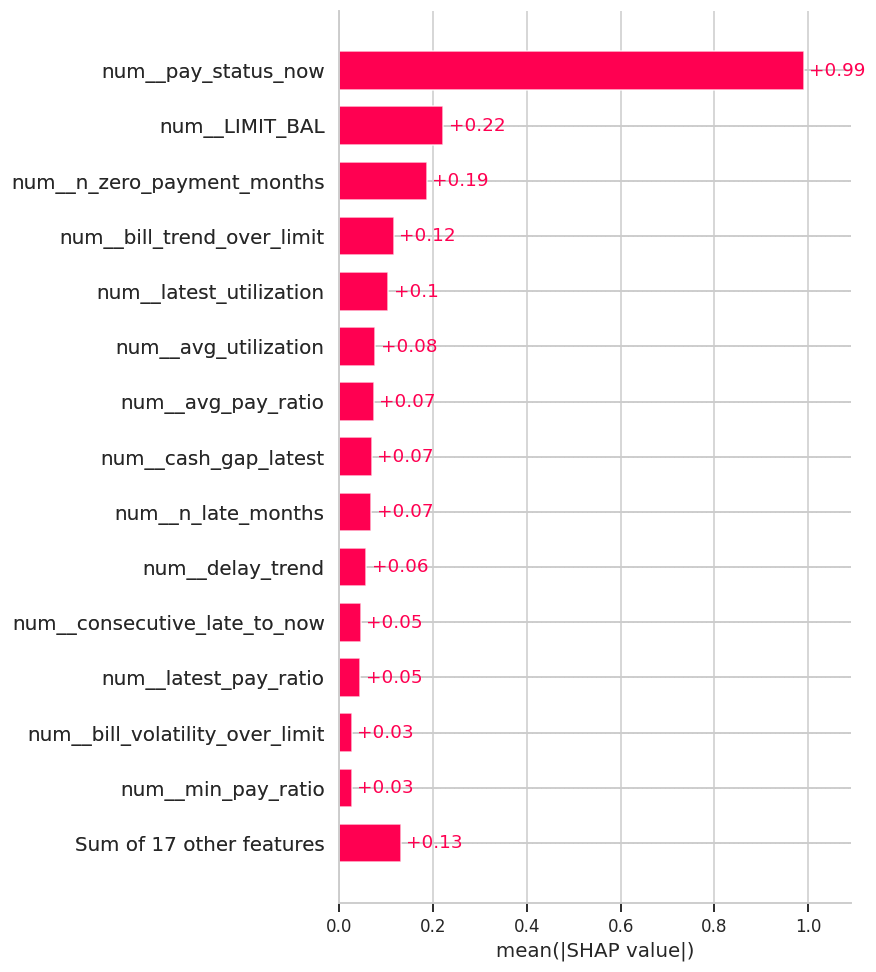

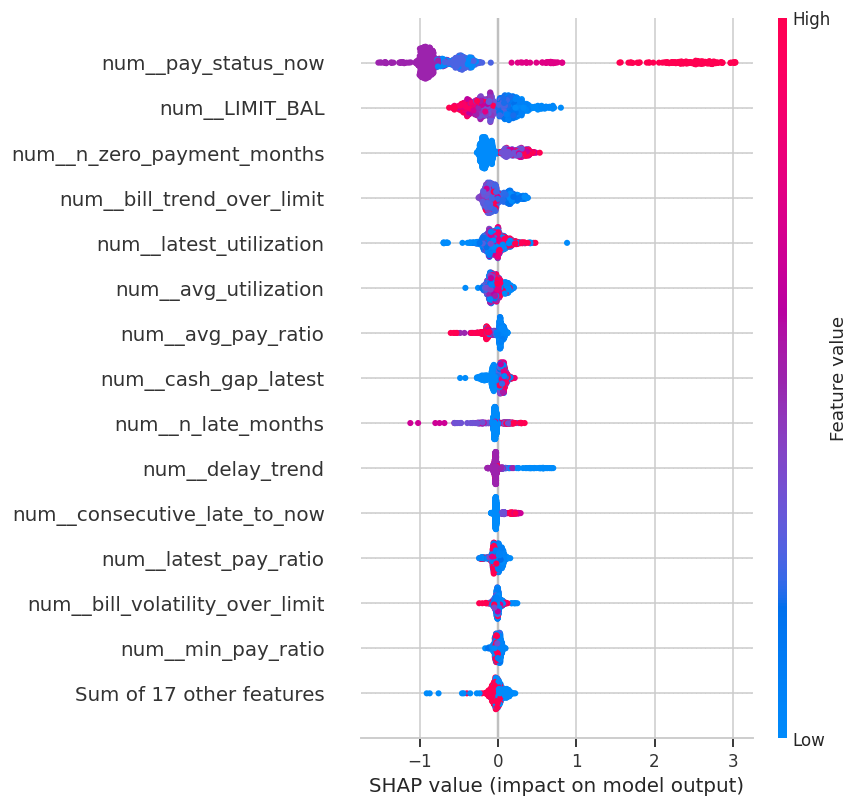


90-day model -- global feature importance:


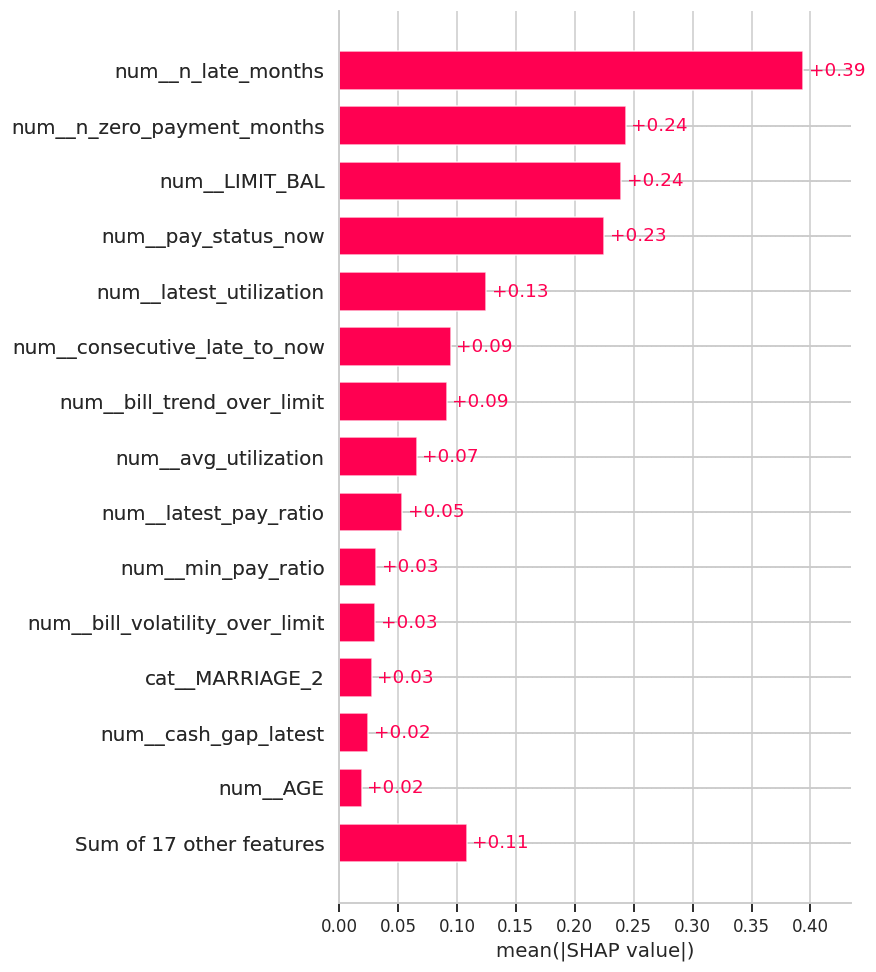

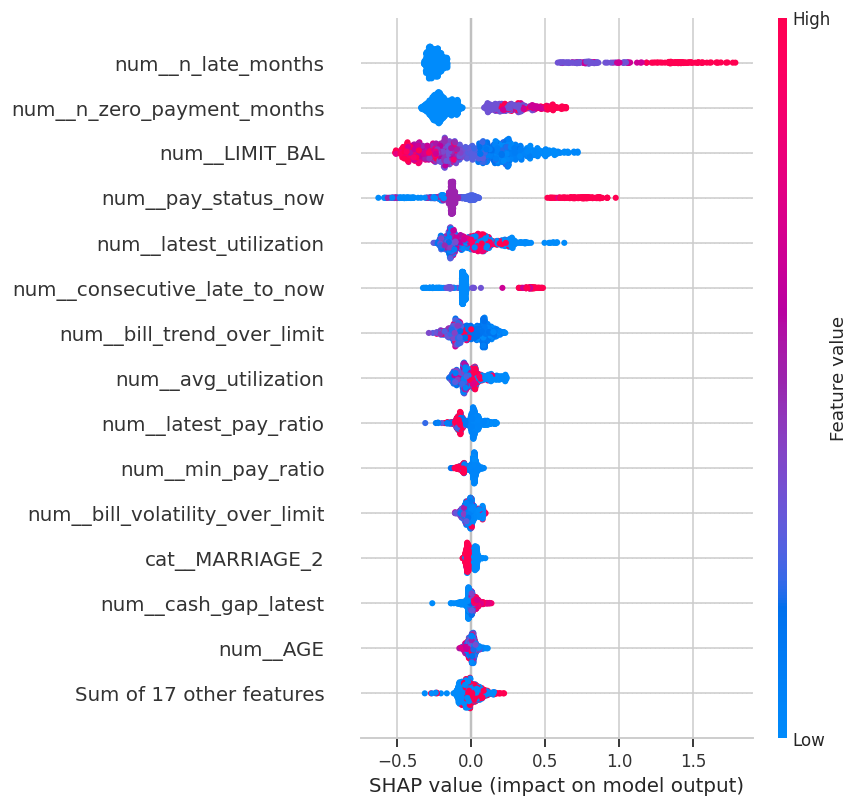

In [123]:
import shap

shap_sample = 1000  # rows per model for the global summary plots; raise for more precision, lower for speed

def shap_values_for(model, pre, X_raw, sample=shap_sample, seed=0):
    Xt = pre.transform(X_raw)
    names = list(pre.get_feature_names_out())
    if len(Xt) > sample:
        idx = np.random.RandomState(seed).choice(len(Xt), sample, replace=False)
        Xt = Xt[idx]
    sv = shap.TreeExplainer(model)(Xt, check_additivity=False)
    sv.feature_names = names
    return sv

sv30 = shap_values_for(model30, pre30, test30["X"])
sv90 = shap_values_for(model90, pre90, test90["X"])

print("30-day model -- global feature importance:")
shap.plots.bar(sv30, max_display=15, show=True)
shap.plots.beeswarm(sv30, max_display=15, show=True)

print("\n90-day model -- global feature importance:")
shap.plots.bar(sv90, max_display=15, show=True)
shap.plots.beeswarm(sv90, max_display=15, show=True)

Highest-risk test client (p=0.981):


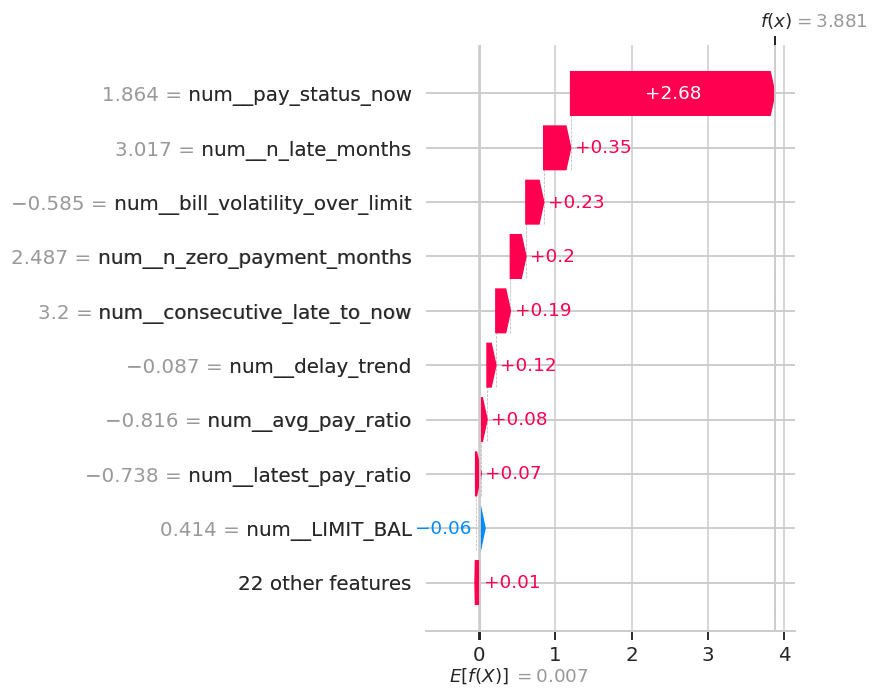

Borderline test client just under the threshold (p=0.298, threshold=0.330):


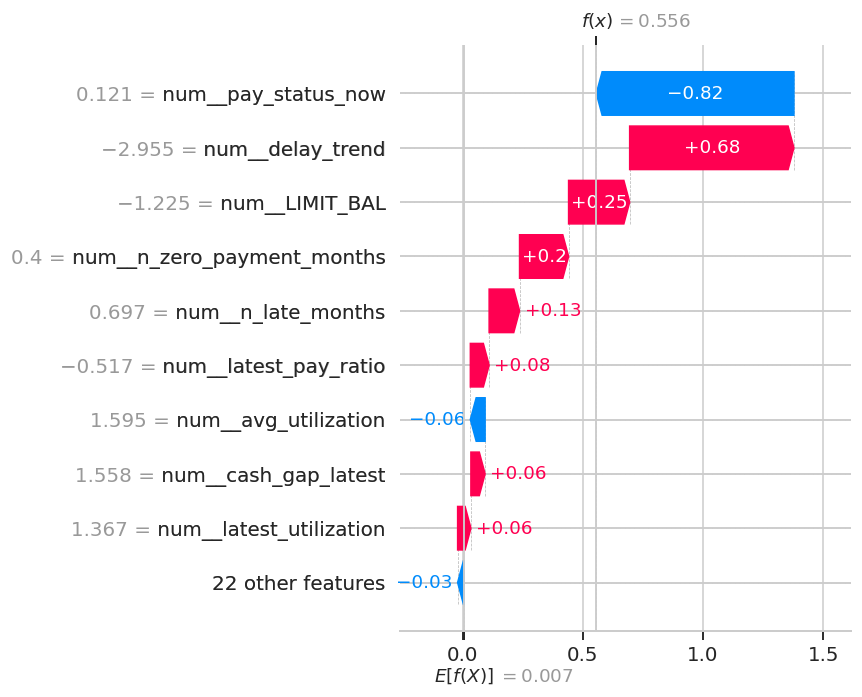

In [124]:
# Local explanation: one example from each side of the 30-day threshold
above = np.where(test30["cal"] >= CHOSEN_THRESH30)[0]
below = np.where(test30["cal"] < CHOSEN_THRESH30)[0]
if len(above) and len(below):
    i_hi = above[np.argmax(test30["cal"][above])]   # highest-risk client
    i_near = below[np.argmin(np.abs(test30["cal"][below] - CHOSEN_THRESH30))]  # borderline client, just under the line

    sv30_local = shap_values_for(model30, pre30, test30["X"].iloc[[i_hi]], sample=1)
    print(f"Highest-risk test client (p={test30['cal'][i_hi]:.3f}):")
    shap.plots.waterfall(sv30_local[0], show=True)

    sv30_local2 = shap_values_for(model30, pre30, test30["X"].iloc[[i_near]], sample=1)
    print(f"Borderline test client just under the threshold (p={test30['cal'][i_near]:.3f}, threshold={CHOSEN_THRESH30:.3f}):")
    shap.plots.waterfall(sv30_local2[0], show=True)

---
## 11) Scoring function
A single entry point that ties sections 8–10 together: given one client's row (same schema as `panel_30` / `panel_90` — `STATIC_COLS` + the engineered `feat_cols`, as of one month), it returns the calibrated probability, the risk flag at the chosen threshold, and the top SHAP contributors for *that specific client* — so a flagged case comes with a reason, not just a number.

**Note on scope**: this scores one already-engineered as-of row (the output of `asof_features`/`build_panel` in section 6), not a raw file — plug it into `build_panel`/`asof_features` first if starting from raw monthly columns. If "the function" you had in mind is a different one (e.g. one that takes the raw wide table directly, or that batch-scores a whole file), tell me and I'll adapt this one instead of guessing further.

In [125]:
def score_client(raw_row: pd.DataFrame, horizon="30", top_k=5):
    """
    raw_row : one-row DataFrame, same columns as panel_30 / panel_90
              (STATIC_COLS + feat_cols) for one client as of one month.
    horizon : "30" or "90".
    Returns: calibrated probability, risk flag at the chosen threshold,
             and the top_k SHAP contributors for this one prediction.
    """
    model, pre, calibrator, threshold = (
        (model30, pre30, calibrator30, CHOSEN_THRESH30) if horizon == "30"
        else (model90, pre90, calibrator90, CHOSEN_THRESH90)
    )
    X = raw_row[NUM_COLS + CAT_COLS].copy()
    X[CAT_COLS] = X[CAT_COLS].astype(str)
    Xt = pre.transform(X)

    raw_p = model.predict_proba(Xt)[:, 1][0]
    cal_p = float(calibrator.predict([raw_p])[0])
    flag = int(cal_p >= threshold)

    sv = shap.TreeExplainer(model)(Xt, check_additivity=False)
    names = pre.get_feature_names_out()
    contrib = pd.Series(sv.values[0], index=names).sort_values(key=np.abs, ascending=False).head(top_k)

    return {"horizon_days": int(horizon), "probability": round(cal_p, 4), "risk_flag": flag,
            "threshold_used": round(threshold, 4), "top_contributors": contrib.round(4).to_dict()}


# example
example = panel_30[panel_30["split"] == "test"].iloc[[0]]
score_client(example, horizon="30")

{'horizon_days': 30,
 'probability': 0.2232,
 'risk_flag': 0,
 'threshold_used': 0.3302,
 'top_contributors': {'num__pay_status_now': -0.7906000018119812,
  'num__delay_trend': 0.6444000005722046,
  'num__n_zero_payment_months': 0.23109999299049377,
  'num__n_late_months': 0.13699999451637268,
  'num__bill_trend_over_limit': -0.0723000019788742}}

---
## 12) (UCI) — Load Artifacts + Unified Scoring Layer
Paste these cells at the END of `Taiwan_full_pipeline_2.ipynb` (after section 11). They need `model30/pre30/calibrator30`, `model90/...`, `CHOSEN_THRESH30/90`, `THRESH30/90`, `test30/test90`, `panel`, `panel_30/90`, `clean` to already exist in memory.

### [UCI] 12.1 Save artifacts (run once)

In [126]:
# ===== TASK 9.1 -- Save the artifacts =====
import joblib, json, datetime, sklearn, xgboost, shap

ARTIFACT_DIR = os.path.join(OUT_DIR, "artifacts_uci")
os.makedirs(ARTIFACT_DIR, exist_ok=True)


def save_uci_artifacts(artifact_dir=ARTIFACT_DIR):
    bundles = {
        "30": dict(model=model30, pre=pre30, calibrator=calibrator30, thr=CHOSEN_THRESH30, cands=THRESH30,
                   asof=sorted(panel_30["asof_month"].unique()), test=test30),
        "90": dict(model=model90, pre=pre90, calibrator=calibrator90, thr=CHOSEN_THRESH90, cands=THRESH90,
                   asof=sorted(panel_90["asof_month"].unique()), test=test90),
    }
    meta = {
        "source": "UCI",
        "created": datetime.datetime.now().isoformat(timespec="seconds"),
        "window_months": int(W),
        "num_cols": list(NUM_COLS), "cat_cols": list(CAT_COLS),
        "static_cols": list(STATIC_COLS), "feat_cols": list(feat_cols),
        "versions": {"sklearn": sklearn.__version__, "xgboost": xgboost.__version__, "shap": shap.__version__},
        "horizons": {},
    }
    for h, b in bundles.items():
        joblib.dump({k: b[k] for k in ("model", "pre", "calibrator")}, os.path.join(artifact_dir, f"uci_{h}d.joblib"))
        meta["horizons"][h] = {
            "threshold": float(b["thr"]),
            "threshold_candidates": {k: float(v) for k, v in b["cands"].items()},
            "valid_asof_months": [int(a) for a in b["asof"]],
            "test_roc_auc": round(float(roc_auc_score(b["test"]["y"], b["test"]["cal"])), 4),
        }
    with open(os.path.join(artifact_dir, "meta.json"), "w") as f:
        json.dump(meta, f, indent=2)
    print("Saved to:", artifact_dir, "->", sorted(os.listdir(artifact_dir)))


save_uci_artifacts()

Saved to: ./artifacts_uci -> ['meta.json', 'uci_30d.joblib', 'uci_90d.joblib']


In [127]:
import shutil
from google.colab import files

shutil.make_archive("artifacts_uci", "zip", ARTIFACT_DIR)
files.download("artifacts_uci.zip")

### [UCI] 12.2 Load artifacts + `UCIScorer` (unified output for 30/90 days)

In [128]:
# ===== TASK 9.2 -- Load artifacts + unified scoring layer =====
import joblib, json


def _norm_cat(v):
    if pd.isna(v):
        return "nan"
    if isinstance(v, (int, float, np.integer, np.floating)) and float(v).is_integer():
        return str(int(v))
    return str(v)


class UCIScorer:
    BAND_EDGES = (0.5, 1.0, 2.0)
    BAND_NAMES = ("Low", "Moderate", "High", "Critical")

    def __init__(self, artifact_dir=ARTIFACT_DIR):
        with open(os.path.join(artifact_dir, "meta.json")) as f:
            self.meta = json.load(f)
        self.num_cols, self.cat_cols = self.meta["num_cols"], self.meta["cat_cols"]
        self.window = self.meta["window_months"]
        self.h = {}
        for hz, info in self.meta["horizons"].items():
            b = joblib.load(os.path.join(artifact_dir, f"uci_{hz}d.joblib"))
            b["threshold"] = info["threshold"]
            b["valid_asof"] = info["valid_asof_months"]
            b["explainer"] = shap.TreeExplainer(b["model"])
            b["names"] = [n.split("__", 1)[-1] for n in b["pre"].get_feature_names_out()]
            self.h[hz] = b

    def features_from_raw(self, wide_df, asof_month):
        return asof_features(_prep(wide_df), asof_month, self.window)

    def _X(self, df):
        need = self.num_cols + self.cat_cols
        miss = [c for c in need if c not in df.columns]
        if miss:
            raise ValueError(f"Missing columns for scoring: {miss}")
        X = df[need].copy()
        for c in self.cat_cols:
            X[c] = X[c].map(_norm_cat)
        return X

    def _band(self, p, thr):
        idx = np.digitize(np.asarray(p) / thr, self.BAND_EDGES)
        return np.array(self.BAND_NAMES)[idx]

    def _check_horizon(self, horizon):
        hz = str(horizon)
        if hz not in self.h:
            raise ValueError(f"horizon must be one of {list(self.h)}")
        return hz

    def score_frame(self, df, horizon="30"):
        hz = self._check_horizon(horizon); b = self.h[hz]
        raw = b["model"].predict_proba(b["pre"].transform(self._X(df)))[:, 1]
        p = b["calibrator"].predict(raw)
        out = pd.DataFrame({"probability": p, "risk_flag": (p >= b["threshold"]).astype(int),
                            "risk_band": self._band(p, b["threshold"])}, index=df.index)
        out.insert(0, "horizon_days", int(hz))
        if "ID" in df.columns:
            out.insert(0, "ID", df["ID"].values)
        return out

    def score_client(self, row, horizon="30", top_k=5):
        hz = self._check_horizon(horizon); b = self.h[hz]
        row = row.iloc[[0]] if isinstance(row, pd.DataFrame) else pd.DataFrame([row])
        Xt = b["pre"].transform(self._X(row))
        p = float(b["calibrator"].predict(b["model"].predict_proba(Xt)[:, 1])[0])
        sv = b["explainer"].shap_values(Xt, check_additivity=False)[0]
        order = np.argsort(-np.abs(sv))[:top_k]
        drivers = []
        for j in order:
            name = b["names"][j]
            drivers.append({"feature": name,
                            "value": (None if name not in row.columns or pd.isna(row[name].iloc[0]) else float(row[name].iloc[0]))
                                     if name in self.num_cols else None,
                            "shap": round(float(sv[j]), 4),
                            "effect": "raises risk" if sv[j] > 0 else "lowers risk"})
        asof = int(row["asof_month"].iloc[0]) if "asof_month" in row.columns else None
        return {"source": "UCI", "horizon_days": int(hz),
                "probability": round(p, 4), "risk_flag": int(p >= b["threshold"]),
                "risk_band": str(self._band([p], b["threshold"])[0]), "threshold": round(b["threshold"], 4),
                "asof_month": asof, "validated_window": (asof in b["valid_asof"]) if asof is not None else None,
                "top_drivers": drivers}

    def score_both(self, row, top_k=5):
        return {hz: self.score_client(row, hz, top_k) for hz in self.h}


scorer = UCIScorer()
print("Loaded horizons:", list(scorer.h), "| thresholds:", {k: round(v["threshold"], 3) for k, v in scorer.h.items()})

Loaded horizons: ['30', '90'] | thresholds: {'30': 0.33, '90': 0.302}


### [UCI] 12.3 Round-trip test + demo

In [129]:
# ===== TASK 9.3 -- Round-trip test =====
for hz, pnl, ref in (("30", panel_30, test30), ("90", panel_90, test90)):
    te = pnl[pnl["split"] == "test"].reset_index(drop=True)
    got = scorer.score_frame(te, hz)["probability"].values
    assert np.allclose(got, ref["cal"], atol=1e-6), f"{hz}-day: loaded artifacts do NOT match the in-memory models"
    print(f"{hz}-day: OK -- {len(got):,} test rows reproduced, ROC-AUC = {roc_auc_score(ref['y'], got):.4f}")

a = 6
raw_feat = scorer.features_from_raw(clean.head(200), a)
panel_feat = panel[(panel["asof_month"] == a) & (panel["ID"].isin(clean.head(200)["ID"]))].reset_index(drop=True)
assert np.allclose(raw_feat[NUM_COLS].values.astype(float), panel_feat[NUM_COLS].values.astype(float), equal_nan=True)
print("raw -> features path matches the panel: OK")

demo = panel_30[panel_30["split"] == "test"].iloc[[0]]
res = scorer.score_both(demo)
print(json.dumps(res, indent=2, default=str))
display(scorer.score_frame(panel_30[panel_30["split"] == "test"].head(5), "30"))

30-day: OK -- 24,000 test rows reproduced, ROC-AUC = 0.8549


90-day: OK -- 12,000 test rows reproduced, ROC-AUC = 0.7778
raw -> features path matches the panel: OK
{
  "30": {
    "source": "UCI",
    "horizon_days": 30,
    "probability": 0.2232,
    "risk_flag": 0,
    "risk_band": "Moderate",
    "threshold": 0.3302,
    "asof_month": 3,
    "validated_window": true,
    "top_drivers": [
      {
        "feature": "pay_status_now",
        "value": 0.0,
        "shap": -0.7906,
        "effect": "lowers risk"
      },
      {
        "feature": "delay_trend",
        "value": -1.0,
        "shap": 0.6444,
        "effect": "raises risk"
      },
      {
        "feature": "n_zero_payment_months",
        "value": 1.0,
        "shap": 0.2311,
        "effect": "raises risk"
      },
      {
        "feature": "n_late_months",
        "value": 1.0,
        "shap": 0.137,
        "effect": "raises risk"
      },
      {
        "feature": "bill_trend_over_limit",
        "value": 4.5833333333333334e-05,
        "shap": -0.0723,
        "effect":

,ID,horizon_days,probability,risk_flag,risk_band
1,2,30,0.2232,0,Moderate
11,12,30,0.1821,0,Moderate
14,15,30,0.0235,0,Low
17,18,30,0.0460,0,Low
20,21,30,0.0462,0,Low


---
## 13) Scenario engine

**Question answered:** *"If this client did X, how would their risk change?"*

**How it works.** A scenario edits the **raw monthly columns** of one client (payments, bill, credit limit) for months **<= the as-of month only**, the as-of features are recomputed with `features_from_raw`, and the result is scored with `UCIScorer`. Every scenario is compared with the unchanged client (`Baseline`).

| Step | What it does |
|---|---|
| 13.1 | Scenario library (`SCENARIOS`: name -> function, parameters, description) |
| 13.2 | `ScenarioEngine`: `run`, `sweep_payment`, `min_payment_to_clear` |
| 13.3 | Demo on a flagged client + sanity tests |

**Rules built into the engine**
- Scenarios work on a **copy**; the input row is never modified.
- A scenario may not touch any month after the as-of month (asserted for every run), same no-future-leak principle as section 6.
- Paying the previous bill in full also sets that month's payment status to `-1` (paid duly), because amount and status describe the same event in this dataset. This is an **assumption** and can be changed in `sc_pay_ratio`.

**How to read the results.** The scenarios are *what-if questions asked to the model*, not causal guarantees: the model learned that clients who behave like this tend to have lower risk, not that changing the behaviour will change the outcome. Tree models are not perfectly smooth, so the payment sweep can show small jumps; read the whole curve, not a single point.

### [UCI] 13.1 -- Scenario library

In [130]:
def _c(prefix, m):
    # month index (1 = Apr ... 6 = Sep) -> raw column name, e.g. _c("BILL_AMT", 6) = "BILL_AMT1" (Sep)
    return f"{prefix}{7 - m}"


def sc_baseline(r, a):
    pass


def sc_pay_ratio(r, a, ratio=1.0):
    prev_bill = max(float(r[_c("BILL_AMT", a - 1)].iloc[0]), 0.0)
    r[_c("PAY_AMT", a)] = ratio * prev_bill
    status = float(r[_c("PAY_", a)].iloc[0])
    if ratio >= 1 and status >= 0:
        r[_c("PAY_", a)] = -1


def sc_miss_payment(r, a):
    r[_c("PAY_AMT", a)] = 0.0
    status = float(r[_c("PAY_", a)].iloc[0])
    r[_c("PAY_", a)] = min(status + 1, 8) if status >= 1 else 1


def sc_cut_bill(r, a, pct=0.3):
    r[_c("BILL_AMT", a)] = float(r[_c("BILL_AMT", a)].iloc[0]) * (1 - pct)


def sc_raise_limit(r, a, factor=1.5):
    r["LIMIT_BAL"] = float(r["LIMIT_BAL"].iloc[0]) * factor


def sc_pay_more_window(r, a, factor=2.0, w=W):
    for m in range(a - w + 1, a + 1):
        r[_c("PAY_AMT", m)] = float(r[_c("PAY_AMT", m)].iloc[0]) * factor


SCENARIOS = {
    "Baseline":                  (sc_baseline,        {},                "Client as-is"),
    "Pay previous bill in full": (sc_pay_ratio,       {"ratio": 1.0},    "Pays 100% of last month's bill this month"),
    "Pay 50% of previous bill":  (sc_pay_ratio,       {"ratio": 0.5},    "Pays half of last month's bill"),
    "Pay only 10% (minimum)":    (sc_pay_ratio,       {"ratio": 0.1},    "Pays a token 10% of last month's bill"),
    "Miss this month's payment": (sc_miss_payment,    {},                "Pays nothing and the delay counter goes up by one"),
    "Cut latest bill by 30%":    (sc_cut_bill,        {"pct": 0.3},      "Spends 30% less this month"),
    "Raise credit limit +50%":   (sc_raise_limit,     {"factor": 1.5},   "Bank increases the limit by 50% (utilization drops)"),
    "Pay 2x usual (all window)": (sc_pay_more_window, {"factor": 2.0},   "Doubles payments in every month of the window"),
}
print("Scenarios:", list(SCENARIOS))

Scenarios: ['Baseline', 'Pay previous bill in full', 'Pay 50% of previous bill', 'Pay only 10% (minimum)', "Miss this month's payment", 'Cut latest bill by 30%', 'Raise credit limit +50%', 'Pay 2x usual (all window)']


### [UCI] 13.2 -- Scenario engine

In [131]:
class ScenarioEngine:
    def __init__(self, scorer, scenarios=SCENARIOS):
        self.scorer, self.scenarios = scorer, scenarios

    def _apply(self, wide_row, a, fn, kw):
        before = wide_row.iloc[[0]].reset_index(drop=True)
        r = before.copy()
        fn(r, a, **kw)
        for m in range(a + 1, 7):
            for p in ("PAY_", "BILL_AMT", "PAY_AMT"):
                c = _c(p, m)
                assert (r[c].iloc[0] == before[c].iloc[0]) or (pd.isna(r[c].iloc[0]) and pd.isna(before[c].iloc[0])), \
                    f"scenario edited month {m} > as-of {a}"
        return r

    def run(self, wide_row, asof_month, horizons=("30", "90"), scenarios=None):
        scenarios = scenarios or self.scenarios
        rows = [self._apply(wide_row, asof_month, fn, kw) for fn, kw, _ in scenarios.values()]
        feats = self.scorer.features_from_raw(pd.concat(rows, ignore_index=True), asof_month)
        out = []
        for hz in horizons:
            s = self.scorer.score_frame(feats, hz).reset_index(drop=True)
            s.insert(0, "scenario", list(scenarios))
            base = s.loc[s["scenario"] == "Baseline"].iloc[0] if "Baseline" in scenarios else s.iloc[0]
            s["change_pp"] = (s["probability"] - base["probability"]) * 100
            s["flag_change"] = np.select([(s["risk_flag"] == 0) & (base["risk_flag"] == 1),
                                          (s["risk_flag"] == 1) & (base["risk_flag"] == 0)],
                                         ["flagged -> safe", "safe -> flagged"], default="")
            s["validated_window"] = asof_month in self.scorer.h[hz]["valid_asof"]
            out.append(s.drop(columns=[c for c in ("ID",) if c in s.columns]))
        return pd.concat(out, ignore_index=True)

    def sweep_payment(self, wide_row, asof_month, horizon="30", ratios=np.round(np.arange(0, 1.51, 0.1), 2)):
        sc = {f"pay {r:.0%}": (sc_pay_ratio, {"ratio": float(r)}, "") for r in ratios}
        res = self.run(wide_row, asof_month, horizons=(horizon,), scenarios=sc)
        res.insert(1, "ratio", list(ratios))
        return res[["ratio", "probability", "risk_flag", "risk_band"]]

    def min_payment_to_clear(self, wide_row, asof_month, horizon="30"):
        sw = self.sweep_payment(wide_row, asof_month, horizon)
        ok = sw[sw["risk_flag"] == 0]
        return None if ok.empty else float(ok["ratio"].iloc[0])


engine = ScenarioEngine(scorer)
print("Scenario engine ready.")

Scenario engine ready.


### [UCI] 13.3 Demo + sanity tests

Picks a client who is **flagged** at the 30-day horizon in Sep, runs all scenarios, and checks:
1. `Baseline` equals scoring the panel row directly,
2. the input row was not modified,
3. no scenario edited a month after the as-of month (asserted inside the engine).

Then it prints the payment sweep and the smallest payment that clears the flag. Use the 30-day horizon for the demo: the 90-day model was not trained on the Sep window.

In [132]:
a = 6
te_ids = panel_30[(panel_30["split"] == "test") & (panel_30["asof_month"] == a)]
flagged = scorer.score_frame(te_ids, "30").query("risk_flag == 1")
cid = flagged["ID"].iloc[0]
row = clean[clean["ID"] == cid]
print(f"Client ID {cid}, as-of {MONTH_NAME[a]}")

res = engine.run(row, a)
display(res.round(4))

direct = scorer.score_frame(panel_30[(panel_30["ID"] == cid) & (panel_30["asof_month"] == a)], "30")["probability"].iloc[0]
base30 = res[(res["scenario"] == "Baseline") & (res["horizon_days"] == 30)]["probability"].iloc[0]
assert abs(direct - base30) < 1e-9, "baseline scenario does not match direct scoring"
assert row.equals(clean[clean["ID"] == cid]), "engine modified the input row"
print("tests OK: baseline == direct score, input untouched, no future months edited")

sw = engine.sweep_payment(row, a, "30")
display(sw.round(4))
print("Smallest payment (x last bill) that clears the 30-day flag:", engine.min_payment_to_clear(row, a, "30"))

Client ID 55, as-of Sep


,scenario,horizon_days,probability,risk_flag,risk_band,change_pp,flag_change,validated_window
0,Baseline,30,0.5533,1,High,0.0000,,True
1,Pay previous bill in full,30,0.0321,0,Low,-52.1240,flagged -> safe,True
2,Pay 50% of previous bill,30,0.4698,1,High,-8.3566,,True
3,Pay only 10% (minimum),30,0.5533,1,High,0.0000,,True
4,Miss this month's payment,30,0.4634,1,High,-8.9919,,True
5,Cut latest bill by 30%,30,0.5533,1,High,0.0000,,True
6,Raise credit limit +50%,30,0.5533,1,High,0.0000,,True
7,Pay 2x usual (all window),30,0.5533,1,High,0.0000,,True
8,Baseline,90,0.5152,1,High,0.0000,,False
9,Pay previous bill in full,90,0.0835,0,Low,-43.1710,flagged -> safe,False


tests OK: baseline == direct score, input untouched, no future months edited


,ratio,probability,risk_flag,risk_band
0,0.0000,0.4698,1,High
1,0.1000,0.5533,1,High
2,0.2000,0.5533,1,High
3,0.3000,0.5533,1,High
4,0.4000,0.4698,1,High
5,0.5000,0.4698,1,High
6,0.6000,0.4698,1,High
7,0.7000,0.4698,1,High
8,0.8000,0.4698,1,High
9,0.9000,0.4698,1,High


Smallest payment (x last bill) that clears the 30-day flag: 1.0


### [UCI] 13.4 -- Population check

> Add blockquote



In [133]:
def scenario_population_check(engine, df_wide, ids, a, horizon="30"):
    rows = []
    for cid in ids:
        r = engine.run(df_wide[df_wide["ID"] == cid], a, horizons=(horizon,))
        r["ID"] = cid
        rows.append(r)
    allr = pd.concat(rows, ignore_index=True)
    allr = allr[allr["scenario"] != "Baseline"]
    return (allr.groupby("scenario")
                .agg(clients=("ID", "nunique"),
                     mean_change_pp=("change_pp", "mean"),
                     median_change_pp=("change_pp", "median"),
                     pct_risk_down=("change_pp", lambda s: 100 * (s < -0.5).mean()),
                     pct_risk_up=("change_pp", lambda s: 100 * (s > 0.5).mean()),
                     pct_no_change=("change_pp", lambda s: 100 * (s.abs() <= 0.5).mean()),
                     pct_flagged_to_safe=("flag_change", lambda s: 100 * (s == "flagged -> safe").mean()))
                .round(1).sort_values("mean_change_pp"))


a = 6
pool = panel_30[(panel_30["split"] == "test") & (panel_30["asof_month"] == a)]
flagged_ids = scorer.score_frame(pool, "30").query("risk_flag == 1")["ID"].values
ids = np.random.RandomState(0).choice(flagged_ids, size=min(200, len(flagged_ids)), replace=False)
print(f"Checking {len(ids)} flagged clients (as-of {MONTH_NAME[a]}, 30-day):")
display(scenario_population_check(engine, clean, ids, a, "30"))

Checking 200 flagged clients (as-of Sep, 30-day):


,clients,mean_change_pp,median_change_pp,pct_risk_down,pct_risk_up,pct_no_change,pct_flagged_to_safe
scenario,,,,,,,
Pay previous bill in full,200,-46.9000,-49.4000,100.0000,0.0000,0.0000,92.5000
Pay 50% of previous bill,200,-10.5000,-10.7000,78.0000,2.5000,19.5000,10.5000
Pay only 10% (minimum),200,-3.7000,-2.7000,58.5000,11.0000,30.5000,8.0000
Pay 2x usual (all window),200,-1.4000,0.0000,38.0000,12.0000,50.0000,2.0000
Raise credit limit +50%,200,-0.9000,0.0000,36.5000,20.0000,43.5000,5.0000
Cut latest bill by 30%,200,0.2000,0.0000,24.5000,27.5000,48.0000,0.5000
Miss this month's payment,200,17.2000,5.4000,21.5000,65.5000,13.0000,0.0000


### [UCI] 13.5 -- Why did a scenario move the risk?

In [134]:
def explain_scenario(engine, wide_row, a, scenario_name, horizon="30", top=8):
    fn, kw, _ = engine.scenarios[scenario_name]
    both = pd.concat([engine._apply(wide_row, a, sc_baseline, {}), engine._apply(wide_row, a, fn, kw)], ignore_index=True)
    f = engine.scorer.features_from_raw(both, a)
    cols = engine.scorer.num_cols
    d = pd.DataFrame({"before": f.loc[0, cols].astype(float), "after": f.loc[1, cols].astype(float)})
    d["delta"] = d["after"] - d["before"]
    p = engine.scorer.score_frame(f, horizon)["probability"].values
    print(f"{scenario_name}: probability {p[0]:.4f} -> {p[1]:.4f}")
    return d[d["delta"].abs() > 1e-12].sort_values("delta", key=np.abs, ascending=False).head(top)


display(explain_scenario(engine, row, a, "Miss this month's payment"))
display(explain_scenario(engine, row, a, "Pay previous bill in full"))

Miss this month's payment: probability 0.5533 -> 0.4634


,before,after,delta
pay_status_now,2.0000,3.0000,1.0000
max_delay,2.0000,3.0000,1.0000
n_zero_payment_months,0.0000,1.0000,1.0000
delay_trend,1.0000,1.5000,0.5000
latest_pay_ratio,0.0457,0.0000,-0.0457
min_pay_ratio,0.0457,0.0000,-0.0457
avg_pay_ratio,0.0502,0.0273,-0.0229
cash_gap_latest,0.2226,0.2333,0.0107


Pay previous bill in full: probability 0.5533 -> 0.0321


,before,after,delta
pay_status_now,2.0000,-1.0000,-3.0000
max_delay,2.0000,0.0000,-2.0000
n_late_months,1.0000,0.0000,-1.0000
delay_trend,1.0000,0.0000,-1.0000
consecutive_late_to_now,1.0000,0.0000,-1.0000
n_low_pay_months,2.0000,1.0000,-1.0000
latest_pay_ratio,0.0457,1.0000,0.9543
avg_pay_ratio,0.0502,0.5273,0.4771


In [135]:
tr = panel_30[panel_30["split"] == "train"]
display(tr.pivot_table(index="pay_status_now", columns="asof_name", values="target_30", aggfunc="mean").round(3))
display(tr.pivot_table(index="pay_status_now", columns="asof_name", values="target_30", aggfunc="size"))

asof_name,Aug,Jul,Jun,Sep
pay_status_now,,,,
-2.0000,0.3280,0.0160,0.0180,0.1270
-1.0000,0.1270,0.0550,0.0580,0.1660
0.0000,0.0550,0.0720,0.0740,0.1280
1.0000,1.0000,1.0000,1.0000,0.3440
2.0000,0.8980,0.6760,0.7120,0.6940
3.0000,0.8540,0.8020,0.8880,0.7670
4.0000,0.9620,0.9330,0.9620,0.6550
5.0000,0.8570,1.0000,0.9640,0.4440
6.0000,1.0000,1.0000,1.0000,0.6000


asof_name,Aug,Jul,Jun,Sep
pay_status_now,,,,
-2.0000,3030,3270,3477,2198
-1.0000,4845,4733,4531,4527
0.0000,12573,12636,13180,11781
1.0000,25,3,2,3000
2.0000,3145,3049,2542,2138
3.0000,254,192,143,245
4.0000,78,60,53,58
5.0000,21,16,28,18
6.0000,11,19,3,10


## [UCI] 14. Generate client Recommendation

In [136]:
def generate_client_recommendation(row, asof_month):
    """
    Takes the client's raw data and determines the appropriate financial advice
    to reduce their default probability, based on the scenario engine.
    """
    # First convert the raw row into the engineered features required, before sending it to the Scorer
    engineered_row = scorer.features_from_raw(row, asof_month)

    # 1. Compute the client's current risk level (baseline)
    current_score = scorer.score_client(engineered_row, horizon="30")

    if current_score["risk_flag"] == 0:
        return {
            "status": "Safe",
            "message": "The client's credit position is stable; no additional recommendations are needed at this time."
        }

    # 2. If the client is at risk, use the Scenario Engine to find the minimum payment ratio required
    min_ratio = engine.min_payment_to_clear(row, asof_month, horizon="30")

    # Get the previous month's bill value (BILL_AMT for the previous month) to find the actual amount
    # September (6) -> August's bill is BILL_AMT2
    prev_bill_col = f"BILL_AMT{7 - (asof_month - 1)}"
    prev_bill_value = max(float(row[prev_bill_col].iloc[0]), 0.0)

    if min_ratio is not None:
        required_payment = min_ratio * prev_bill_value
        recommendation_msg = (
            f"The client is advised to pay at least {min_ratio:.0%} of the previous month's bill. "
            f"The amount that must be paid immediately to reduce the risk is: {required_payment:,.2f} dollars/pounds."
        )
    else:
        recommendation_msg = "Based on the client's behavior, adjusting current payments alone is not enough. The client is advised to reduce credit usage and cut upcoming bills by 30%."

    return {
        "status": "Action Required",
        "current_risk_band": current_score["risk_band"],
        "current_probability": current_score["probability"],
        "recommendation": recommendation_msg
    }

# Test the engine on the famous client #55 in September
print("===== Recommendation Engine (Task 11) =====")
rec_result = generate_client_recommendation(row, a)
print(f"Client's current status: {rec_result['current_risk_band']} (probability: {rec_result['current_probability']:.2%})")
print(f"Smart recommendation: {rec_result['recommendation']}")

===== Recommendation Engine (Task 11) =====
Client's current status: High (probability: 55.33%)
Smart recommendation: The client is advised to pay at least 100% of the previous month's bill. The amount that must be paid immediately to reduce the risk is: 34,993.00 dollars/pounds.


## [UCI] 15. Calculate saving coverage

In [137]:
def calculate_savings_coverage(row, client_savings=15000):
    """
    Calculates how many months the client's savings can cover, based on their
    average bill (avg_bill), and determines how well they can withstand
    financial shocks.
    """
    # Compute the average bill across the six months (using your colleague's ready-made function)
    client_features = client_level_features(row, TW_PAY)
    avg_bill = max(float(client_features["avg_bill"].iloc[0]), 1.0)  # avoid division by zero

    # 1. How many months do the savings last?
    months_covered = client_savings / avg_bill

    # 2. Do the savings cover a sudden financial shock (e.g. 15,000)?
    shock_threshold = 15000
    can_cover_shock = client_savings >= shock_threshold

    return {
        "client_savings": client_savings,
        "months_covered": round(months_covered, 1),
        "can_cover_15k_shock": "Yes" if can_cover_shock else "No",
        "savings_status": "Safe" if months_covered >= 3 else "Risk (savings insufficient for emergencies)"
    }

# Try the calculations alongside the recommendations
print("\n===== Savings & Shock Analysis (Task 12) =====")
savings_result = calculate_savings_coverage(row, client_savings=20000)
print(f"Client's current savings: {savings_result['client_savings']:,}")
print(f"These savings cover their bills for: {savings_result['months_covered']} month(s).")
print(f"Do the savings cover a sudden financial shock of 15,000? {savings_result['can_cover_15k_shock']}")


===== Savings & Shock Analysis (Task 12) =====
Client's current savings: 20,000
These savings cover their bills for: 0.7 month(s).
Do the savings cover a sudden financial shock of 15,000? Yes


In [138]:
def display_comprehensive_risk_card(row, asof_month):
    """
    Translates SHAP outputs and the time horizon into very simple human language
    for presenting to the judging committee.
    """
    # First convert the raw row into the engineered features required, before sending it to score_both
    engineered_row = scorer.features_from_raw(row, asof_month)

    # 1. Get the Scorer's ready-made outputs for both the 30-day and 90-day horizons
    both_horizons = scorer.score_both(engineered_row, top_k=3)

    print("="*60)
    print(f" 📊 Comprehensive Risk Check Card for Client ID: {int(row['ID'].iloc[0])} ")
    print("="*60)

    # Dictionary translating feature names into simple readable English
    feature_translation = {
        "max_delay": "Longest payment delay",
        "n_late_months": "Number of past late months",
        "latest_utilization": "Current credit limit utilization",
        "avg_pay_ratio": "Average share of bills paid",
        "LIMIT_BAL": "Credit limit granted on the card",
        "delay_trend": "Client's trend toward late payment"
    }

    for hz, score_data in both_horizons.items():
        print(f"\n🔹 [{hz}-day horizon forecast]:")
        print(f"   - Risk score: {score_data['probability']:.2%}")
        print(f"   - Risk band: {score_data['risk_band']}")
        print(f"   - System decision: {'⚠️ High-risk client (rejected)' if score_data['risk_flag'] == 1 else '✅ Safe client (accepted)'}")

        print("   - Main reasons behind this result (SHAP explanation):")
        for driver in score_data["top_drivers"]:
            feat_name = driver["feature"]
            # Use the readable name if it is in the dictionary, otherwise print the original name
            readable_name = feature_translation.get(feat_name, feat_name)
            effect_text = "raises risk 📈" if driver["effect"] == "raises risk" else "lowers risk 📉"
            print(f"     * {readable_name} -> {effect_text} (impact: {driver['shap']})")

    print("="*60)

# Run the comprehensive display card for the committee
display_comprehensive_risk_card(row, asof_month=a)

 📊 Comprehensive Risk Check Card for Client ID: 55 

🔹 [30-day horizon forecast]:
   - Risk score: 55.33%
   - Risk band: High
   - System decision: ⚠️ High-risk client (rejected)
   - Main reasons behind this result (SHAP explanation):
     * pay_status_now -> raises risk 📈 (impact: 2.5116)
     * Number of past late months -> lowers risk 📉 (impact: -0.2226)
     * bill_trend_over_limit -> lowers risk 📉 (impact: -0.1776)

🔹 [90-day horizon forecast]:
   - Risk score: 51.52%
   - Risk band: High
   - System decision: ⚠️ High-risk client (rejected)
   - Main reasons behind this result (SHAP explanation):
     * Number of past late months -> raises risk 📈 (impact: 0.8833)
     * pay_status_now -> raises risk 📈 (impact: 0.7516)
     * consecutive_late_to_now -> lowers risk 📉 (impact: -0.189)


---
# PART C — Darra AI dashboard
The interface from `finalui.html`, wired to the **trained models**. Switch between **GMSC** (24-month) and **UCI Taiwan** (30 / 90-day) with the top buttons, and between English and Arabic with **ع / EN**. Moving the client-profile sliders updates the risk gauge, drivers, stress tests, best-action recommendations, savings coverage and the sensitivity curve live.

**How the link works.** A browser page cannot call the Python models on every slider move, so section C.1 *distils* them: it scores thousands of profiles with the real models (`predict_risk_batch` for GMSC, `UCIScorer` for 30/90-day), fits a smooth log-odds curve per UI factor (plus pairwise interactions), and injects those curves and the **real flag thresholds** into the page. The page stays a single standalone file, and the C.1 table reports how closely it tracks the models. Re-run C.1 after retraining.

### C.1 Fit the dashboard to the trained models (run Parts A and B first)

In [139]:
import json, numpy as np, pandas as pd
from scipy.stats import spearmanr
from IPython.display import display

_rng = np.random.default_rng(42)
_lg  = lambda z: 1 / (1 + np.exp(-z))
_logit = lambda p: np.log(np.clip(p, 1e-4, 1 - 1e-4) / (1 - np.clip(p, 1e-4, 1 - 1e-4)))
_PAIRS = [(i, j) for i in range(6) for j in range(i + 1, 6)]

def _design(Z, knots_z):
    """Additive curve per factor (linear + hinge terms) + pairwise interactions, on z-scored factors."""
    cols = []
    for i in range(6):
        cols.append(Z[:, i]); cols += [np.maximum(0, Z[:, i] - k) for k in knots_z[i]]
    cols += [Z[:, i] * Z[:, j] for i, j in _PAIRS]
    return np.column_stack(cols)

def _fit(X, p_real, thr, name, knots_x):
    """log-odds ~ b + sum_i f_i(x_i) + sum_ij w_ij z_i z_j  (same form is evaluated in the page)."""
    mu, sd = X.mean(0), X.std(0) + 1e-9
    Z = (X - mu) / sd; kz = [[(k - mu[i]) / sd[i] for k in knots_x[i]] for i in range(6)]
    z = _logit(p_real); A = np.c_[np.ones(len(X)), _design(Z, kz)]
    tr = _rng.random(len(X)) < 0.8
    coef = np.linalg.solve(A[tr].T @ A[tr] + 1e-2 * np.eye(A.shape[1]) * np.r_[0, np.ones(A.shape[1] - 1)], A[tr].T @ z[tr])
    p_ui = _lg(A[~tr] @ coef); p_m = p_real[~tr]
    rep = {"dashboard": name, "R2 (log-odds)": 1 - ((z[~tr] - A[~tr] @ coef) ** 2).sum() / ((z[~tr] - z[~tr].mean()) ** 2).sum(),
           "rank corr": spearmanr(p_ui, p_m)[0], "mean |dp|": np.abs(p_ui - p_m).mean(),
           "flag agreement": ((p_ui >= thr) == (p_m >= thr)).mean(), "threshold": thr}
    a, pos = [], 1
    for i in range(6):
        n = 1 + len(kz[i]); a.append([float(v) for v in coef[pos:pos + n]]); pos += n
    pairs = [[i, j, float(coef[pos + t])] for t, (i, j) in enumerate(_PAIRS)]
    return {"b": float(coef[0]), "mu": [float(v) for v in mu], "sd": [float(v) for v in sd],
            "k": [[float(v) for v in k] for k in kz], "a": a, "p": pairs, "thr": float(thr)}, rep

COEF, REPORT, N = {}, [], 6000

# ---------------- GMSC (Part A models) ----------------
try:
    inc = np.exp(_rng.uniform(np.log(2000), np.log(60000), N))
    F = pd.DataFrame({"age": _rng.integers(18, 90, N), "income": inc,
                      "debt": np.minimum(inc * _rng.uniform(0, 1.3, N), 40000),
                      "util": _rng.uniform(0, 100, N), "late": _rng.choice(7, N, p=[.6, .2, .1, .04, .03, .02, .01]),
                      "dep": _rng.choice(9, N, p=[.35, .2, .2, .12, .06, .04, .02, .006, .004])})
    raw = pd.DataFrame([build_raw_customer(age=r.age, monthly_income=r.income, monthly_debt_payments=r.debt,
                                           card_balance=r.util / 100 * 10000, card_limit=10000,
                                           late_30_59=int(r.late), dependents=int(r.dep),
                                           open_credit_lines=8, real_estate_loans=1)   # typical constants for factors the UI does not expose
                        for r in F.itertuples()])
    p = predict_risk_batch(raw)
    X = np.c_[F.late, F.util / 100, np.minimum(F.debt / F.income, 1.5), np.log(F.income / 8000), F.age, F.dep]
    kn = [[1, 2, 4], [.25, .5, .75], [.2, .4, .8], [-.5, 0, .7], [30, 45, 60], [1, 2, 4]]
    COEF["gmsc"], rep = _fit(X, p, float(THRESHOLD), "GMSC 24-month", kn); REPORT.append(rep)
except NameError as e:
    print("GMSC part not run yet ->", e)

# ---------------- UCI Taiwan (Part B models) ----------------
def _tw_frame(F, a):
    """UI profile -> raw wide rows (months 1=Apr ... 6=Sep; column index j = 7 - month)."""
    n = len(F); r = pd.concat([clean.iloc[[0]]] * n, ignore_index=True)
    r["ID"] = np.arange(n); r["LIMIT_BAL"] = F.limit.values; r["AGE"] = F.age.values
    cur = np.where(F.delay.values > 0, F.delay.values, np.where(F.payRatio.values >= 100, -1, 0))
    late_prev = np.maximum(F.lateM.values - (F.delay.values > 0), 0)
    for m in range(1, 7):
        j = 7 - m
        r[f"BILL_AMT{j}"] = F.bill.values
        r[f"PAY_AMT{j}"]  = F.payRatio.values / 100 * F.bill.values       # paid share of the previous bill
        r[f"PAY_{j}"]     = cur if m >= a else np.where(late_prev >= (a - m), 1, 0)
    return r

try:
    for hz, key in (("30", "tw30"), ("90", "tw90")):
        a = max(scorer.h[hz]["valid_asof"])                              # as-of month the horizon is validated on
        lim = np.exp(_rng.uniform(np.log(10000), np.log(500000), N))
        dly = _rng.choice(7, N, p=[.6, .2, .08, .05, .03, .02, .02])
        F = pd.DataFrame({"age": _rng.integers(21, 75, N), "limit": lim, "bill": np.minimum(lim * _rng.uniform(0, 1.3, N), 500000),
                          "payRatio": _rng.uniform(0, 100, N), "delay": dly})
        F["lateM"] = np.clip(np.maximum(_rng.choice(7, N, p=[.5, .2, .1, .08, .06, .04, .02]), (dly > 0).astype(int)), 0, a)
        p = scorer.score_frame(scorer.features_from_raw(_tw_frame(F, a), a), hz)["probability"].values
        X = np.c_[F.delay, F.lateM, F.bill / F.limit, F.payRatio / 100, np.log(F.limit / 100000), F.age]
        kn = [[1, 2, 4], [1, 2, 4], [.2, .5, 1.0], [.1, .4, .8], [-1.2, -.3, .5], [30, 40, 55]]
        COEF[key], rep = _fit(X, p, scorer.h[hz]["threshold"], f"UCI {hz}-day (as-of month {a})", kn); REPORT.append(rep)
except NameError as e:
    print("UCI part not run yet ->", e)

display(pd.DataFrame(REPORT).set_index("dashboard").round(3))

# JavaScript that swaps the demo scorers for the fitted ones (injected into the page in the next cell)
DARRA_OVERRIDE = ""
if COEF:
    DARRA_OVERRIDE = "const COEF=" + json.dumps(COEF) + ";\n"
    DARRA_OVERRIDE += """const FIT=(C,x,nm)=>{const z=x.map((v,i)=>(v-C.mu[i])/C.sd[i]),f=z.map((v,i)=>C.a[i][0]*v+C.k[i].reduce((s,k,j)=>s+C.a[i][j+1]*Math.max(0,v-k),0));C.p.forEach(q=>{const t=q[2]*z[q[0]]*z[q[1]];f[q[0]]+=t/2;f[q[1]]+=t/2});const t=nm.map((q,i)=>[q[0],q[1],f[i]]);return{p:lg(C.b+f.reduce((a,v)=>a+v,0)),t}};
"""
    if "gmsc" in COEF:
        DARRA_OVERRIDE += """DS.gmsc.hz[0].thr=COEF.gmsc.thr;
DS.gmsc.score=function(s){return FIT(COEF.gmsc,[s.late,s.util/100,Math.min(s.debt/s.income,1.5),Math.log(s.income/8000),s.age,s.dep],[['Late payments','تأخر السداد'],['Credit utilization','استخدام الائتمان'],['Debt ratio','نسبة الدين'],['Income','الدخل'],['Age','العمر'],['Dependents','المعالون']])};
"""
    if "tw30" in COEF and "tw90" in COEF:
        DARRA_OVERRIDE += """DS.tw.hz[0].thr=COEF.tw30.thr;DS.tw.hz[1].thr=COEF.tw90.thr;
DS.tw.score=function(s,h){return FIT(h?COEF.tw90:COEF.tw30,[s.delay,s.lateM,s.bill/s.limit,s.payRatio/100,Math.log(s.limit/100000),s.age],[['Payment delay','تأخر السداد'],['Late months','أشهر التأخر'],['Utilization','الاستخدام'],['Payment ratio','نسبة السداد'],['Credit limit','الحد الائتماني'],['Age','العمر']])};
"""
    print("Dashboard will use:", ", ".join(COEF))
else:
    print("No model found -> the dashboard keeps its built-in demo scoring.")

,R2 (log-odds),rank corr,mean |dp|,flag agreement,threshold
dashboard,,,,,
GMSC 24-month,0.9010,0.9530,0.0200,0.9070,0.0600
UCI 30-day (as-of month 6),0.9510,0.9760,0.0310,0.9550,0.3300
UCI 90-day (as-of month 4),0.9470,0.9770,0.0310,0.9500,0.3020


Dashboard will use: gmsc, tw30, tw90


In [140]:
# Render the Darra AI UI inside the notebook (also saved as darra_ui.html). Uses the fitted weights from C.1 when available.
import html as _html
from IPython.display import HTML, display

UI_HTML = r'''<!DOCTYPE html>
<html lang="en"><head><meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1, viewport-fit=cover">
<title>Darra AI – درع</title>
<style>
:root{color-scheme:dark;--bg:#0a080b;--card:#131014;--in:#0b090c;--ln:rgba(255,255,255,.12);--tx:#f4eff4;--mu:#9b909b;--ac:#d9a7d4;--ac2:#8f5f8b;--ok:#4ade80;--bad:#f87171;--wn:#fbbf24;box-sizing:border-box;padding-top:env(safe-area-inset-top,0px);padding-bottom:env(safe-area-inset-bottom,0px)}
@media (prefers-color-scheme:light){:root:not([data-theme="dark"]){color-scheme:light;--bg:#f3eef3;--card:#fff;--in:#f6f1f6;--ln:rgba(0,0,0,.12);--tx:#1b161b;--mu:#6d636d;--ac:#9b5c96;--ac2:#d9a7d4;--ok:#16a34a;--bad:#dc2626;--wn:#d97706}}
:root[data-theme="dark"]{color-scheme:dark}
html{scroll-padding-top:env(safe-area-inset-top,0px)}
*{box-sizing:border-box}body{margin:0;background:radial-gradient(900px 500px at 70% -10%,color-mix(in srgb,var(--ac) 18%,transparent),transparent),var(--bg);color:var(--tx);font:14px/1.45 system-ui,-apple-system,"Segoe UI",Tahoma,sans-serif}
.app{display:grid;grid-template-columns:220px 1fr;gap:14px;padding:14px;max-width:1320px;margin:auto}
.card{background:linear-gradient(160deg,rgba(255,255,255,.05),rgba(0,0,0,.25)),var(--card);border:1px solid var(--ln);border-radius:20px;padding:18px;min-width:0}
.side{display:flex;flex-direction:column;gap:6px;position:sticky;top:14px;height:calc(100vh - 28px)}
.logo{font-weight:700;font-size:17px;margin-bottom:18px;display:flex;gap:8px;align-items:center}.logo b{color:var(--ac)}
.side a{color:var(--tx);text-decoration:none;padding:11px 14px;border-radius:12px;opacity:.8}.side a.on,.side a:hover{background:linear-gradient(90deg,var(--ac2),transparent);opacity:1}
.side small{margin-top:auto;color:var(--mu);font-size:11px}
h1{font-size:26px;font-weight:500;margin:0}h1 em{color:var(--ac);font-style:normal}.sub{color:var(--mu);font-size:12px}
h3{font-size:15px;font-weight:500;margin:0 0 12px;display:flex;justify-content:space-between;align-items:center;gap:8px}
.top{display:flex;justify-content:space-between;align-items:center;gap:12px;flex-wrap:wrap;margin-bottom:14px}
.pills{display:flex;gap:6px;flex-wrap:wrap}.pill{border:1px solid var(--ln);background:var(--in);color:var(--tx);border-radius:99px;padding:9px 18px;cursor:pointer;font:inherit}
.pill.on{background:linear-gradient(135deg,var(--ac2),var(--ac));color:#140f14;border-color:transparent;font-weight:600}.pill.sm{padding:5px 12px;font-size:12px}
.g{display:grid;gap:14px;margin-bottom:14px}.g3{grid-template-columns:1fr 1fr 1fr}.g2{grid-template-columns:1.1fr 1fr}
.big{font-size:34px;font-weight:600}.chip{display:inline-block;border-radius:99px;padding:3px 11px;font-size:12px;font-weight:600}
.High,.critical{background:rgba(248,113,113,.18);color:var(--bad)}.Medium,.thin{background:rgba(251,191,36,.18);color:var(--wn)}.Low,.safe{background:rgba(74,222,128,.18);color:var(--ok)}
.row{display:flex;justify-content:space-between;align-items:center;gap:8px;padding:8px 0;border-bottom:1px solid var(--ln)}.row:last-child{border:0}
.fld{margin-bottom:9px}.fld label{display:flex;justify-content:space-between;font-size:12px;color:var(--mu)}.fld label b{color:var(--tx);font-weight:500}
input[type=range]{width:100%;accent-color:var(--ac)}
.bar{height:7px;border-radius:9px;background:var(--in);overflow:hidden;flex:1}.bar i{display:block;height:100%;border-radius:9px}
.drv{display:grid;grid-template-columns:120px 1fr 44px;gap:8px;align-items:center;font-size:12px;margin-bottom:8px}.drv span:last-child{text-align:end;color:var(--mu)}
.up{background:var(--bad)}.dn{background:var(--ok)}
.note{color:var(--mu);font-size:11px;margin-top:8px}.d{font-weight:600;font-size:12px}
.rec{border:1px solid var(--ln);border-radius:14px;padding:11px;margin-bottom:8px;background:var(--in)}
svg text{fill:var(--mu);font-size:10px}
[dir=rtl] .side a{text-align:right}
@media(max-width:1000px){.app{grid-template-columns:1fr}.side{position:static;height:auto;flex-direction:row;flex-wrap:wrap}.side small{display:none}.logo{margin:0 10px 0 0}.g3,.g2{grid-template-columns:1fr}}
</style></head><body>
<div class="app" id="app">
<aside class="card side"><div class="logo"><b>◈</b> Darra AI <span style="color:var(--mu)">درع</span></div>
<a class="on" href="#s0" id="n0"></a><a href="#s1" id="n1"></a><a href="#s2" id="n2"></a><a href="#s3" id="n3"></a><small id="foot"></small></aside>
<main>
<div class="top"><div><h1 id="hi"></h1><div class="sub" id="sub"></div></div>
<div class="pills"><button class="pill" data-ds="gmsc"></button><button class="pill" data-ds="tw"></button><button class="pill sm" id="lang">ع</button></div></div>
<div class="g g3" id="s0">
<div class="card"><h3><span id="t_score"></span><span class="pills" id="hzs"></span></h3><div style="text-align:center"><svg viewBox="0 0 200 118" width="100%" style="max-width:260px"><path d="M20 100A80 80 0 0 1 180 100" fill="none" stroke="var(--in)" stroke-width="14" stroke-linecap="round"/><path id="arc" d="M20 100A80 80 0 0 1 180 100" fill="none" stroke="var(--ac)" stroke-width="14" stroke-linecap="round" stroke-dasharray="0 252"/></svg><div class="big" id="pv" style="margin-top:-52px"></div><div style="margin-top:14px"><span class="chip" id="lvl"></span></div><div class="sub" id="thr" style="margin-top:8px"></div></div></div>
<div class="card" id="s3"><h3 id="t_drv"></h3><div id="drv"></div><div class="note" id="n_drv"></div></div>
<div class="card"><h3 id="t_prof"></h3><div id="ctl"></div></div></div>
<div class="g g3">
<div class="card" id="s1"><h3 id="t_sc"></h3><div id="sc"></div></div>
<div class="card" id="s2"><h3 id="t_rec"></h3><div id="rec"></div></div>
<div class="card"><h3 id="t_sav"></h3><div id="sav"></div></div></div>
<div class="card"><h3 id="t_sw"></h3><svg id="ch" viewBox="0 0 640 210" width="100%"></svg></div>
</main></div>
<script>
let ds='gmsc',lang='en',hz=0,SH=15000,S={};
const T=(e,a)=>lang==='ar'?a:e,F=n=>Math.round(n).toLocaleString('en-US'),P=x=>(x*100).toFixed(1)+'%',cl=(x,a,b)=>Math.min(b,Math.max(a,x));
const L=(p,t)=>p>=t?'High':p>=t/2?'Medium':'Low',LA={High:'مرتفع',Medium:'متوسط',Low:'منخفض',critical:'حرج',thin:'ضعيف',safe:'آمن'};
const lg=(z)=>1/(1+Math.exp(-z));
const DS={
gmsc:{name:['Give Me Some Credit','Give Me Some Credit'],tag:['24-month structural risk','المخاطر الهيكلية لمدة 24 شهراً'],
 hz:[{l:['24 months','24 شهراً'],thr:.15}],
 f:[['age','Age','العمر',18,90,1,38],['income','Monthly income','الدخل الشهري',2000,60000,500,12000],['debt','Monthly debt payments','أقساط الديون الشهرية',0,40000,250,5000],['util','Card utilization %','استخدام البطاقة %',0,100,1,60],['late','Late payments (30–59d)','تأخر السداد (30–59 يوم)',0,6,1,0],['dep','Dependents','عدد المعالين',0,8,1,2],['fixed','Fixed living costs','المصاريف الثابتة',0,30000,250,4000]],
 oblig:s=>s.debt,
 score(s){const dr=s.debt/s.income,t=[['Late payments','تأخر السداد',.75*s.late],['Credit utilization','استخدام الائتمان',2*s.util/100-.8],['Debt ratio','نسبة الدين',1.6*Math.min(dr,1.5)-.5],['Income','الدخل',-.9*Math.log(s.income/8000)],['Age','العمر',-.025*(s.age-45)],['Dependents','المعالون',.12*(s.dep-1)]];return{p:lg(-2.35+t.reduce((a,x)=>a+x[2],0)),t}},
 sc:[['Income drops 20%','انخفاض الدخل 20%',s=>{s.income*=.8}],['New loan (+1,500/mo)','قرض جديد (+1,500 شهرياً)',s=>{s.debt+=1500}],['Higher bills (+800/mo)','فواتير أعلى (+800 شهرياً)',s=>{s.debt+=800}],['One month late','تأخر شهر واحد',s=>{s.late+=1}],['Medical emergency 15,000','طوارئ طبية 15,000',s=>{s.debt+=15000/12},15000]],
 lev:[['Cut card utilization','خفض استخدام البطاقة',[5,10,15,20,30,40,50,60],(s,a)=>{s.util=Math.max(0,s.util-a)},a=>'-'+a+' pts',a=>'-'+a+' نقطة',1],['Reduce monthly debt','خفض الأقساط الشهرية',[5,10,15,20,30,40,50],(s,a)=>{s.debt*=1-a/100},a=>'-'+a+'%',a=>'-'+a+'%',1.3],['Raise income','زيادة الدخل',[5,10,15,20,30,40,60],(s,a)=>{s.income*=1+a/100},a=>'+'+a+'%',a=>'+'+a+'%',1.6]],
 sw:['util',0,100,'Card utilization %','استخدام البطاقة %'],fixedNote:['Late history, age and dependents are fixed factors.','سجل التأخر والعمر والمعالون عوامل ثابتة.']},
tw:{name:['UCI Taiwan Credit Card','UCI تايوان — بطاقات الائتمان'],tag:['30 / 90-day monthly tracking','تتبع شهري لـ 30 / 90 يوماً'],
 hz:[{l:['30 days','30 يوماً'],thr:.35,b:-1.9,w:1},{l:['90 days','90 يوماً'],thr:.40,b:-1.45,w:1.15}],
 f:[['age','Age','العمر',21,75,1,35],['limit','Credit limit','الحد الائتماني',10000,500000,5000,120000],['bill','Latest statement','آخر كشف حساب',0,500000,2500,60000],['payRatio','Paid of last bill %','المسدد من الفاتورة السابقة %',0,100,5,40],['delay','Current delay (months)','التأخر الحالي (شهور)',0,6,1,1],['lateM','Late months (of last 6)','أشهر التأخر (من آخر 6)',0,6,1,2],['fixed','Fixed living costs','المصاريف الثابتة',0,30000,250,0]],
 oblig:s=>s.bill,
 score(s,h){const H=DS.tw.hz[h],u=s.bill/s.limit,t=[['Payment delay','تأخر السداد',.62*H.w*s.delay],['Late months','أشهر التأخر',.18*s.lateM],['Utilization','الاستخدام',1.3*(u-.4)],['Payment ratio','نسبة السداد',1.4*(.5-s.payRatio/100)],['Credit limit','الحد الائتماني',-.35*Math.log(s.limit/100000)],['Age','العمر',-.01*(s.age-35)]];return{p:lg(H.b+t.reduce((a,x)=>a+x[2],0)),t}},
 sc:[['Pay previous bill in full','سداد الفاتورة السابقة كاملة',s=>{s.payRatio=100;s.delay=0}],['Pay 50% of previous bill','سداد 50% من الفاتورة',s=>{s.payRatio=50}],['Pay only 10% (minimum)','سداد 10% فقط (الحد الأدنى)',s=>{s.payRatio=10}],['Miss this month’s payment','عدم السداد هذا الشهر',s=>{s.payRatio=0;s.delay=Math.max(1,s.delay+1);s.lateM=Math.min(6,s.lateM+1)}],['Cut latest bill by 30%','خفض الفاتورة 30%',s=>{s.bill*=.7}],['Raise credit limit +50%','رفع الحد الائتماني 50%',s=>{s.limit*=1.5}],['Medical emergency 15,000','طوارئ طبية 15,000',s=>{s.bill+=15000},15000]],
 lev:[['Pay more of last bill','سداد المزيد من الفاتورة',[10,20,30,40,50,60,70,80,90,100],(s,a)=>{s.payRatio=Math.max(s.payRatio,a);if(a>=100)s.delay=0},a=>'pay '+a+'%',a=>'سدد '+a+'%',1],['Cut spending','خفض الإنفاق',[10,20,30,40,50,60],(s,a)=>{s.bill*=1-a/100},a=>'-'+a+'%',a=>'-'+a+'%',1.2],['Ask for a higher limit','طلب رفع الحد',[25,50,75,100],(s,a)=>{s.limit*=1+a/100},a=>'+'+a+'%',a=>'+'+a+'%',1.5]],
 sw:['payRatio',0,100,'Share of last bill paid %','المسدد من الفاتورة %'],fixedNote:['Past delays and age are fixed factors.','التأخر السابق والعمر عوامل ثابتة.']}};
const D=()=>DS[ds],pr=(s,h=hz)=>D().score(s,h),thr=()=>D().hz[hz].thr;
const cp=o=>JSON.parse(JSON.stringify(o));
function load(){S={};D().f.forEach(f=>S[f[0]]=f[6]);hz=0}
function ctl(){$('ctl').innerHTML=D().f.map(f=>`<div class="fld"><label><span>${T(f[1],f[2])}</span><b id="v_${f[0]}">${F(S[f[0]])}</b></label><input type="range" min="${f[3]}" max="${f[4]}" step="${f[5]}" value="${S[f[0]]}" data-k="${f[0]}"></div>`).join('')+`<div class="fld"><label><span>${T('Liquid savings','السيولة المتاحة')}</span><b id="v_sav">${F(SH)}</b></label><input type="range" min="0" max="200000" step="1000" value="${SH}" data-k="sav"></div>`}
const $=id=>document.getElementById(id);
function txt(){const a=lang==='ar';document.documentElement.lang=lang;$('app').dir=a?'rtl':'ltr';
$('hi').innerHTML=T('Welcome to <em>Darra AI</em>','مرحباً بك في <em>درع</em>');$('sub').textContent=T('Financial early-warning · '+D().tag[0],'نظام إنذار مبكر مالي · '+D().tag[1]);
['Dashboard','Stress test','Best action','Explain'].forEach((e,i)=>$('n'+i).textContent=T(e,['لوحة التحكم','اختبار الضغط','أفضل إجراء','التفسير'][i]));
document.querySelectorAll('[data-ds]').forEach(b=>{b.textContent=DS[b.dataset.ds].name[+a];b.classList.toggle('on',b.dataset.ds===ds)});
$('foot').textContent=T('Demo scoring engine · mirrors the notebook logic','محرك تقييم تجريبي · يحاكي منطق النوتبوك');
$('t_score').textContent=T('Risk score','درجة المخاطر');$('t_drv').textContent=T('Why? (SHAP-style drivers)','لماذا؟ (محركات SHAP)');$('t_prof').textContent=T('Client profile','ملف العميل');
$('t_sc').textContent=T('Stress test · what-if','اختبار الضغط · ماذا لو');$('t_rec').textContent=T('Best action optimizer','محسّن أفضل إجراء');$('t_sav').textContent=T('Savings coverage','تغطية المدخرات');$('t_sw').textContent=T('Sensitivity · '+D().sw[3],'الحساسية · '+D().sw[4]);
$('hzs').innerHTML=D().hz.length>1?D().hz.map((h,i)=>`<button class="pill sm ${i===hz?'on':''}" data-hz="${i}">${h.l[+a]}</button>`).join(''):`<span class="sub">${D().hz[0].l[+a]}</span>`;}
function update(){const a=lang==='ar',r=pr(S),th=thr(),lv=L(r.p,th);
$('arc').setAttribute('stroke-dasharray',(251.3*Math.min(1,r.p))+' 252');$('pv').textContent=P(r.p);
$('lvl').className='chip '+lv;$('lvl').textContent=a?LA[lv]:lv;$('thr').textContent=T('Flag threshold ','حد الإنذار ')+P(th)+(r.p>=th?T(' · flagged',' · مُنبَّه'):'');
const mx=Math.max(...r.t.map(x=>Math.abs(x[2])),.01);
$('drv').innerHTML=[...r.t].sort((x,y)=>Math.abs(y[2])-Math.abs(x[2])).map(x=>`<div class="drv"><span>${a?x[1]:x[0]}</span><div class="bar"><i class="${x[2]>0?'up':'dn'}" style="width:${Math.abs(x[2])/mx*100}%"></i></div><span>${x[2]>0?'+':''}${x[2].toFixed(2)}</span></div>`).join('');
$('n_drv').textContent=T('Red raises risk, green lowers it (log-odds). Associations, not causes.','الأحمر يرفع المخاطر والأخضر يخفضها. ارتباطات وليست أسباباً.');
$('sc').innerHTML=D().sc.map(x=>{const s=cp(S);x[2](s);const q=pr(s).p,d=q-r.p;return`<div class="row"><span>${a?x[1]:x[0]}</span><span><span class="d" style="color:var(--${d>0?'bad':'ok'})">${d>0?'▲':'▼'} ${Math.abs(d*100).toFixed(1)}</span> <span class="sub">→ ${P(q)}</span></span></div>`}).join('')+`<div class="note">${T('Change in risk, percentage points','التغيّر في المخاطر بالنقاط المئوية')}</div>`;
// recommendations
let out='';if(r.p<th)out=`<div class="rec"><span class="chip Low">${T('Safe','آمن')}</span> ${T('Below the flag threshold. No action required.','أقل من حد الإنذار. لا حاجة لإجراء.')}</div>`;
else{const R=D().lev.map(v=>{const i=v[2].findIndex(g=>{const s=cp(S);v[3](s,g);return pr(s).p<th});return{v,i,e:i<0?9:(i+1)/v[2].length*v[6]}}).sort((x,y)=>x.e-y.e);
out=R.map((x,k)=>{const v=x.v;if(x.i<0)return`<div class="rec" style="opacity:.6"><b>${a?v[1]:v[0]}</b><div class="sub">${T('Not enough alone – combine with another action.','لا يكفي وحده – اجمعه مع إجراء آخر.')}</div></div>`;const g=v[2][x.i],s=cp(S);v[3](s,g);return`<div class="rec"><b>${k===0?'★ ':''}${a?v[1]:v[0]}</b>: ${a?v[5](g):v[4](g)}<div class="sub">${P(r.p)} → ${P(pr(s).p)}</div></div>`}).join('')+`<div class="note">${T(D().fixedNote[0],D().fixedNote[1])}</div>`}
$('rec').innerHTML=out;
// savings
const sh=Math.max(...D().sc.map(x=>x[3]||0),0)||15000,ob=D().oblig(S)+S.fixed,run=SH/Math.max(ob,1),cov=SH/sh,st=(v,c,t)=>v<c?'critical':v<t?'thin':'safe',s1=st(run,1,3),s2=st(cov,1,2),rk={critical:0,thin:1,safe:2},w=rk[s1]<rk[s2]?s1:s2;
$('sav').innerHTML=`<div class="row"><span>${T('Runway (months)','مدة التغطية (شهور)')}</span><span><b>${run.toFixed(1)}</b> <span class="chip ${s1}">${a?LA[s1]:s1}</span></span></div><div class="row"><span>${T('Covers a '+F(sh)+' shock','تغطي صدمة '+F(sh))}</span><span><b>${cov.toFixed(1)}×</b> <span class="chip ${s2}">${a?LA[s2]:s2}</span></span></div><div class="row"><span>${T('Savings after shock','المدخرات بعد الصدمة')}</span><b>${F(SH-sh)}</b></div><div class="row"><span>${T('Overall','الإجمالي')}</span><span class="chip ${w}">${a?LA[w]:w}</span></div><div class="note">${T('Rule-based (not model-based): runway = savings ÷ (fixed + debt). Cuts: 1 / 3 months, 1× / 2× shock.','قائم على قواعد: المدة = المدخرات ÷ (ثابت + ديون). الحدود: 1 / 3 شهور، 1× / 2× الصدمة.')}</div>`;
chart(r.p,th)}
function chart(p0,th){const [k,lo,hi]=D().sw,N=20,pts=[];for(let i=0;i<=N;i++){const x=lo+(hi-lo)*i/N,s=cp(S);s[k]=x;pts.push([x,pr(s).p])}
const W=640,H=210,l=40,b=26,t=14,r=12,ym=Math.max(th*1.4,...pts.map(q=>q[1]))*1.08,X=x=>l+(x-lo)/(hi-lo)*(W-l-r),Y=y=>t+(1-y/ym)*(H-t-b);
const ln=pts.map((q,i)=>(i?'L':'M')+X(q[0]).toFixed(1)+' '+Y(q[1]).toFixed(1)).join(''),cx=X(S[k]),cy=Y(p0);
let g='';for(let i=0;i<=4;i++){const y=ym*i/4;g+=`<line x1="${l}" x2="${W-r}" y1="${Y(y)}" y2="${Y(y)}" stroke="var(--ln)"/><text x="${l-6}" y="${Y(y)+3}" text-anchor="end">${(y*100).toFixed(0)}%</text>`}
for(let i=0;i<=5;i++){const x=lo+(hi-lo)*i/5;g+=`<text x="${X(x)}" y="${H-8}" text-anchor="middle">${Math.round(x)}</text>`}
$('ch').innerHTML=`<defs><linearGradient id="gr" x1="0" y1="0" x2="0" y2="1"><stop offset="0" stop-color="var(--ac)" stop-opacity=".4"/><stop offset="1" stop-color="var(--ac)" stop-opacity="0"/></linearGradient></defs>${g}<path d="${ln}L${X(hi)} ${Y(0)}L${X(lo)} ${Y(0)}Z" fill="url(#gr)"/><path d="${ln}" fill="none" stroke="var(--ac)" stroke-width="2.2"/><line x1="${l}" x2="${W-r}" y1="${Y(th)}" y2="${Y(th)}" stroke="var(--bad)" stroke-dasharray="4 4"/><text x="${W-r}" y="${Y(th)-4}" text-anchor="end" style="fill:var(--bad)">${T('threshold','الحد')}</text><line x1="${cx}" x2="${cx}" y1="${cy}" y2="${H-b}" stroke="var(--ac)" stroke-dasharray="3 3"/><circle cx="${cx}" cy="${cy}" r="6" fill="#f6d6f2" stroke="var(--ac)" stroke-width="3"/><text x="${Math.min(cx,W-90)}" y="${Math.max(cy-12,12)}" style="fill:var(--tx);font-size:11px">${T('now','الآن')} ${P(p0)}</text>`}
document.addEventListener('input',e=>{const k=e.target.dataset.k;if(!k)return;const v=+e.target.value;if(k==='sav'){SH=v;$('v_sav').textContent=F(v)}else{S[k]=v;$('v_'+k).textContent=F(v)}update()});
document.addEventListener('click',e=>{const c=e.target.closest('button');if(!c)return;if(c.dataset.ds&&c.dataset.ds!==ds){ds=c.dataset.ds;load();location.hash='d-'+ds}else if(c.dataset.hz)hz=+c.dataset.hz;else if(c.id==='lang'){lang=lang==='en'?'ar':'en';c.textContent=lang==='en'?'ع':'EN'}else return;txt();ctl();update()});
const h0=location.hash.slice(1);if(h0==='d-tw')ds='tw';load();txt();ctl();update();
</script></body></html>
'''

if globals().get("DARRA_OVERRIDE"):
    _anchor = "const D=()=>DS[ds]"
    assert _anchor in UI_HTML
    UI_HTML = (UI_HTML.replace(_anchor, DARRA_OVERRIDE + _anchor)
               .replace("Demo scoring engine · mirrors the notebook logic", "Fitted to the trained XGBoost models")
               .replace("محرك تقييم تجريبي · يحاكي منطق النوتبوك", "مُعايَر على موديلات XGBoost المدرّبة"))

with open("darra_ui.html", "w", encoding="utf-8") as _f:
    _f.write(UI_HTML)

def show_ui(dataset="gmsc", height=1150):
    """dataset: 'gmsc' (24-month) or 'tw' (30/90-day). The language and dataset can also be switched inside the UI."""
    page = UI_HTML.replace("if(h0==='d-tw')ds='tw';", "ds='tw';") if dataset == "tw" else UI_HTML
    display(HTML(f'<iframe srcdoc="{_html.escape(page, quote=True)}" width="100%" height="{height}" '
                 f'style="border:0;border-radius:14px;background:#0a080b"></iframe>'))

show_ui("gmsc")